In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter
import matplotlib
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize, LogNorm
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from scipy.ndimage import gaussian_filter1d
import math
import seaborn as sns
import scipy.stats as stats
import collections
import os
import json
import urllib.request
import ast
from scipy.stats import pearsonr
from pathlib import Path
import itertools
from itertools import repeat
import re
import colorsys
from matplotlib.lines import Line2D
import glob
import cytoflow as flow
import fcsparser
import FlowCal
%config InlineBackend.figure_format='retina'
matplotlib.rcParams['pdf.fonttype'] = 42

# Color Palette
n = 256  
c = 0.4
base_cmap = plt.get_cmap("Greens")  
colors = (1. - c) * base_cmap(np.linspace(0., 1., n)) + c * np.ones((n, 4)) 
pastel_cmap = mcolors.LinearSegmentedColormap.from_list("PastelGreens", colors, N=n)
norm = mcolors.Normalize(vmin=0, vmax=1)

## Getting the relevant files:

In [ ]:
import os
import re
import shutil
import zipfile
import requests

doi_url = "https://doi.org/10.5281/zenodo.24081939"
output_base_dir = "data"

match = re.search(r"zenodo\.(\d+)", doi_url)
if not match:
    raise ValueError(f"Could not extract Zenodo record ID from: {doi_url}")

record_id = match.group(1)
api_url = f"https://zenodo.org/api/records/{record_id}"

headers = {"User-Agent": "Mozilla/5.0 (Python Zenodo Downloader)"}
params = {"access_token": ACCESS_TOKEN} if ACCESS_TOKEN else {}

print(f"Fetching file list from Zenodo Record {record_id}...")
response = requests.get(api_url, headers=headers, params=params, allow_redirects=True)
response.raise_for_status()
record_data = response.json()

os.makedirs(output_base_dir, exist_ok=True)

files = record_data.get("files", [])
zip_files = [f for f in files if f.get("key", "").lower().endswith(".zip")]

if not zip_files:
    print("No .zip files found in this Zenodo record.")

for file_info in zip_files:
    filename = file_info["key"] 
    folder_name = os.path.splitext(filename)[0] 
    target_folder = os.path.join(output_base_dir, folder_name)
    temp_zip_path = os.path.join(output_base_dir, filename)


    download_url = (
        file_info.get("links", {}).get("content")
        or file_info.get("links", {}).get("self")
        or f"https://zenodo.org/records/{record_id}/files/{filename}?download=1"
    )

    print(f"\nDownloading '{filename}'...")
    with requests.get(download_url, headers=headers, params=params, stream=True) as r:
        r.raise_for_status()
        with open(temp_zip_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024): 
                if chunk:
                    f.write(chunk)

    print(f"Extracting into '{target_folder}/'...")
    os.makedirs(target_folder, exist_ok=True)

    with zipfile.ZipFile(temp_zip_path, "r") as zf:
        zf.extractall(target_folder)

    os.remove(temp_zip_path)


    macosx_dir = os.path.join(target_folder, "__MACOSX")
    if os.path.exists(macosx_dir):
        shutil.rmtree(macosx_dir)

    extracted_items = os.listdir(target_folder)
    nested_same_dir = os.path.join(target_folder, folder_name)
    if len(extracted_items) == 1 and os.path.isdir(nested_same_dir):
        for item in os.listdir(nested_same_dir):
            shutil.move(os.path.join(nested_same_dir, item), target_folder)
        os.rmdir(nested_same_dir)

    print(f"Done: {target_folder}/")

print("\nAll zip archives downloaded and extracted successfully!")

In [2]:
# 1. Load Background Data
d12_system_data = pd.read_pickle('d12_Fusion_system.gz')
WT_d12 = pd.read_pickle('WT_d12_strains.gz')
Repeats = pd.read_pickle('experimental_repeats.gz')
Flocculation = pd.read_pickle('flocculation_results.gz')
msn2_dbd_repeats = pd.read_pickle('N_term_dbd_repeats.gz')
msn2_dbd_c_repeats = pd.read_pickle('C_term_dbd_repeats.gz')
wt_system_repeats = pd.read_pickle('WT_system_repeats.gz')

all_TFs = pd.read_csv('tfs_sumprom.csv')
all_TFs.index = d12_system_data.index

gp = pd.read_csv('geneinfo_params.csv', index_col=0)
df_for_sp = pd.read_csv('frame_for_spcalc.csv', index_col=4)

# 2. Map Original High-Resolution Promoter Signals (for Metaprofiles)
folder_path = os.getcwd() + '/data/promoter_signals/'
promoter_files = [f for f in os.listdir(folder_path) if f.endswith('2000bp_signals.gz')]
file_dict = {file: os.path.join(folder_path, file) for file in promoter_files}
data = [{'file_name': k, 'path': v} for k, v in file_dict.items()]

promoter_binding_signals = pd.DataFrame(data)
promoter_binding_signals.set_index('file_name', inplace=True)
promoter_binding_signals = promoter_binding_signals.T
promoter_binding_signals.columns = [str(c).replace("_2000bp_signals.gz", "") for c in promoter_binding_signals.columns]

folder_path_d12 = os.getcwd() + '/data/promoter_signals_d12/'
promoter_files_d12 = [f for f in os.listdir(folder_path_d12) if f.endswith('2000bp_signals.gz')]
file_dict_d12 = {file: os.path.join(folder_path_d12, file) for file in promoter_files_d12}
data_d12 = [{'file_name': k, 'path': v} for k, v in file_dict_d12.items()]

promoter_binding_signals_d12 = pd.DataFrame(data_d12)
promoter_binding_signals_d12.set_index('file_name', inplace=True)
promoter_binding_signals_d12 = promoter_binding_signals_d12.T
promoter_binding_signals_d12.columns = [str(c).replace("_2000bp_signals.gz", "") for c in promoter_binding_signals_d12.columns]

### Targets

In [3]:
top_200_med15_targets = ['YFR052C-A', 'HXK1', 'GIP2', 'HOR7', 'TPS2', 'EGO4', 'UGP1', 'HSP12', 'PGM2', 'HSP26', 'SNF11', 'BDH2', 'TMA10', 'HXT7', 'ISF1', 'RTC3', 'IPT1', 'ALD6', 'CIT2', 'TDH1', 'MDJ1', 'YNL097W-A', 'YGR067C', 'GPH1', 'YPR160W-A', 'YNL193W', 'CMC4', 'RAS2', 'YGR161W-C', 'GSY2', 'GAC1', 'RTS3', 'YMR194C-A', 'LCL1', 'ICY1', 'LGE1', 'YNL194C', 'NCE102', 'MRK1', 'VHR1', 'SPO24', 'DDR2', 'RSM10', 'RGI2', 'RGI1', 'GIS1', 'SED1', 'USV1', 'ZEO1', 'GDH1', 'CTT1', 'DIP5', 'LEE1', 'YGR122W', 'ADP1', 'VHS1', 'GLN1', 'TDA1', 'JEN1', 'GSY1', 'YBR085C-A', 'PGK1', 'CYB2', 'TYE7', 'MEP1', 'STP4', 'CCW22', 'YDR133C', 'SUR1', 'MOD5', 'MIG1', 'FMP45', 'ENO1', 'SIT4', 'HAS1', 'FAS1', 'TPO4', 'MCR1', 'SPI1', 'NNR2', 'SPG4', 'YNL144C', 'WTM1', 'ECM3', 'CIP1', 'YLR257W', 'AGP1', 'HHT2', 'ZWF1', 'HHF2', 'FMP40', 'YDL124W', 'TDH3', 'BMH1', 'HNT1', 'BAG7', 'YAP1802', 'PEA2', 'YML101C-A', 'PDI1', 'HSP150', 'TPH3', 'HAP4', 'GLC3', 'PLB1', 'ADH1', 'PIL1', 'CUE4', 'SUC2', 'YGP1', 'GRE1', 'YGL036W', 'YMR320W', 'GLK1', 'GSC2', 'BAP2', 'PBI2', 'MMO1', 'IXR1', 'ZRT1', 'GLO1', 'MTH1', 'YPS1', 'ALD4', 'PNS1', 'RIO1', 'FBA1', 'PHM7', 'PUN1', 'YJR115W', 'HST2', 'FAA1', 'HHT1', 'RSM7', 'NQM1', 'BAP3', 'FLC2', 'RIM4', 'PMP3', 'PCL7', 'DOT6', 'HHF1', 'MPC3', 'MNN4', 'ADR1', 'YMR206W', 'LYS20', 'YDL183C', 'HTA2', 'COX26', 'SIP18', 'PHD1', 'ATO3', 'PNC1', 'HYP2', 'YMR196W', 'YPR148C', 'YOR1', 'RHO5', 'PIR3', 'PIR1', 'RPL15B', 'CIT1', 'HTB2', 'VHR2', 'GPP1', 'ACS1', 'PCT1', 'VPS36', 'HXK2', 'ANP1', 'PRR2', 'APJ1', 'HTB1', 'CDC34', 'YLR112W', 'PXR1', 'GRH1', 'NCW1', 'HTA1', 'KTI12', 'IRA2', 'GAP1', 'YOL085W-A', 'MDY2', 'PIR5', 'YGR050C', 'OLE1', 'EMI2', 'TPS1', 'HEM3', 'RME1', 'PAI3', 'YKL068W-A', 'GPD2', 'ACA1', 'CTR2', 'ENO2', 'HSP30', 'PUT4']
top_200_med4_targets = ['ADP1', 'PGK1', 'YLR257W', 'HTA2', 'HTB2', 'HHT2', 'NMA1', 'ISF1', 'TPS2', 'HSP12', 'VHR1', 'GPH1', 'HHF2', 'LPD1', 'PCT1', 'YDR157W', 'RPA14', 'SNF11', 'HXK1', 'GSY2', 'YGL036W', 'NDL1', 'ZWF1', 'YMR196W', 'LCL1', 'EGO4', 'PDI1', 'LGE1', 'VMA13', 'RPL38', 'RGI2', 'TDH3', 'YAP1802', 'HHF1', 'MEO1', 'GIP2', 'MOT2', 'YCH1', 'YDL124W', 'YLR112W', 'PNC1', 'HOR7', 'YLR326W', 'LEE1', 'TPI1', 'SPO24', 'TYE7', 'RAS2', 'UGP1', 'GLK1', 'CDC34', 'ENO1', 'PGM2', 'NCE102', 'MRK1', 'PIC2', 'GSY1', 'FRS2', 'HHT1', 'YCP4', 'RPL26A', 'RTC3', 'GLN1', 'TMA10', 'YDR042C', 'IPT1', 'MPC3', 'GTO3', 'KRE6', 'TOA2', 'PCL7', 'YGR122W', 'HIS1', 'STP4', 'LCB3', 'PMP3', 'RPS21B', 'DOA4', 'ZEO1', 'CIT2', 'HEM12', 'RTS3', 'GDH1', 'ENT5', 'RPS25A', 'RGI1', 'RSM10', 'ECM3', 'VHS1', 'MPE1', 'HER1', 'NCE103', 'YNL193W', 'RPL34B', 'HTA1', 'TDH1', 'ISU2', 'BMH1', 'MCM1', 'LYS4', 'DDR2', 'GPM2', 'HSP42', 'HTB1', 'MEP1', 'YET1', 'LST8', 'YKL063C', 'GAD1', 'MRX16', 'NNR2', 'FMP16', 'FBA1', 'ATG19', 'SMX2', 'GDI1', 'TFA1', 'MDJ1', 'GIS1', 'BDH2', 'WTM1', 'ICY1', 'YER137C', 'ALD5', 'TUL1', 'YDR262W', 'EFB1', 'SPG4', 'YPS1', 'PAA1', 'PHM7', 'VTC1', 'HAS1', 'PST1', 'CHO2', 'SNA3', 'HNT1', 'IXR1', 'RPL34A', 'IDH1', 'DIP5', 'HSP26', 'YPL229W', 'YPR148C', 'ROX1', 'TEF2', 'GAT1', 'BAP3', 'POP1', 'THO1', 'YNG1', 'TPS1', 'NQM1', 'GPP1', 'MOD5', 'GND2', 'CIT1', 'YNL194C', 'MMF1', 'URA8', 'YNL144C', 'YLR108C', 'CMC4', 'SUR1', 'MDY2', 'ANP1', 'CIP1', 'IZH4', 'DCS2', 'YPK2', 'MAE1', 'TDA1', 'RIM15', 'ILV2', 'PMD1', 'MNR2', 'YMR206W', 'CUE4', 'BAP2', 'PDA1', 'MCR1', 'YMR253C', 'VHR2', 'RPL24B', 'GLC3', 'DAS1', 'PFK2', 'ALG14', 'RTN1']
lost_in_dc = ['FLC2', 'BDH2', 'HTB2', 'HTA2', 'HSP26', 'TPS1', 'GLK1', 'STP4', 'MRK1', 'YDL124W', 'HNT1', 'HEM3', 'PRR2', 'FMP45', 'TPS2', 'HTB1', 'HTA1', 'VHS1', 'HXT7', 'GLC3', 'GIP2', 'RGI1', 'PEA2', 'SPI1', 'BMH1', 'HSP12', 'MDJ1', 'GSY1', 'HXK1', 'YGL036W', 'PNC1', 'ZRT1', 'STF2', 'YGR067C', 'PIL1', 'CTT1', 'MEP1', 'YGR122W', 'PCT1', 'YAP1802', 'MPC3', 'ENO1', 'PXR1', 'YOR1', 'RTC3', 'PCL7', 'VHR1', 'RGI2', 'TPH3', 'TDH1', 'HSP150', 'RSM7', 'YJR115W', 'UGP1', 'MCR1', 'NNR2', 'PIR3', 'PIR1', 'FAS1', 'YPS1', 'GSY2', 'TMA10', 'GLO1', 'CYB2', 'CUE4', 'ISF1', 'PGM2', 'SPG4', 'ICY1', 'HAS1', 'TDA1', 'YMR320W', 'PBI2', 'HHF2', 'HHT2', 'APJ1', 'RAS2', 'YNL144C', 'YGP1', 'YNL193W', 'YNL194C', 'PHM7', 'ALR1', 'ECM3', 'RIO1', 'BAG7', 'PNS1', 'TPO4', 'ALD6', 'FMP40', 'GRE1', 'USV1', 'YPR148C', 'NCE102', 'DDR2', 'HOR7', 'YMR194C-A', 'YML101C-A', 'PAI3', 'SIP18', 'CMC4', 'YNL097W-A', 'EGO4', 'YBR085C-A', 'COX26', 'YFR052C-A']
gained_in_dc = ['CDC19', 'CLN3', 'YAT1', 'PRE7', 'FUI1', 'NRG2', 'TIP1', 'BAP2', 'TAT1', 'AGP1', 'CIT2', 'ADY2', 'ADP1', 'PGK1', 'PWP2', 'TAH1', 'LYS20', 'YDL183C', 'SNQ2', 'RSM10', 'NRG1', 'HEM13', 'BAP3', 'HEM12', 'SED1', 'ALT2', 'ADR1', 'YAP6', 'ESF1', 'KEI1', 'ATO3', 'MIT1', 'GCN4', 'ANP1', 'IES6', 'GLY1', 'FCY2', 'VHR2', 'ALD5', 'OLE1', 'SDS23', 'AFT1', 'TOS8', 'MET13', 'SUT1', 'HXK2', 'MSP1', 'GSC2', 'YGR050C', 'FMP48', 'MUP1', 'ECL1', 'GTO1', 'CYS4', 'CHO2', 'RTS3', 'RNR4', 'TDH3', 'MGA1', 'MET30', 'SYG1', 'RHO3', 'SUC2', 'MET28', 'YAP5', 'NET1', 'PRY3', 'ASF1', 'NCA3', 'URA2', 'PEX2', 'OPT1', 'TDH2', 'HMS2', 'BAT2', 'YJR149W', 'IXR1', 'PHD1', 'MMO1', 'FBA1', 'MSN4', 'MNN4', 'GAP1', 'UTH1', 'YKR075C', 'SRP40', 'PTR2', 'IZH3', 'ALT1', 'XDJ1', 'CCW12', 'NDL1', 'YLR257W', 'PDR8', 'BOP2', 'INA1', 'HXT2', 'SOK2', 'MCM1', 'AAC1', 'FET3', 'ADH3', 'GID8', 'GAT2', 'NDE1', 'CLN1', 'FAA4', 'POR1', 'MET4', 'LEU4', 'PDR16', 'ZWF1', 'MET2', 'IRA2', 'ADH1', 'ITR2', 'ZEO1', 'MDY2', 'RGS2', 'PDR5', 'YOR302W', 'CPA1', 'FAA1', 'PYK2', 'PUT4', 'CIN1', 'GDH1', 'FIT2', 'RMI1', 'SKS1', 'LEE1', 'CAR1', 'ATG41', 'DIP5', 'SAM3', 'TIP41', 'ASN1', 'COA6', 'YKL068W-A', 'YOL085W-A', 'YOR376W-A', 'YEL008C-A', 'YGR146C-A', 'YGR161W-C', 'YIR018C-A']
targets_lost_rescued = ['CYC3', 'FLC2', 'ACS1', 'HHF1', 'HHT1', 'HSP26', 'TPS1', 'PDI1', 'STP4',
       'MRK1', 'PRR2', 'RSM10', 'NRG1', 'TPS2', 'GIS1', 'YDR133C', 'CCW22',
       'VHS1', 'MTH1', 'HXT7', 'EMI2', 'GRH1', 'GIP2', 'RGI1', 'DOT6', 'BMH1',
       'HSP12', 'MDJ1', 'GSY1', 'HXK1', 'MIG1', 'YGL036W', 'MTL1', 'NQM1',
       'PIL1', 'CTT1', 'MEP1', 'YAP1802', 'MPC3', 'RIE1', 'SUC2', 'TDH1',
       'RSM7', 'YJR115W', 'UGP1', 'HAP4', 'MCR1', 'NNR2', 'NDL1', 'YLR257W',
       'GSY2', 'TMA10', 'NMA1', 'CUE4', 'ISF1', 'PGM2', 'SPG4', 'ICY1',
       'YMR196W', 'HAS1', 'TDA1', 'RAS2', 'YNL144C', 'YGP1', 'RHO5', 'YNL193W',
       'YNL194C', 'ZWF1', 'PHM7', 'ECM3', 'GAC1', 'ALD4', 'GDH1', 'CIP1',
       'HST2', 'LEE1', 'LGE1', 'LCL1', 'SUR1', 'USV1', 'YPR148C', 'NCE102',
       'GPH1', 'DDR2', 'HOR7', 'YMR194C-A', 'CMC4', 'YNL097W-A', 'EGO4',
       'SPO24', 'YPR160W-A', 'YBR085C-A', 'MEO1', 'YBR126W-B', 'YER053C-A',
       'YFR052C-A']

# Figure 1

## Figure 1B

/tmp/ipykernel_1317918/2703788465.py:259: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


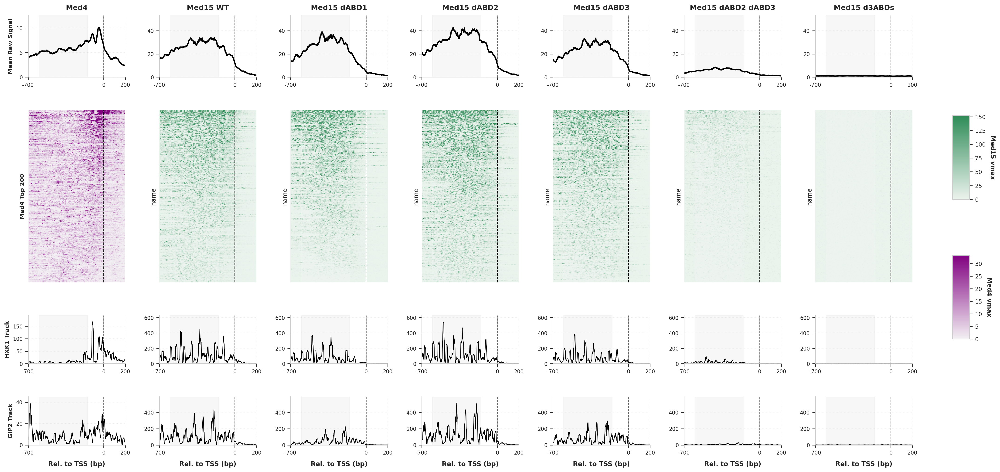

In [4]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    sumprom_df = pd.read_csv(sumprom_path, index_col=0)
else:
    sumprom_df = pd.read_pickle(sumprom_path)
sumprom_df = sumprom_df.loc[~sumprom_df.index.duplicated(keep='first')]


window_start, window_end = -700, 200
x_window = np.arange(window_start, window_end + 1)  # Length: 901
smoothing_window_meta = 30
smoothing_window_heat = 10
smoothing_window_track = 15

individual_genes = ['HXK1', 'GIP2']


promoter_binding_signals.columns = [
    str(c).replace("_2000bp_signals.gz", "") 
    for c in promoter_binding_signals.columns
]


strains_config = [
    ('Med4', ['med4']),
    ('Med15 WT', ['med15', 'wt']),
    ('Med15 dABD1', ['dabd1']),
    ('Med15 dABD2', ['dabd2']),
    ('Med15 dABD3', ['dabd3']),
    ('Med15 dABD2 dABD3', ['dabd2', 'dabd3']),
    ('Med15 d3ABDs', ['dabd1', 'dabd2', 'dabd3'])
]

strains_dict = {}
for display_name, patterns in strains_config:
    if display_name == 'Med15 dABD1':
        matched = [c for c in promoter_binding_signals.columns if 'dabd1' in c.lower() and 'dabd2' not in c.lower() and 'dabd3' not in c.lower()]
    elif display_name == 'Med15 dABD2':
        matched = [c for c in promoter_binding_signals.columns if 'dabd2' in c.lower() and 'dabd1' not in c.lower() and 'dabd3' not in c.lower()]
    elif display_name == 'Med15 dABD3':
        matched = [c for c in promoter_binding_signals.columns if 'dabd3' in c.lower() and 'dabd1' not in c.lower() and 'dabd2' not in c.lower()]
    elif display_name == 'Med15 dABD2 dABD3':
        matched = [c for c in promoter_binding_signals.columns if 'dabd2' in c.lower() and 'dabd3' in c.lower() and 'dabd1' not in c.lower()]
    elif display_name == 'Med15 d3ABDs':
        matched = [c for c in promoter_binding_signals.columns if 'dabd1' in c.lower() and 'dabd2' in c.lower() and 'dabd3' in c.lower()]
    elif display_name == 'Med15 WT':
        matched = [c for c in promoter_binding_signals.columns if 'med15' in c.lower() and 'wt' in c.lower()]
    elif display_name == 'Med4':
        matched = [c for c in promoter_binding_signals.columns if 'med4' in c.lower()]
    else:
        matched = []

    if matched:
        strains_dict[display_name] = matched[0]
    else:
        raise KeyError(f"Could not automatically find column matching '{display_name}' ({patterns})")


def load_and_clean_data(strain_name):
    path = promoter_binding_signals[strain_name].loc["path"]
    df = pd.read_pickle(path).fillna(0)
    df = df.loc[~df.index.duplicated(keep='first')]
    if df.columns[0] != -2000:
        df.columns = range(-2000, 2000)
    return df

processed_data = {}

for label, col_name in strains_dict.items():
    df = load_and_clean_data(col_name)
    
    # Dynamic target selection
    target_list = top_200_med4_targets if label == 'Med4' else top_200_med15_targets
    valid_targets = df.index.intersection(target_list)
    
    # 1. Metaprofile and Heatmap 
    raw_mat = df.loc[valid_targets, window_start:window_end]
    
    meta = (
        raw_mat.mean(axis=0)
        .rolling(window=smoothing_window_meta, center=True, min_periods=1)
        .mean()
    )
    
    heat = (
        raw_mat.T.rolling(window=smoothing_window_heat, center=True)
        .mean().T.fillna(0)
    )
    heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
    
    # 2. Individual gene tracks
    tracks = {}
    for g in individual_genes:
        if g in df.index:
            gene_raw = df.loc[g, window_start:window_end]
            if isinstance(gene_raw, pd.DataFrame):
                gene_raw = gene_raw.iloc[0]
            track_smoothed = gene_raw.rolling(window=smoothing_window_track, center=True, min_periods=1).mean().fillna(0)
            tracks[g] = track_smoothed
        else:
            tracks[g] = pd.Series(0, index=x_window)
            
    processed_data[label] = {
        'meta': meta,
        'heat': heat,
        'tracks': tracks,
        'n_targets': len(valid_targets)
    }


# Heatmap VMAX limits
med15_vmaxes = [np.percentile(d['heat'].to_numpy(), 99.0) for lbl, d in processed_data.items() if lbl != 'Med4']
med4_vmaxes = [np.percentile(d['heat'].to_numpy(), 99.0) for lbl, d in processed_data.items() if lbl == 'Med4']

global_med4_vmax = max(med4_vmaxes) if max(med4_vmaxes) > 0 else 1.0
global_med15_vmax = max(med15_vmaxes) * 0.70 if max(med15_vmaxes) > 0 else 1.0

# Tracks & Meta Y-axis max limits for Med15
med15_meta_max = max(d['meta'].max() for lbl, d in processed_data.items() if lbl != 'Med4') * 1.25
med15_hxk1_max = max(d['tracks']['HXK1'].max() for lbl, d in processed_data.items() if lbl != 'Med4') * 1.15
med15_gip2_max = max(d['tracks']['GIP2'].max() for lbl, d in processed_data.items() if lbl != 'Med4') * 1.15

# Tracks & Meta Y-axis max limits for Med4
med4_meta_max = max(d['meta'].max() for lbl, d in processed_data.items() if lbl == 'Med4') * 1.25
med4_hxk1_max = max(d['tracks']['HXK1'].max() for lbl, d in processed_data.items() if lbl == 'Med4') * 1.15
med4_gip2_max = max(d['tracks']['GIP2'].max() for lbl, d in processed_data.items() if lbl == 'Med4') * 1.15

# Color Palettes
pastel_greens = sns.light_palette("seagreen", as_cmap=True)
pastel_purples = sns.light_palette("purple", as_cmap=True)


n_strains = len(strains_dict)
fig = plt.figure(figsize=(3.5 * n_strains, 12))  

gs = fig.add_gridspec(
    4, n_strains,
    height_ratios=[0.9, 2.5, 0.7, 0.7], 
    hspace=0.40,  
    wspace=0.35   
)


idx_TSS = 700        
idx_UAS_start = 100 
idx_UAS_end = 550    

tick_labels = [-700, 0, 200]


for col_idx, (label, data) in enumerate(processed_data.items()):
    
    is_med4 = (label == 'Med4')
    

    current_vmax = global_med4_vmax if is_med4 else global_med15_vmax
    current_cmap = pastel_purples if is_med4 else pastel_greens
    
    current_meta_max = med4_meta_max if is_med4 else med15_meta_max
    current_hxk1_max = med4_hxk1_max if is_med4 else med15_hxk1_max
    current_gip2_max = med4_gip2_max if is_med4 else med15_gip2_max
    
    line_color = 'black'  
    
    # ------------------ METAPROFILE ------------------
    ax_meta = fig.add_subplot(gs[0, col_idx])
    meta_sig = data['meta']
    
    ax_meta.plot(x_window, meta_sig.values, color=line_color, linewidth=2.0)
    ax_meta.axvline(0, color='black', linestyle='--', linewidth=0.9, alpha=0.7)
    ax_meta.axvspan(-600, -150, color='gray', alpha=0.06)  
    
    ax_meta.set_title(label, fontsize=11, fontweight='bold', pad=8)
    ax_meta.set_xlim(window_start, window_end)
    ax_meta.set_ylim(0, max(current_meta_max, 0.05)) # DYNAMIC Y-AXIS
    
    ax_meta.set_xticks(tick_labels)
    ax_meta.set_xticklabels(tick_labels, fontsize=8)
    ax_meta.tick_params(axis='y', labelsize=8)
    
    ax_meta.grid(True, linestyle=':', alpha=0.35)
    ax_meta.spines['top'].set_visible(False)
    ax_meta.spines['right'].set_visible(False)
    if col_idx == 0:
        ax_meta.set_ylabel("Mean Raw Signal", fontsize=9, fontweight='bold')

    # ------------------ HEATMAP ------------------
    ax_heat = fig.add_subplot(gs[1, col_idx])
    heat_mat = data['heat']
    
    sns.heatmap(
        heat_mat,
        cmap=current_cmap,
        ax=ax_heat,
        cbar=False,
        yticklabels=False,
        xticklabels=False,
        vmax=current_vmax,
        rasterized=True
    )
    
    ax_heat.axvline(idx_TSS, color='black', linestyle='--', linewidth=1.0)
    ax_heat.axvspan(idx_UAS_start, idx_UAS_end, color='white', alpha=0.15)
    
    if col_idx == 0:
        target_name = "Med4" if is_med4 else "Med15"
        ax_heat.set_ylabel(f"{target_name} Top 200", fontsize=9, fontweight='bold')

    # ------------------ GENE 1 (HXK1) ------------------
    ax_tr1 = fig.add_subplot(gs[2, col_idx])
    hxk1_sig = data['tracks']['HXK1']
    
    ax_tr1.plot(x_window, hxk1_sig.values, color=line_color, linewidth=1.0)
    ax_tr1.axvline(0, color='black', linestyle='--', linewidth=0.9, alpha=0.7)
    ax_tr1.axvspan(-600, -150, color='gray', alpha=0.06)
    
    ax_tr1.set_xlim(window_start, window_end)
    ax_tr1.set_ylim(0, max(current_hxk1_max, 0.05)) # DYNAMIC Y-AXIS
    
    ax_tr1.set_xticks(tick_labels)
    ax_tr1.set_xticklabels(tick_labels, fontsize=8)
    ax_tr1.tick_params(axis='y', labelsize=8) 
    
    ax_tr1.spines['top'].set_visible(False)
    ax_tr1.spines['right'].set_visible(False)
    ax_tr1.grid(True, linestyle=':', alpha=0.35)
    if col_idx == 0:
        ax_tr1.set_ylabel("HXK1 Track", fontsize=9, fontweight='bold')

    # ------------------ GENE 2 (GIP2) ------------------
    ax_tr2 = fig.add_subplot(gs[3, col_idx])
    gip2_sig = data['tracks']['GIP2']
    
    ax_tr2.plot(x_window, gip2_sig.values, color=line_color, linewidth=1.0)
    ax_tr2.axvline(0, color='black', linestyle='--', linewidth=0.9, alpha=0.7)
    ax_tr2.axvspan(-600, -150, color='gray', alpha=0.06) 
    
    ax_tr2.set_xlim(window_start, window_end)
    ax_tr2.set_ylim(0, max(current_gip2_max, 0.05)) # DYNAMIC Y-AXIS
    
    ax_tr2.set_xticks(tick_labels)
    ax_tr2.set_xticklabels(tick_labels, fontsize=8)
    ax_tr2.set_xlabel("Rel. to TSS (bp)", fontsize=10, fontweight='bold', labelpad=8)
    ax_tr2.tick_params(axis='both', which='major', labelsize=8) 
    
    ax_tr2.spines['top'].set_visible(False)
    ax_tr2.spines['right'].set_visible(False)
    ax_tr2.grid(True, linestyle=':', alpha=0.35)
    if col_idx == 0:
        ax_tr2.set_ylabel("GIP2 Track", fontsize=9, fontweight='bold')


plt.tight_layout(rect=[0, 0, 0.92, 1])


cbar_med15_ax = fig.add_axes([0.935, 0.55, 0.015, 0.15])
cbar_med4_ax = fig.add_axes([0.935, 0.30, 0.015, 0.15])

sm_med15 = cm.ScalarMappable(cmap=pastel_greens, norm=mcolors.Normalize(vmin=0, vmax=global_med15_vmax))
sm_med4 = cm.ScalarMappable(cmap=pastel_purples, norm=mcolors.Normalize(vmin=0, vmax=global_med4_vmax))

fig.colorbar(sm_med15, cax=cbar_med15_ax).set_label("Med15 vmax", rotation=270, labelpad=15, fontweight='bold')
fig.colorbar(sm_med4, cax=cbar_med4_ax).set_label("Med4 vmax", rotation=270, labelpad=15, fontweight='bold')


plt.show()

## Figure 1C

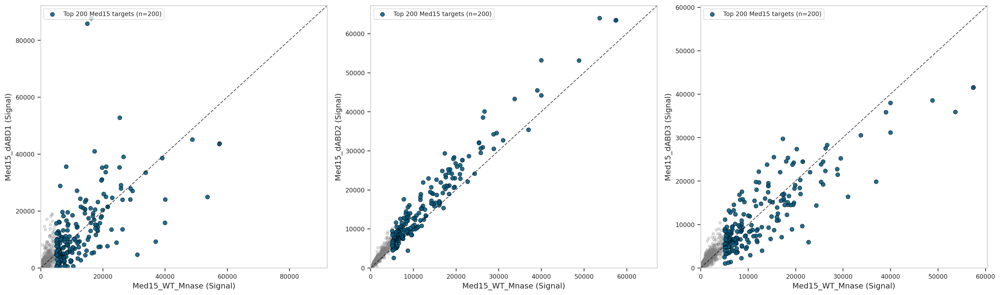

In [5]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    sumprom_df = pd.read_csv(sumprom_path, index_col=0)
else:
    sumprom_df = pd.read_pickle(sumprom_path)

sumprom_df = sumprom_df.loc[~sumprom_df.index.duplicated(keep='first')]

wt_col = 'Med15_WT_Mnase'
if wt_col not in sumprom_df.columns:
    candidates = [c for c in sumprom_df.columns if 'med15' in c.lower() and 'wt' in c.lower()]
    if candidates:
        wt_col = candidates[0]
    else:
        raise KeyError(f"Could not find Med15 WT column in {sumprom_df.columns.tolist()}")

wt_series = sumprom_df[wt_col].dropna()

mutant_queries = ['dABD1', 'dABD2', 'dABD3']
mutant_cols = []

for q in mutant_queries:
    match = [c for c in sumprom_df.columns if q.lower() in c.lower() and 'fusion' not in c.lower() and 'dabd1_dabd2' not in c.lower()]
    if match:
        mutant_cols.append(match[0])
    else:
        raise KeyError(f"Could not find column for {q} in sumprom_df columns: {sumprom_df.columns.tolist()}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, mut_col in enumerate(mutant_cols):
    ax = axes[i]

    ax.scatter(
        sumprom_df[wt_col], 
        sumprom_df[mut_col], 
        alpha=0.25, 
        color='grey', 
        s=15, 
        rasterized=True
    )
    
    valid_targets = [g for g in top_200_med15_targets if g in sumprom_df.index]
    ax.scatter(
        sumprom_df.loc[valid_targets, wt_col], 
        sumprom_df.loc[valid_targets, mut_col],
        alpha=0.85, 
        color='#005b82', 
        edgecolor='black', 
        linewidth=0.5, 
        s=35, 
        rasterized=True,
        label=f'Top 200 Med15 targets (n={len(valid_targets)})'
    )


    max_val = max(sumprom_df[wt_col].max(), sumprom_df[mut_col].max()) * 1.05
    ax.plot([0, max_val], [0, max_val], '--', color='black', alpha=0.6, linewidth=1.2)
    
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.set_xlabel(f'{wt_col} (Signal)', fontsize=11)
    ax.set_ylabel(f'{mut_col} (Signal)', fontsize=11)
    ax.legend(loc='upper left', frameon=True)
    ax.grid(False)

plt.tight_layout()
plt.show()

## Figure 1D

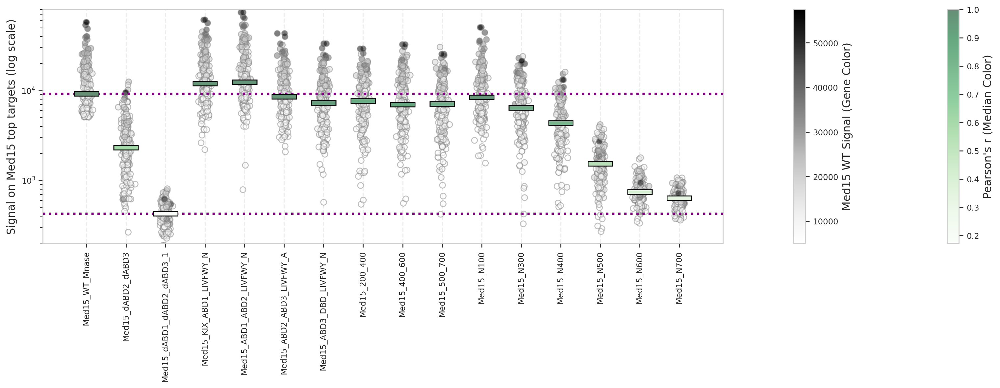

In [6]:
sumprom_path = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
WT_system_data = pd.read_pickle(sumprom_path)
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

cols_to_plot = [
    'Med15_WT_Mnase', 'Med15_dABD2_dABD3', 'Med15_dABD1_dABD2_dABD3_1', 
    'Med15_KIX_ABD1_LIVFWY_N', 'Med15_ABD1_ABD2_LIVFWY_N', 'Med15_ABD2_ABD3_LIVFWY_A', 
    'Med15_ABD3_DBD_LIVFWY_N', 'Med15_200_400', 'Med15_400_600', 'Med15_500_700',
    'Med15_N100', 'Med15_N300', 'Med15_N400', 'Med15_N500', 'Med15_N600', 'Med15_N700'
]

dABDs = WT_system_data[cols_to_plot]
valid_targets = dABDs.index.intersection(top_200_med15_targets)
df_top = dABDs.loc[valid_targets].copy()


WT_col = 'Med15_WT_Mnase'
corr_with_WT = dABDs.corr()[WT_col]

median_signal = df_top.median()
median_df = pd.DataFrame({
    'strain': median_signal.index,
    'median_signal': median_signal.values,
    'corr_to_WT': median_signal.index.map(corr_with_WT)
})

# Preserve exact column ordering
median_df['strain'] = pd.Categorical(median_df['strain'], categories=cols_to_plot, ordered=True)
median_df = median_df.sort_values('strain')

# Normalization for the median correlation colormap (Linear)
norm_corr = Normalize(vmin=median_df['corr_to_WT'].min(), vmax=median_df['corr_to_WT'].max())

# Linear Normalize matches the uploaded image (only the very top WT outliers are dark black)
min_wt = max(df_top[WT_col].min(), 1)
norm_wt_signal = Normalize(vmin=min_wt, vmax=df_top[WT_col].max())
grey_cmap = plt.get_cmap('Greys')

plt.figure(figsize=(17, 6))


np.random.seed(42)


for i, col in enumerate(cols_to_plot):
    y_vals = df_top[col]

    x_vals = np.random.normal(i, 0.06, size=len(y_vals)) 

    plt.scatter(
        x_vals, 
        y_vals, 
        c=df_top[WT_col],          
        cmap=grey_cmap,             
        norm=norm_wt_signal,
        edgecolors='gray',         
        linewidths=1,
        alpha=0.5,                 
        s=40,                       
        zorder=2,
        rasterized=True             
    )

# --- Vertical dividing lines ---
for i in range(len(cols_to_plot)):
    plt.axvline(x=i, color='lightgrey', linestyle='--', alpha=0.4, zorder=1)

# --- OVERLAY MEDIANS (Short Horizontal Lines) ---
for i, col in enumerate(cols_to_plot):
    row = median_df[median_df['strain'] == col].iloc[0]
    
    if pd.isna(row['median_signal']):
        continue  

    line_color = pastel_cmap(norm_corr(row['corr_to_WT'])) if 'pastel_cmap' in globals() else cm.viridis(norm_corr(row['corr_to_WT']))


    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    

    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=line_color,
        linewidth=4,
        zorder=10
    )


ref_strains = ['Med15_dABD1_dABD2_dABD3_1', 'Med15_WT_Mnase']
for target_strain in ref_strains:
    if target_strain in df_top.columns:
        avg_val = median_df.loc[median_df['strain'] == target_strain, 'median_signal'].values
        if len(avg_val) > 0 and not pd.isna(avg_val[0]):
            plt.axhline(avg_val[0], color='purple', linestyle=':', linewidth=2.5, zorder=3)

ax = plt.gca()


sm_corr = cm.ScalarMappable(norm=norm_corr, cmap=pastel_cmap if 'pastel_cmap' in globals() else 'viridis')
cbar_corr = plt.colorbar(sm_corr, ax=ax, pad=0.02) 
cbar_corr.set_label("Pearson's r (Median Color)", fontsize=12)


sm_wt = cm.ScalarMappable(norm=norm_wt_signal, cmap=grey_cmap)
cbar_wt = plt.colorbar(sm_wt, ax=ax, pad=0.08)
cbar_wt.set_label("Med15 WT Signal (Gene Color)", fontsize=12)


plt.xticks(ticks=range(len(cols_to_plot)), labels=cols_to_plot, rotation=90)
plt.yscale('log')
plt.ylim(200, 80000)
plt.ylabel('Signal on Med15 top targets (log scale)', fontsize=12)
plt.grid(False)
plt.tight_layout()
plt.show()

# Figure 2

## Figure 2A

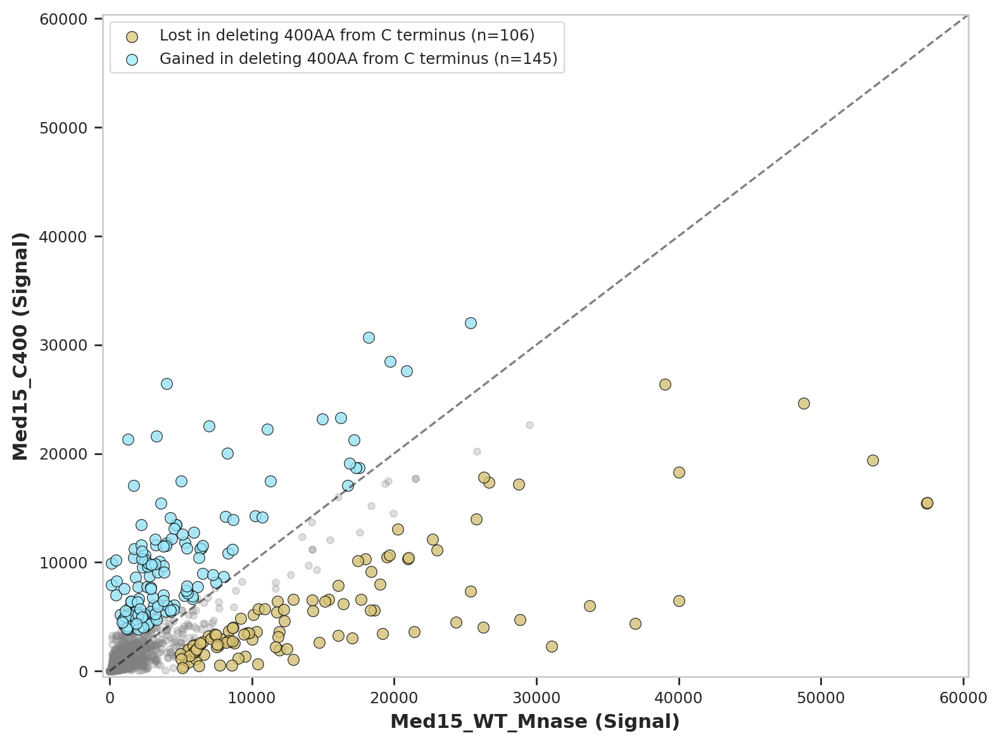

In [7]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)


WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]


wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]

fig, ax = plt.subplots(1, figsize=(8, 6))

# Background scatter: All genes (rasterized)
ax.scatter(
    WT_system_data[wt_col], 
    WT_system_data[c400_col], 
    alpha=0.25, 
    color='grey', 
    s=15, 
    rasterized=True
)

# Foreground scatter: Lost in C400
ax.scatter(
    WT_system_data.loc[lost_in_dc, wt_col], 
    WT_system_data.loc[lost_in_dc, c400_col], 
    alpha=0.75, 
    color='#DDC878', 
    edgecolor='black', 
    linewidth=0.5, 
    s=40, 
    rasterized=True, 
    label=f'Lost in deleting 400AA from C terminus (n={len(lost_in_dc)})'
)

# Foreground scatter: Gained in C400
ax.scatter(
    WT_system_data.loc[gained_in_dc, wt_col], 
    WT_system_data.loc[gained_in_dc, c400_col], 
    alpha=0.75, 
    color='#9CEBFF', 
    edgecolor='black', 
    linewidth=0.5, 
    s=40, 
    rasterized=True, 
    label=f'Gained in deleting 400AA from C terminus (n={len(gained_in_dc)})'
)


max_val = max(WT_system_data[c400_col].max(), WT_system_data[wt_col].max()) * 1.05
ax.plot([0, max_val], [0, max_val], '--', color='black', alpha=0.5, linewidth=1.2)

ax.set_xlim(-500, max_val)
ax.set_ylim(-500, max_val)
ax.set_xlabel(f'{wt_col} (Signal)', fontsize=11, fontweight='bold')
ax.set_ylabel(f'{c400_col} (Signal)', fontsize=11, fontweight='bold')
ax.legend(loc='upper left', frameon=True)
ax.grid(False)
plt.tight_layout()
plt.show()

## Figure 2B

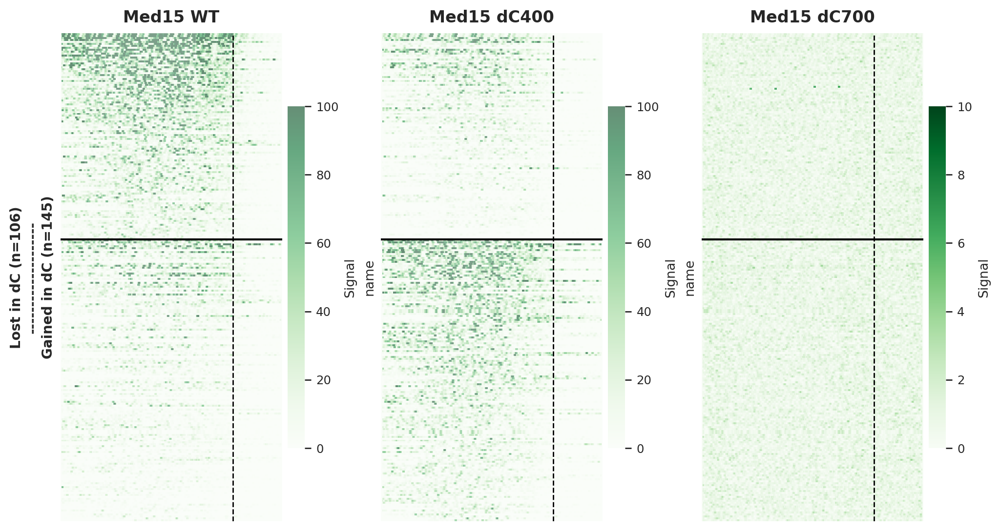

In [8]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    sumprom_df = pd.read_csv(sumprom_path, index_col=0)
else:
    sumprom_df = pd.read_pickle(sumprom_path)

sumprom_df.columns = [str(c).replace("_2000bp_signals.gz", "") for c in sumprom_df.columns]
sumprom_df = sumprom_df.loc[~sumprom_df.index.duplicated(keep='first')]

# Resolve column names in sumprom for WT and C400
wt_sum_col = [c for c in sumprom_df.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_sum_col = [c for c in sumprom_df.columns if 'c400' in c.lower()][0]

candidate_lost = ['HXK1', 'HSP12', 'GIP2', 'HSP26', 'EGO4']
candidate_gained = ['MUP1', 'TIP1', 'PTR2', 'BOP2', 'BAP3']

lost_genes = [g for g in candidate_lost if g in lost_in_dc][:3]
gained_genes = [g for g in candidate_gained if g in gained_in_dc][:3]

if len(lost_genes) < 3:
    fallback_lost = (z_wt - z_c400).loc[lost_in_dc].sort_values(ascending=False).index.tolist()
    lost_genes += [g for g in fallback_lost if g not in lost_genes][:3 - len(lost_genes)]

if len(gained_genes) < 3:
    fallback_gained = (z_c400 - z_wt).loc[gained_in_dc].sort_values(ascending=False).index.tolist()
    gained_genes += [g for g in fallback_gained if g not in gained_genes][:3 - len(gained_genes)]

track_genes = lost_genes + gained_genes

# =====================================================================
window_start, window_end = -700, 200
x_window = np.arange(window_start, window_end + 1)
smoothing_window_heat = 10
smoothing_window_track = 15

promoter_binding_signals.columns = [
    str(c).replace("_2000bp_signals.gz", "") 
    for c in promoter_binding_signals.columns
]

strains_config = [
    ('Med15 WT', ['med15', 'wt']),
    ('Med15 dC400', ['c400', 'med15']),
    ('Med15 dC700', ['c700', 'med15'])
]

strains_dict = {}
for display_name, patterns in strains_config:
    if display_name == 'Med15 WT':
        matched = [c for c in promoter_binding_signals.columns if 'med15' in c.lower() and 'wt' in c.lower()]
    elif display_name == 'Med15 dC400':
        matched = [c for c in promoter_binding_signals.columns if 'c400' in c.lower()]
    elif display_name == 'Med15 dC700':
        matched = [c for c in promoter_binding_signals.columns if 'c700' in c.lower()]
    else:
        matched = []

    if matched:
        strains_dict[display_name] = matched[0]
    else:
        raise KeyError(f"Could not automatically find column matching '{display_name}' ({patterns})")

track_color = '#2ca02c'


def load_and_clean_data(strain_name):
    path = promoter_binding_signals[strain_name].loc["path"]
    df = pd.read_pickle(path).fillna(0)
    df = df.loc[~df.index.duplicated(keep='first')]
    if df.columns[0] != -2000:
        df.columns = range(-2000, 2000)
    return df

processed_data = {}

for label, col_name in strains_dict.items():
    df = load_and_clean_data(col_name)
    
    valid_lost = df.index.intersection(lost_in_dc)
    valid_gained = df.index.intersection(gained_in_dc)
    
    heat_lost = (
        df.loc[valid_lost, window_start:window_end]
        .T.rolling(window=smoothing_window_heat, center=True)
        .mean().T.fillna(0)
    )
    heat_gained = (
        df.loc[valid_gained, window_start:window_end]
        .T.rolling(window=smoothing_window_heat, center=True)
        .mean().T.fillna(0)
    )
    
    tracks = {}
    for g in track_genes:
        if g in df.index:
            gene_raw = df.loc[g, window_start:window_end]
            if isinstance(gene_raw, pd.DataFrame):
                gene_raw = gene_raw.iloc[0]
            track_smoothed = gene_raw.rolling(window=smoothing_window_track, center=True, min_periods=1).mean().fillna(0)
            tracks[g] = track_smoothed
        else:
            tracks[g] = pd.Series(0, index=x_window)
            
    processed_data[label] = {
        'heat_lost': heat_lost,
        'heat_gained': heat_gained,
        'tracks': tracks
    }

# Sorting: Lost ordered by WT, Gained ordered by dC400
lost_order = processed_data['Med15 WT']['heat_lost'].sum(axis=1).sort_values(ascending=False).index
gained_order = processed_data['Med15 dC400']['heat_gained'].sum(axis=1).sort_values(ascending=False).index

for label in processed_data:
    h_lost_aligned = processed_data[label]['heat_lost'].reindex(lost_order).fillna(0)
    h_gained_aligned = processed_data[label]['heat_gained'].reindex(gained_order).fillna(0)
    processed_data[label]['heat_combined'] = pd.concat([h_lost_aligned, h_gained_aligned], axis=0)

# Row-shared Y-axis limits across strains for tracks
gene_max_y = {}
for g in track_genes:
    gene_max_y[g] = max(
        max(processed_data[lbl]['tracks'][g].max() for lbl in strains_dict),
        0.05
    ) * 1.15



idx_TSS = 700        # 0 bp
idx_UAS_start = 100  # -600 bp
idx_UAS_end = 550    # -150 bp
split_boundary = len(lost_order)
tick_labels = [-700, 0, 200]


n_strains = len(strains_dict)
fig_heat, axes_heat = plt.subplots(1, n_strains, figsize=(4.0 * n_strains, 6.5), sharey=True)

for col_idx, (label, data) in enumerate(processed_data.items()):
    ax_h = axes_heat[col_idx]
    
    # Split VMAX and Colormap logic
    is_dc700 = (label == 'Med15 dC700')
    current_vmax = 10.0 if is_dc700 else 100.0
    current_cmap = 'Greens' if is_dc700 else (pastel_cmap if 'pastel_cmap' in locals() else 'viridis')
    
    sns.heatmap(
        data['heat_combined'],
        cmap=current_cmap,
        ax=ax_h,
        cbar=True,
        cbar_kws={'shrink': 0.7, 'pad': 0.02, 'label': 'Signal'},
        yticklabels=False,
        xticklabels=False,
        vmin=0.0,
        vmax=current_vmax,
        rasterized=True
    )
    
    ax_h.axvline(idx_TSS, color='black', linestyle='--', linewidth=1.0)
    ax_h.axvspan(idx_UAS_start, idx_UAS_end, color='white', alpha=0.15)
    ax_h.axhline(split_boundary, color='black', linestyle='-', linewidth=1.5)
    ax_h.set_title(label, fontsize=12, fontweight='bold', pad=8)
    
    if col_idx == 0:
        ax_h.set_ylabel(
            f"Lost in dC (n={len(lost_order)})\n--------------------\nGained in dC (n={len(gained_order)})",
            fontsize=10,
            fontweight='bold'
        )


plt.show()

## Figure 2C

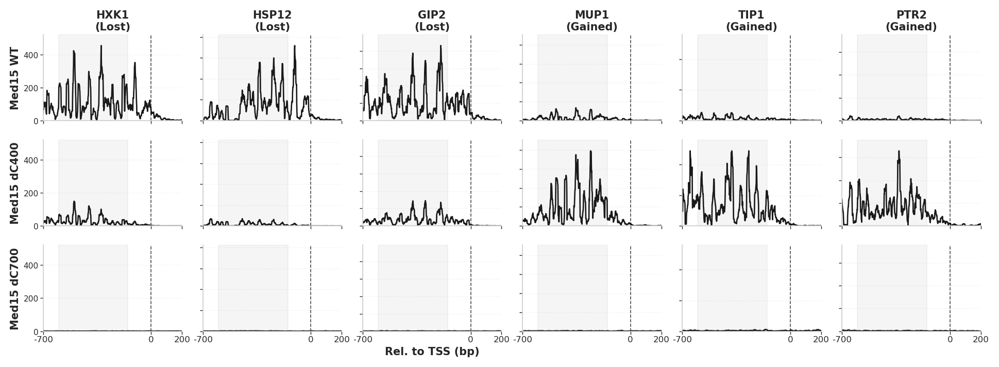

In [9]:
fig_tr, axes_tr = plt.subplots(
    nrows=n_strains, 
    ncols=len(track_genes), 
    figsize=(10, 4),
    sharex=True
)

for row_idx, (label, data) in enumerate(processed_data.items()):
    for col_idx, g in enumerate(track_genes):
        ax = axes_tr[row_idx, col_idx]
        g_sig = data['tracks'][g]
        
        # Raw green traces
        ax.plot(x_window, g_sig.values, color='k', linewidth=0.95)
        ax.axvline(0, color='black', linestyle='--', linewidth=0.6, alpha=0.7)
        ax.axvspan(-600, -150, color='gray', alpha=0.08)
        
        ax.set_xlim(window_start, window_end)
        # Consistent Y-axis ceiling down each gene column
        ax.set_ylim(0, gene_max_y[g])
        ax.set_xticks(tick_labels)
        
        # Compact ticks & borders
        ax.tick_params(axis='both', which='both', labelsize=5.5, pad=1.2, length=2.0, width=0.5)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(0.6)
        ax.spines['bottom'].set_linewidth(0.6)
        ax.grid(True, linestyle=':', alpha=0.35, linewidth=0.5)
        
        # Gene headers across the top row
        if row_idx == 0:
            category_tag = "Lost" if col_idx < 3 else "Gained"
            ax.set_title(f"{g}\n({category_tag})", fontsize=7.5, fontweight='bold', pad=3)
            
        # Strain labels along the leftmost column
        if col_idx == 0:
            ax.set_ylabel(label, fontsize=7.5, fontweight='bold', labelpad=2)
        else:
            ax.tick_params(labelleft=False)
            
        # X-axis coordinates along the bottom row
        if row_idx == n_strains - 1:
            ax.set_xticklabels(tick_labels, fontsize=6)
            if col_idx == 2:  # Centered label across the bottom
                ax.set_xlabel("Rel. to TSS (bp)", fontsize=7.5, fontweight='bold', labelpad=2)
        else:
            ax.set_xticklabels([])

plt.subplots_adjust(
    left=0.08,
    right=0.99,
    top=0.86,
    bottom=0.14,
    hspace=0.22,
    wspace=0.15
)

plt.show()

## Figure 2D

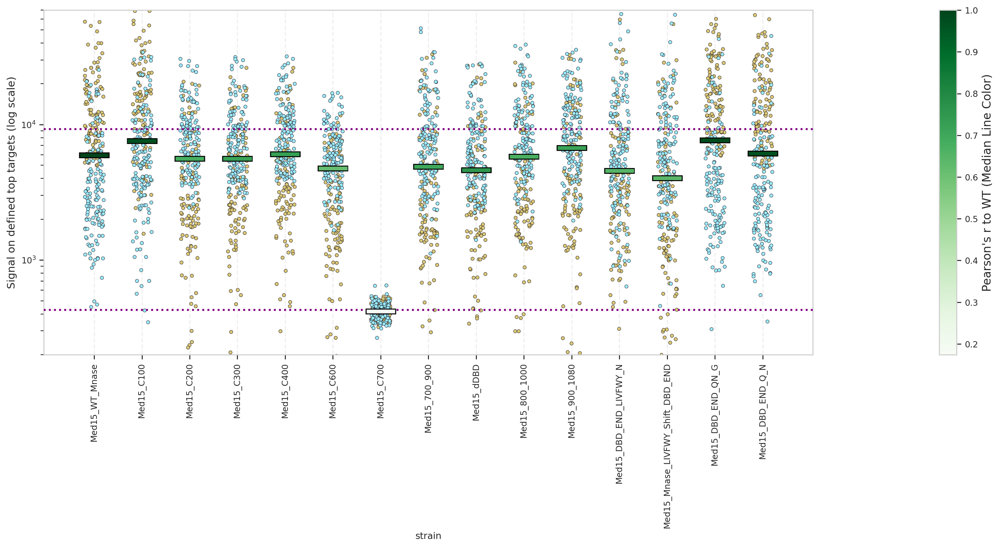

In [10]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]


# =====================================================================
# 3. CONSTRUCT FIGURE_2C WITH REQUESTED STRAINS
# =====================================================================
requested_strains = [
    'Med15_WT_Mnase', 'Med15_C100', 'Med15_C200', 'Med15_C300',
    'Med15_C400', 'Med15_C600', 'Med15_C700', 'Med15_700_900', 'Med15_dDBD',
    'Med15_800_1000', 'Med15_900_1080', 'Med15_DBD_END_LIVFWY_N',
    'Med15_Mnase_LIVFWY_Shift_DBD_END', 'Med15_DBD_END_QN_G', 'Med15_DBD_END_Q_N'
]

# Ensure strains exist in dataframe
available_strains = [s for s in requested_strains if s in WT_system_data.columns]
missing_strains = set(requested_strains) - set(available_strains)
if missing_strains:
    print(f"Warning: The following strains were not found in WT_system_data: {missing_strains}")

Figure_2C = WT_system_data[available_strains]

# Filter down to the combined targets
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_2C.index]
df_top = Figure_2C.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to WT
median_s = df_long.groupby('strain')['signal'].median()
corr_with_WT = Figure_2C.corr()[wt_col]

median_df = pd.DataFrame({
    'strain': Figure_2C.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_2C.columns],
    'corr_to_WT': [corr_with_WT.get(col, np.nan) for col in Figure_2C.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_WT'].dropna().min(),
    vmax=median_df['corr_to_WT'].dropna().max()
)

# =====================================================================
# 4. PLOTTING
# =====================================================================
fig, ax1 = plt.subplots(figsize=(16, 8))

cmap_choice = cm.Greens

# Lost in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_2C.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.2,
    size=3.5,
    zorder=2,
    ax=ax1,
    rasterized=True
)

# Gained in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_2C.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.2,
    size=3.5,
    zorder=2,
    ax=ax1,
    rasterized=True
)

# [UPDATED] Median overlays (short horizontal lines instead of hexagons)
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
        
    # Draw a slightly thicker black line behind it for a crisp border/outline effect
    ax1.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    # Draw the colored median line on top
    ax1.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_WT'])),
        linewidth=4,
        zorder=10
    )




# Vertical guides
for strain in Figure_2C.columns:
    ax1.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines (evaluated on Med15 WT top targets baseline)
if 'top_200_med15_targets' in globals():
    valid_targets = WT_system_data.index.intersection(top_200_med15_targets)
else:
    valid_targets = z_wt.sort_values(ascending=False).head(200).index

ref_strains = [
    ('Med15_WT_Mnase', 'purple', ':'),
    ('Med15_dABD1_dABD2_dABD3_1', 'purple', ':')
]

for ref_s, c, ls in ref_strains:
    if ref_s in WT_system_data.columns:
        val_ref = WT_system_data.loc[valid_targets, ref_s].median()
        if not pd.isna(val_ref):
            ax1.axhline(val_ref, color=c, linestyle=ls, linewidth=2.0, zorder=3)

# Colorbar (attached to the main axis, with extra padding for ax2)
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=ax1, pad=0.12)
cbar.set_label("Pearson's r to WT (Median Line Color)", fontsize=12)

# Axis formatting
ax1.set_xticks(range(len(Figure_2C.columns)))
ax1.set_xticklabels(Figure_2C.columns, rotation=90)
ax1.set_yscale('log')
ax1.set_ylim(200, 70000)
ax1.set_ylabel('Signal on defined top targets (log scale)', fontsize=11)
plt.tight_layout()
plt.grid(False)
plt.show()

# Figure 3

## Figure 3B

/tmp/ipykernel_1317918/3738653165.py:234: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


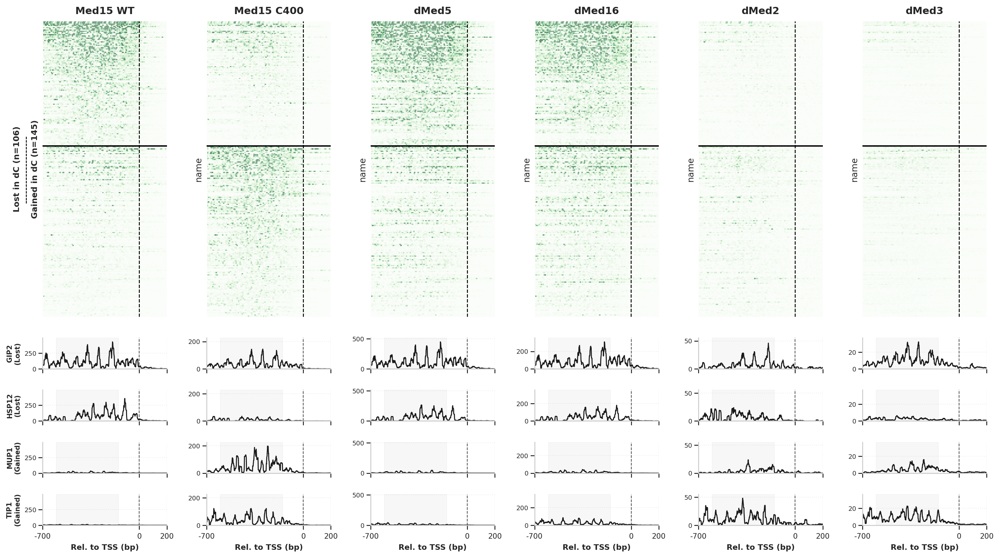

In [11]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    sumprom_df = pd.read_csv(sumprom_path, index_col=0)
else:
    sumprom_df = pd.read_pickle(sumprom_path)

sumprom_df.columns = [str(c).replace("_2000bp_signals.gz", "") for c in sumprom_df.columns]
sumprom_df = sumprom_df.loc[~sumprom_df.index.duplicated(keep='first')]

# Resolve column names in sumprom for WT and C400
wt_sum_col = [c for c in sumprom_df.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_sum_col = [c for c in sumprom_df.columns if 'c400' in c.lower()][0]

valid_sum_data = sumprom_df[[wt_sum_col, c400_sum_col]].dropna()
s_wt = valid_sum_data[wt_sum_col]
s_c400 = valid_sum_data[c400_sum_col]

lost_genes = ['GIP2', 'HSP12']
gained_genes = ['MUP1', 'TIP1']

# Verify they passed the strict diagonal/Z-score filters
lost_genes = [g for g in lost_genes if g in lost_in_dc]
gained_genes = [g for g in gained_genes if g in gained_in_dc]


track_genes = lost_genes + gained_genes


window_start, window_end = -700, 200
x_window = np.arange(window_start, window_end + 1)
smoothing_window_heat = 10
smoothing_window_track = 15

promoter_binding_signals.columns = [
    str(c).replace("_2000bp_signals.gz", "") 
    for c in promoter_binding_signals.columns
]

strains_config = [
    ('Med15 WT', ['med15', 'wt']),
    ('Med15 C400', ['c400', 'med15']),
    ('dMed5', ['dmed5']),
    ('dMed16', ['dmed16']),
    ('dMed2', ['dmed2']),
    ('dMed3', ['dmed3'])
]

strains_dict = {}
for display_name, patterns in strains_config:
    if display_name == 'dMed2 dMed3':
        matched = [c for c in promoter_binding_signals.columns if 'dmed2' in c.lower() and 'dmed3' in c.lower()]
    elif display_name == 'dMed2':
        matched = [c for c in promoter_binding_signals.columns if 'dmed2' in c.lower() and 'dmed3' not in c.lower()]
    elif display_name == 'dMed3':
        matched = [c for c in promoter_binding_signals.columns if 'dmed3' in c.lower() and 'dmed2' not in c.lower()]
    elif display_name == 'dMed5':
        matched = [c for c in promoter_binding_signals.columns if 'dmed5' in c.lower()]
    elif display_name == 'dMed16':
        matched = [c for c in promoter_binding_signals.columns if 'dmed16' in c.lower()]
    elif display_name == 'Med15 WT':
        matched = [c for c in promoter_binding_signals.columns if 'med15' in c.lower() and 'wt' in c.lower()]
    elif display_name == 'Med15 C400':
        matched = [c for c in promoter_binding_signals.columns if 'c400' in c.lower()]
    else:
        matched = []

    if matched:
        strains_dict[display_name] = matched[0]
    else:
        raise KeyError(f"Could not automatically find column matching '{display_name}' ({patterns}) in promoter_binding_signals!")

strain_colors = {
    'Med15 WT': 'k',
    'Med15 C400': 'k',
    'dMed5': 'k',
    'dMed16': 'k',
    'dMed2': 'k',
    'dMed3': 'k',
    'dMed2 dMed3': 'k'
}

def load_and_clean_data(col_name):
    path = promoter_binding_signals[col_name].loc["path"]
    df = pd.read_pickle(path).fillna(0)
    df = df.loc[~df.index.duplicated(keep='first')]
    if df.columns[0] != -2000:
        df.columns = range(-2000, 2000)
    return df

processed_data = {}

for label, col_name in strains_dict.items():
    df = load_and_clean_data(col_name)
    
    valid_lost = df.index.intersection(lost_in_dc)
    valid_gained = df.index.intersection(gained_in_dc)
    
    heat_lost = (
        df.loc[valid_lost, window_start:window_end]
        .T.rolling(window=smoothing_window_heat, center=True)
        .mean().T.fillna(0)
    )
    heat_gained = (
        df.loc[valid_gained, window_start:window_end]
        .T.rolling(window=smoothing_window_heat, center=True)
        .mean().T.fillna(0)
    )
    
    tracks = {}
    for g in track_genes:
        if g in df.index:
            gene_raw = df.loc[g, window_start:window_end]
            if isinstance(gene_raw, pd.DataFrame):
                gene_raw = gene_raw.iloc[0]
            track_smoothed = gene_raw.rolling(window=smoothing_window_track, center=True, min_periods=1).mean().fillna(0)
            tracks[g] = track_smoothed
        else:
            tracks[g] = pd.Series(0, index=x_window)
            
    processed_data[label] = {
        'heat_lost': heat_lost,
        'heat_gained': heat_gained,
        'tracks': tracks
    }

# Sorting
lost_order = processed_data['Med15 WT']['heat_lost'].sum(axis=1).sort_values(ascending=False).index
gained_order = processed_data['Med15 C400']['heat_gained'].sum(axis=1).sort_values(ascending=False).index

for label in processed_data:
    processed_data[label]['heat_lost'] = processed_data[label]['heat_lost'].reindex(lost_order).fillna(0)
    processed_data[label]['heat_gained'] = processed_data[label]['heat_gained'].reindex(gained_order).fillna(0)

for label in processed_data:
    processed_data[label]['heat_combined'] = pd.concat([
        processed_data[label]['heat_lost'], 
        processed_data[label]['heat_gained']
    ], axis=0)


strain_track_ymax = {}
for label, d in processed_data.items():
    max_val_in_strain = max(d['tracks'][g].max() for g in track_genes)
    strain_track_ymax[label] = max(max_val_in_strain * 1.15, 0.05)
    
n_strains = len(strains_dict)
fig = plt.figure(figsize=(3.1 * n_strains, 10))

gs = fig.add_gridspec(
    5, n_strains,
    height_ratios=[3.8, 0.40, 0.40, 0.40, 0.40],
    hspace=0.25,
    wspace=0.32
)

idx_TSS = 700
idx_UAS_start = 100
idx_UAS_end = 550
split_boundary = len(lost_order)

tick_labels = [-700, 0, 200]


for col_idx, (label, data) in enumerate(processed_data.items()):
    col_color = strain_colors[label]
    col_ymax = strain_track_ymax[label]
    
    # ------------------ CONNECTED HEATMAP ------------------
    ax_heat = fig.add_subplot(gs[0, col_idx])
    
    sns.heatmap(
        data['heat_combined'],
        cmap=pastel_cmap if 'pastel_cmap' in locals() else 'viridis',
        ax=ax_heat,
        cbar=False,
        yticklabels=False,
        xticklabels=False,
        vmin=0.0,
        vmax=115,           
        rasterized=True
    )
    
    ax_heat.axvline(idx_TSS, color='black', linestyle='--', linewidth=1.0)
    ax_heat.axvspan(idx_UAS_start, idx_UAS_end, color='white', alpha=0.15)

    ax_heat.axhline(split_boundary, color='black', linestyle='-', linewidth=1.5)
    
    ax_heat.set_title(label, fontsize=11, fontweight='bold', pad=8)
    
    if col_idx == 0:
        ax_heat.set_ylabel(
            f"Lost in dC (n={len(lost_order)})\n--------------------\nGained in dC (n={len(gained_order)})",
            fontsize=9,
            fontweight='bold'
        )

    # ------------------ COMPACT TRACKS ------------------
    for row_offset, g in enumerate(track_genes):
        row_idx = 1 + row_offset
        ax_tr = fig.add_subplot(gs[row_idx, col_idx])
        g_sig = data['tracks'][g]
        
        ax_tr.plot(x_window, g_sig.values, color=col_color, linewidth=1.1)
        ax_tr.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)
        ax_tr.axvspan(-600, -150, color='gray', alpha=0.06)
        
        ax_tr.set_xlim(window_start, window_end)
        # Consistent Y-axis ceiling across all tracks for THIS strain
        ax_tr.set_ylim(0, col_ymax)
        
        ax_tr.set_xticks(tick_labels)
        ax_tr.tick_params(axis='y', labelsize=7, pad=2)
        
        ax_tr.spines['top'].set_visible(False)
        ax_tr.spines['right'].set_visible(False)
        ax_tr.grid(True, linestyle=':', alpha=0.35)
        
        if row_idx == 4:
            ax_tr.set_xticklabels(tick_labels, fontsize=8)
            ax_tr.set_xlabel("Rel. to TSS (bp)", fontsize=8.5, fontweight='bold', labelpad=4)
        else:
            ax_tr.set_xticklabels([])
            
        if col_idx == 0:
            category_tag = "Lost" if row_offset < 2 else "Gained"
            ax_tr.set_ylabel(f"{g}\n({category_tag})", fontsize=7.5, fontweight='bold')

plt.tight_layout()

plt.show()

## Figure 3C

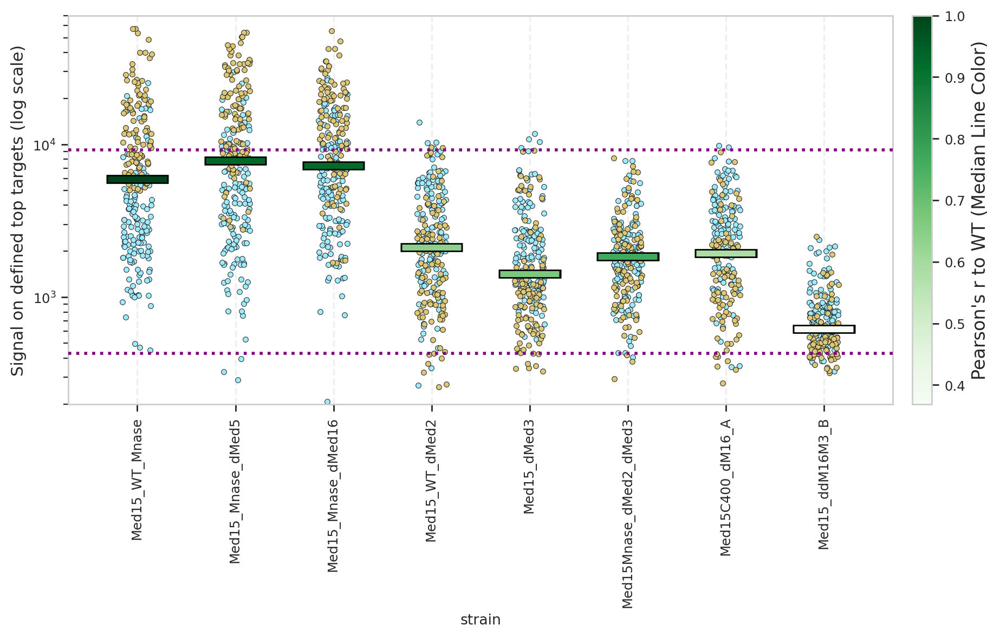

In [12]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]


requested_strains = [
    'Med15_WT_Mnase', 
    'Med15_Mnase_dMed5', 
    'Med15_Mnase_dMed16',
    'Med15_WT_dMed2', 
    'Med15_dMed3', 
    'Med15Mnase_dMed2_dMed3', 
    'Med15C400_dM16_A', 
    'Med15_ddM16M3_B'
]

# Robust column matching to account for minor naming variances
resolved_strains = []
for strain in requested_strains:
    if strain in WT_system_data.columns:
        resolved_strains.append(strain)
    else:
        # Fallback match by stripping underscores or case-insensitivity
        clean_target = strain.lower().replace("_", "")
        matches = [c for c in WT_system_data.columns if c.lower().replace("_", "") == clean_target]
        if matches:
            resolved_strains.append(matches[0])
        else:
            print(f"⚠️ Warning: '{strain}' not found in dataset columns!")

Figure_3C = WT_system_data[resolved_strains].copy()

# Filter down to the combined targets
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_3C.index]
df_top = Figure_3C.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to WT
median_s = df_long.groupby('strain')['signal'].median()
corr_with_WT = Figure_3C.corr()[wt_col]

median_df = pd.DataFrame({
    'strain': Figure_3C.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_3C.columns],
    'corr_to_WT': [corr_with_WT.get(col, np.nan) for col in Figure_3C.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_WT'].dropna().min(),
    vmax=median_df['corr_to_WT'].dropna().max()
)

# =====================================================================
# 4. PLOTTING
# =====================================================================
plt.figure(figsize=(10, 6))

cmap_choice = cm.Greens

# Gained in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3C.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)

# Lost in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3C.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)

# Median overlays (short horizontal lines instead of scatter points)
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
    
    # Draw a slightly thicker black line behind it for a crisp border/outline effect
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    # Draw the colored median line on top
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_WT'])),
        linewidth=4,
        zorder=10
    )

# Vertical guides
for strain in Figure_3C.columns:
    plt.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines (evaluated on Med15 WT top targets baseline)
if 'top_200_med15_targets' in globals():
    valid_targets = WT_system_data.index.intersection(top_200_med15_targets)

ref_strains = [
    ('Med15_WT_Mnase', 'purple', ':'),
    ('Med15_dABD1_dABD2_dABD3_1', 'purple', ':')
]

for ref_s, c, ls in ref_strains:
    if ref_s in WT_system_data.columns:
        val_ref = WT_system_data.loc[valid_targets, ref_s].median()
        if not pd.isna(val_ref):
            plt.axhline(val_ref, color=c, linestyle=ls, linewidth=2.0, zorder=3)

# Colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label("Pearson's r to WT (Median Line Color)", fontsize=12)

# Axis formatting
plt.xticks(rotation=90)
plt.yscale('log')
plt.ylim(200, 70000)
plt.ylabel('Signal on defined top targets (log scale)', fontsize=11)
plt.tight_layout()
plt.grid(False)
plt.show()

## Figure 3D

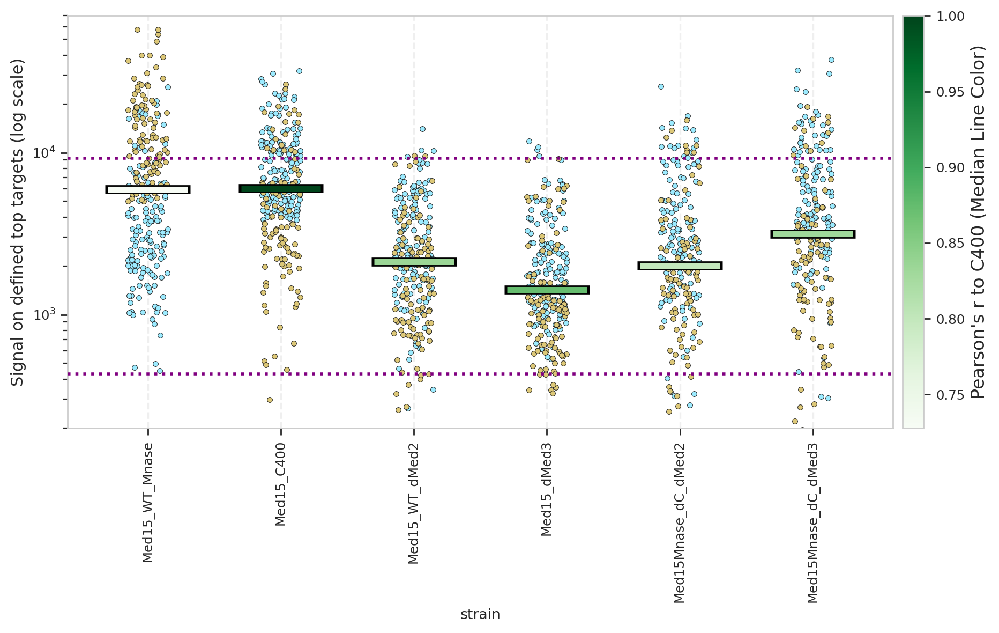

In [13]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]

requested_strains = [
    'Med15_WT_Mnase', 
    'Med15_C400', 
    'Med15_WT_dMed2', 
    'Med15_dMed3', 
    'Med15Mnase_dC_dMed2', 
    'Med15Mnase_dC_dMed3'
]

# Robust column matching to handle potential naming variances
resolved_strains = []
for strain in requested_strains:
    if strain in WT_system_data.columns:
        resolved_strains.append(strain)
    else:
        clean_target = strain.lower().replace("_", "")
        matches = [c for c in WT_system_data.columns if c.lower().replace("_", "") == clean_target]
        if matches:
            resolved_strains.append(matches[0])
        else:
            print(f"⚠️ Warning: '{strain}' not found in dataset columns!")

Figure_3D = WT_system_data[resolved_strains].copy()

# Filter down to the combined targets
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_3D.index]
df_top = Figure_3D.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to Med15_C400
median_s = df_long.groupby('strain')['signal'].median()
ref_corr_col = c400_col if c400_col in Figure_3D.columns else 'Med15_C400'
corr_with_c400 = Figure_3D.corr()[ref_corr_col]

median_df = pd.DataFrame({
    'strain': Figure_3D.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_3D.columns],
    'corr_to_C400': [corr_with_c400.get(col, np.nan) for col in Figure_3D.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_C400'].dropna().min(),
    vmax=median_df['corr_to_C400'].dropna().max()
)

# =====================================================================
# 4. PLOTTING
# =====================================================================
plt.figure(figsize=(10, 6))
cmap_choice = cm.Greens

# Gained in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3D.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)


# Lost in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3D.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)


# Median overlays (short horizontal lines instead of scatter points)
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
    
    # Draw a slightly thicker black line behind it for a crisp border/outline effect
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    # Draw the colored median line on top
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_C400'])),
        linewidth=4,
        zorder=10
    )

# Vertical guides
for strain in Figure_3D.columns:
    plt.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines (evaluated on Med15 WT top targets baseline)
if 'top_200_med15_targets' in globals():
    valid_targets = WT_system_data.index.intersection(top_200_med15_targets)


baseline_strains = {
    'Med15_WT_Mnase': ':',
    'Med15_dABD1_dABD2_dABD3_1': ':'
}

for target_strain, line_style in baseline_strains.items():
    if target_strain in WT_system_data.columns:
        avg_signal = WT_system_data.loc[valid_targets, target_strain].median()
        if pd.notna(avg_signal):
            plt.axhline(
                avg_signal, 
                color='purple', 
                linestyle=line_style, 
                linewidth=2.0, 
                zorder=3
            )

# Colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.01)
cbar.set_label("Pearson's r to C400 (Median Line Color)", fontsize=12)
plt.grid(False)
# Axis formatting
plt.xticks(rotation=90)
plt.yscale('log')
plt.ylim(200, 70000)
plt.ylabel('Signal on defined top targets (log scale)', fontsize=11)
plt.tight_layout()
plt.show()

## Figure 3E

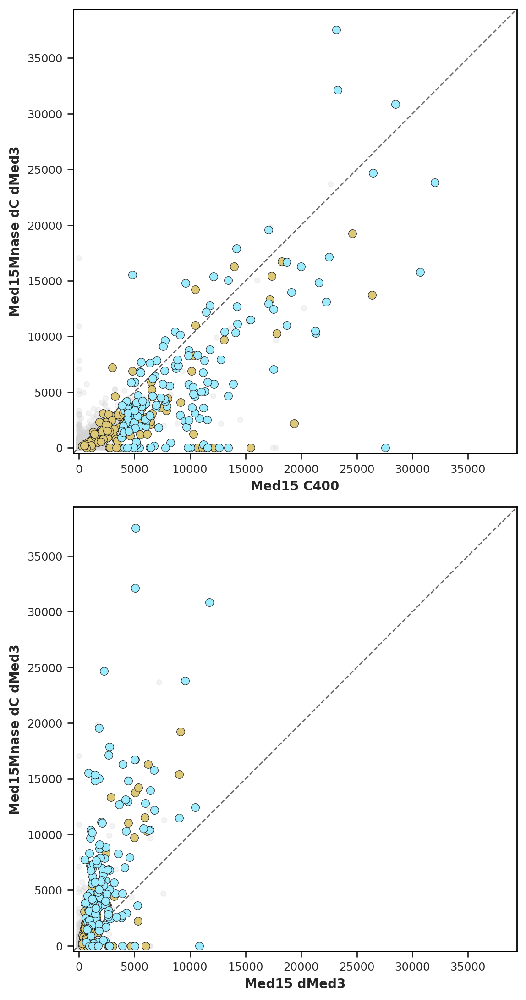

In [14]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean column names and deduplicate index
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]


def resolve_col(target_name, df):
    if target_name in df.columns:
        return target_name
    clean_target = target_name.lower().replace("_", "")
    matches = [c for c in df.columns if c.lower().replace("_", "") == clean_target]
    if matches:
        return matches[0]
    raise KeyError(f"Could not find column matching '{target_name}' in dataset!")

c400_key = resolve_col('Med15_C400', WT_system_data)
dmed3_key = resolve_col('Med15_dMed3', WT_system_data)
dc_dmed3_key = resolve_col('Med15Mnase_dC_dMed3', WT_system_data)


def plot_med_comparison(ax, df, x_col, y_col, lost_idx, gained_idx):
    valid = df[[x_col, y_col]].dropna()
    
    valid_lost = valid.index.intersection(lost_idx)
    valid_gained = valid.index.intersection(gained_idx)
    
    # Base scatter (all background promoters)
    ax.scatter(valid[x_col], valid[y_col], alpha=0.25, color='lightgrey', s=16, rasterized=True)
    
    # Highlighted groups
    ax.scatter(
        valid.loc[valid_lost, x_col], valid.loc[valid_lost, y_col],
        alpha=1, color='#DDC878', edgecolor='k', linewidth=0.4,
        s=40, rasterized=True, zorder=3
    )
    ax.scatter(
        valid.loc[valid_gained, x_col], valid.loc[valid_gained, y_col],
        alpha=1, color='#9CEBFF', edgecolor='k', linewidth=0.4,
        s=40, rasterized=True, zorder=4
    )
    
    # Axis limits & reference line starting at -500
    axis_max = max(valid[x_col].max(), valid[y_col].max()) * 1.05
    ax.plot([-500, axis_max], [-500, axis_max], '--', color='black', alpha=0.6, linewidth=1.0, zorder=2)
    
    ax.set_xlim(-500, axis_max)
    ax.set_ylim(-500, axis_max)
    ax.set_aspect('equal', adjustable='box')
    
    ax.set_xlabel(x_col.replace('_', ' '), fontsize=10, fontweight='bold')
    ax.set_ylabel(y_col.replace('_', ' '), fontsize=10, fontweight='bold')
    
    # Fully enclosed square border box
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color('black')
        spine.set_linewidth(1.0)
        
    ax.grid(False)


fig, axes = plt.subplots(2, 1, figsize=(6, 11))

plot_med_comparison(axes[0], WT_system_data, c400_key, dc_dmed3_key, lost_in_dc, gained_in_dc)
plot_med_comparison(axes[1], WT_system_data, dmed3_key, dc_dmed3_key, lost_in_dc, gained_in_dc)

plt.subplots_adjust(hspace=0.28)
fig.tight_layout()
plt.show()

# Figure 4

## Figure 4B

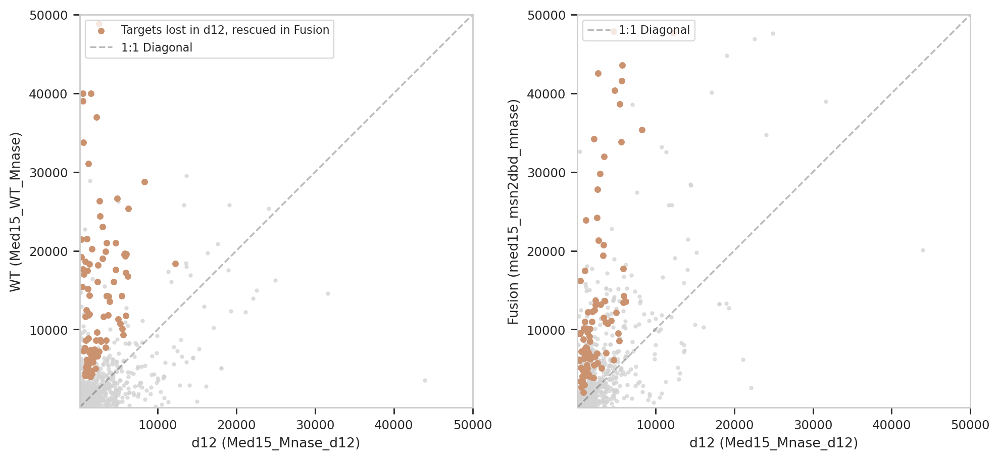

In [15]:
wt_ref_col = 'Med15_WT_Mnase'
fusion_ref_col = 'med15_msn2dbd_mnase'
d12_unfused_col = 'Med15_Mnase_d12'
d12_file = 'data/sumprom_files/d12_fusion_system/sumprom_neg600_to_neg150.pkl.gz'
WT_d12 = pd.read_pickle(d12_file)

# Strip single and double underscore variations of the signal suffix
WT_d12.columns = [
    str(c).replace("__2000bp_signals.gz", "").replace("_2000bp_signals.gz", "")
    for c in WT_d12.columns
]
WT_d12 = WT_d12.loc[~WT_d12.index.duplicated(keep='first')]
WT_sys = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]
d12_sys = WT_d12.loc[~WT_d12.index.duplicated(keep='first')]
common_idx = WT_sys.index.intersection(d12_sys.index)

wt_signal = WT_system_data.loc[common_idx,wt_ref_col]
fusion_signal = d12_sys.loc[common_idx, fusion_ref_col] if fusion_ref_col in d12_sys.columns else pd.Series(0, index=common_idx)
d12_signal = d12_sys.loc[common_idx, d12_unfused_col] if d12_unfused_col in d12_sys.columns else pd.Series(0, index=common_idx)

valid_targs = d12_sys.index.intersection(targets_lost_rescued)

fig2, axes = plt.subplots(1, 2, figsize=(10, 5))
lims = [100, 50000]
x_line = np.array(lims)

# --- Plot 1: WT vs d12 (Targets Lost in d12) ---
ax1 = axes[0]
ax1.scatter(d12_signal, wt_signal, color='lightgrey', s=5, alpha=0.7, rasterized=True)
ax1.scatter(d12_signal[valid_targs], wt_signal[valid_targs], color='#CB926F', s=15, alpha=1, label='Targets lost in d12, rescued in Fusion', rasterized=True)

# Draw 1:1 diagonal reference
ax1.plot(x_line, x_line, 'k--', alpha=0.3, lw=1.2, label='1:1 Diagonal')

ax1.set_xlabel('d12 (Med15_Mnase_d12)')
ax1.set_ylabel('WT (Med15_WT_Mnase)')


# --- Plot 2: Fusion vs d12 (Targets Rescued by Fusion) ---
ax2 = axes[1]
ax2.scatter(d12_signal, fusion_signal, color='lightgrey', s=5, alpha=0.7, rasterized=True)
ax2.scatter(d12_signal[valid_targs], fusion_signal[valid_targs], color='#CB926F', s=15, alpha=1, rasterized=True)

# Draw 1:1 diagonal reference
ax2.plot(x_line, x_line, 'k--', alpha=0.3, lw=1.2, label='1:1 Diagonal')

ax2.set_xlabel('d12 (Med15_Mnase_d12)')
ax2.set_ylabel('Fusion (med15_msn2dbd_mnase)')


# --- Formatting all subplots ---
for ax in axes:
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_box_aspect(1) 
    
axes[0].legend(loc='upper left', fontsize=8)
axes[1].legend(loc='upper left', fontsize=8)
axes[0].grid(False)
axes[1].grid(False)
plt.tight_layout()
plt.show()

## Figure 4C

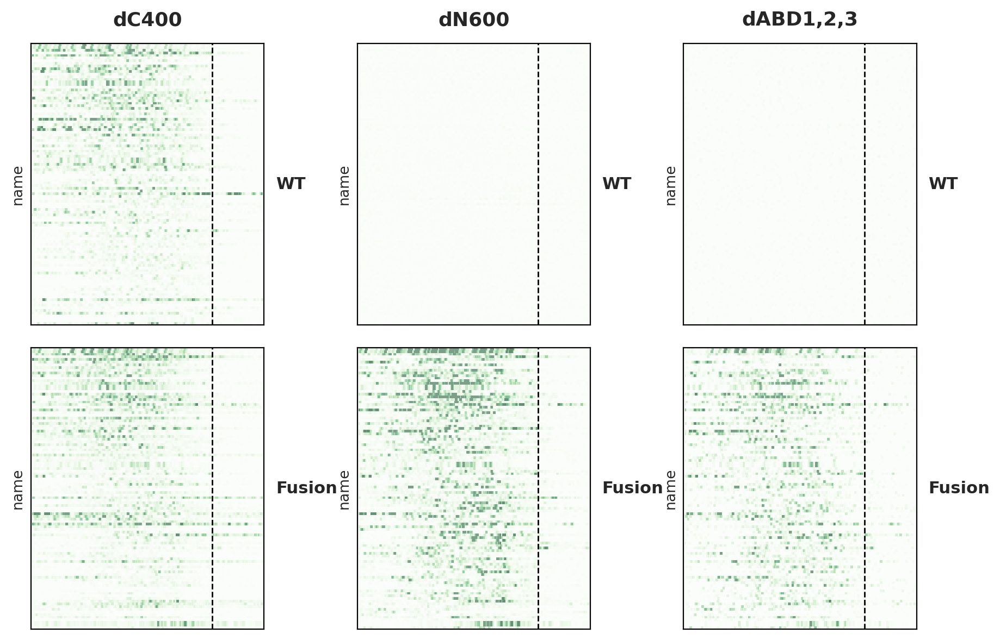

In [76]:
wt_ref_col = 'Med15_WT_Mnase'
wt_signal = WT_sys.loc[common_idx, wt_ref_col]
fusion_ref_col = 'med15_msn2dbd_mnase'
fusion_signal = d12_sys.loc[common_idx, fusion_ref_col] if fusion_ref_col in d12_sys.columns else pd.Series(0, index=common_idx)
target_order = wt_signal.loc[targets_lost_rescued].sort_values(ascending=False).index

rescue_magnitude = fusion_signal.loc[targets_lost_rescued] - d12_signal.loc[targets_lost_rescued]
selected_genes = rescue_magnitude.sort_values(ascending=False).index[:2].tolist()

configs = [
    ('dC400', [
        ('WT', promoter_binding_signals, ['c400'], []),
        ('Fusion', promoter_binding_signals_d12, ['c400'], [])
    ]),
    ('dN600', [
        ('WT', promoter_binding_signals, ['n600'], []),
        ('Fusion', promoter_binding_signals_d12, ['n600'], [])
    ]),
    ('dABD1,2,3', [
        ('WT', promoter_binding_signals, ['dabd1_dabd2_dabd3'], []),
        ('Fusion', promoter_binding_signals_d12, ['dabd1_dabd2_dabd3'], [])
    ])
]

def find_col(df, include_pats, exclude_pats):
    for c in df.columns:
        cl = str(c).lower()
        if all(p.lower() in cl for p in include_pats):
            if exclude_pats and any(e.lower() in cl for e in exclude_pats):
                continue
            return c
    return None

promoter_binding_signals.columns = [str(c).replace("_2000bp_signals.gz", "") for c in promoter_binding_signals.columns]
promoter_binding_signals_d12.columns = [str(c).replace("_2000bp_signals.gz", "") for c in promoter_binding_signals_d12.columns]

window_start, window_end = -700, 200
x_window = np.arange(window_start, window_end + 1)
smoothing_window_heat = 10
smoothing_window_track = 15

def load_and_clean(df_paths, col_name):
    if col_name is None or col_name not in df_paths.columns: return None
    try:
        df = pd.read_pickle(df_paths[col_name].loc["path"]).fillna(0)
        df = df.loc[~df.index.duplicated(keep='first')]
        if df.columns[0] != -2000: df.columns = range(-2000, 2000)
        return df
    except:
        return None

processed_data = {}
highlight = HIGHLIGHT_COLOR if 'HIGHLIGHT_COLOR' in locals() else '#CB926F'

tier_colors = {'WT': 'k', 'Fusion': '#BD5373', 'd12': '#72A65B'}
tier_styles = {'WT': '--', 'd12': '-', 'Fusion': '-'}  

for label, tiers in configs:
    heat_blocks = []
    tracks = {g: {} for g in selected_genes}
    max_y = 0.05
    
    for tier_name, df_source, inc, exc in tiers:
        col_name = find_col(df_source, inc, exc)
        df = load_and_clean(df_source, col_name)
        
        # Heatmap Block
        if df is not None:
            valid = df.index.intersection(target_order)
            block = (df.loc[valid, window_start:window_end]
                     .T.rolling(window=smoothing_window_heat, center=True).mean().T.fillna(0)
                    ).reindex(target_order).fillna(0)
        else:
            block = pd.DataFrame(0, index=target_order, columns=x_window)
            
        heat_blocks.append((tier_name, block))
        
        # Tracks Data
        for g in selected_genes:
            if df is not None and g in df.index:
                g_raw = df.loc[g, window_start:window_end]
                if isinstance(g_raw, pd.DataFrame): g_raw = g_raw.iloc[0]
                t_smooth = g_raw.rolling(window=smoothing_window_track, center=True, min_periods=1).mean().fillna(0)
            else:
                t_smooth = pd.Series(0, index=x_window)
            
            tracks[g][tier_name] = t_smooth
            max_y = max(max_y, t_smooth.max())
            
    processed_data[label] = {
        'heat_blocks': heat_blocks,
        'tier_names': [b[0] for b in heat_blocks],
        'tracks': tracks,
        'ymax': max_y * 1.15
    }

n_cols = len(configs)
n_genes = len(target_order)
idx_TSS, idx_UAS_start, idx_UAS_end = 700, 100, 550
tick_labels = [-700, 0, 200]


max_tiers = max(len(data['tier_names']) for data in processed_data.values())

fig1 = plt.figure(figsize=(3.5 * n_cols, 3.5 * max_tiers))
outer_gs = gridspec.GridSpec(1, n_cols, figure=fig1, wspace=0.4)

for col_idx, (label, _) in enumerate(configs):
    data = processed_data[label]
    heat_blocks = data['heat_blocks']
    n_tiers = len(heat_blocks)
    
    inner_gs = gridspec.GridSpecFromSubplotSpec(n_tiers, 1, subplot_spec=outer_gs[col_idx], hspace=0.08)
    
    for row_idx, (t_name, block_df) in enumerate(heat_blocks):
        ax = fig1.add_subplot(inner_gs[row_idx])
        
        sns.heatmap(
            block_df,
            cmap=pastel_cmap if 'pastel_cmap' in locals() else 'viridis',
            ax=ax, cbar=False, yticklabels=False, xticklabels=False,
            vmin=0.0, vmax=115, rasterized=True
        )
        
        ax.axvline(idx_TSS, color='black', linestyle='--', linewidth=1.0)
        ax.axvspan(idx_UAS_start, idx_UAS_end, color='white', alpha=0.15)
        

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_color('black')
            spine.set_linewidth(0.8)
        
        ax.text(1.05, 0.5, t_name, transform=ax.transAxes, 
                ha='left', va='center', fontsize=11, fontweight='bold')
        

        if row_idx == 0:
            ax.set_title(label, fontsize=13, fontweight='bold', pad=12)

plt.show()

## Figure 4C

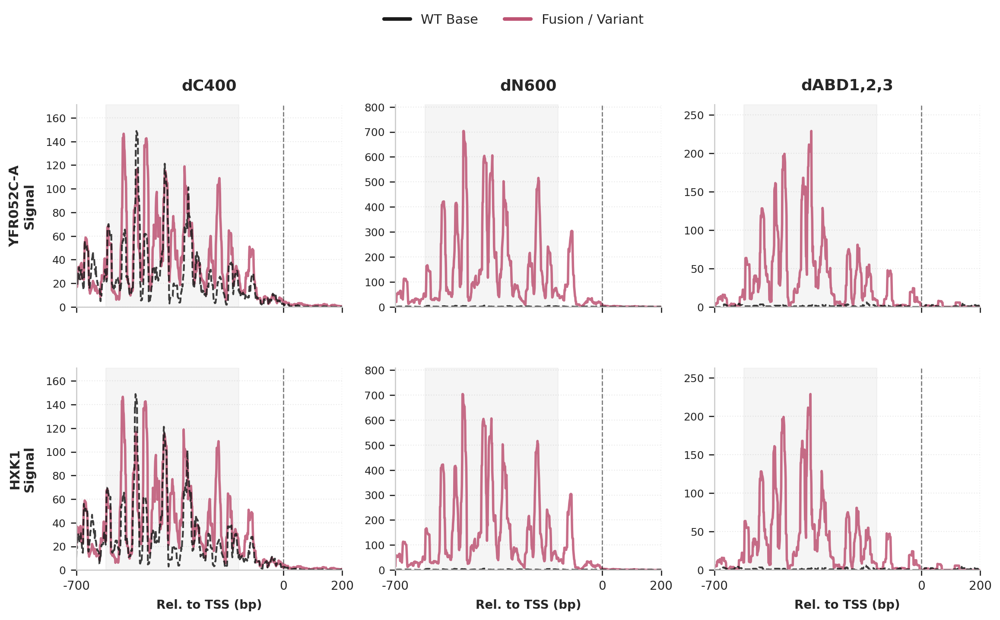

In [17]:
n_selected = len(selected_genes)
fig2, axes2 = plt.subplots(n_selected, n_cols, figsize=(4.5 * n_cols, 3.5 * n_selected), gridspec_kw={'wspace': 0.2, 'hspace': 0.3})
if n_cols == 1: axes2 = np.array(axes2).reshape(-1, 1)

for col_idx, (label, _) in enumerate(configs):
    data = processed_data[label]
    col_ymax = data['ymax']
    
    for row_idx, g in enumerate(selected_genes):
        ax = axes2[row_idx, col_idx]
        
        # Dynamically plot whatever lines exist for this condition
        for tier_name in ['Fusion', 'd12', 'WT']:
            if tier_name in data['tracks'][g]:
                sig = data['tracks'][g][tier_name]
                
                if tier_name == 'WT':
                    ax.plot(x_window, sig.values, color=tier_colors[tier_name], 
                            linestyle=tier_styles[tier_name], linewidth=1.5, 
                            alpha=0.85, label=tier_name)
                else:
                    ax.plot(x_window, sig.values, color=tier_colors[tier_name], 
                            linestyle=tier_styles[tier_name], linewidth=2.0, 
                            alpha=0.85, label=tier_name)
                    
        ax.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
        ax.axvspan(-600, -150, color='gray', alpha=0.08)
        ax.set_xlim(window_start, window_end)
        ax.set_ylim(0, col_ymax)
        ax.set_xticks(tick_labels)
        ax.tick_params(axis='y', labelsize=9, pad=4)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.4)
        
        if row_idx == 0:
            ax.set_title(label, fontsize=13, fontweight='bold', pad=12)
            
        if col_idx == 0:
            ax.set_ylabel(f"{g}\nSignal", fontsize=11, fontweight='bold', labelpad=8)
            
        if row_idx == n_selected - 1:
            ax.set_xticklabels(tick_labels, fontsize=10)
            ax.set_xlabel("Rel. to TSS (bp)", fontsize=10, fontweight='bold', labelpad=6)
        else:
            ax.set_xticklabels([])

# Single master legend for the entire tracks figure (Updated to reflect the dashed line)
legend_elements = [
    Line2D([0], [0], color=tier_colors['WT'], linestyle='-', lw=3, label='WT Base'),
    Line2D([0], [0], color=tier_colors['Fusion'], linestyle='-', lw=3, label='Fusion / Variant')
]
fig2.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=3, fontsize=11, frameon=False)

plt.figure(fig2.number)


plt.show()

## Figure 4E

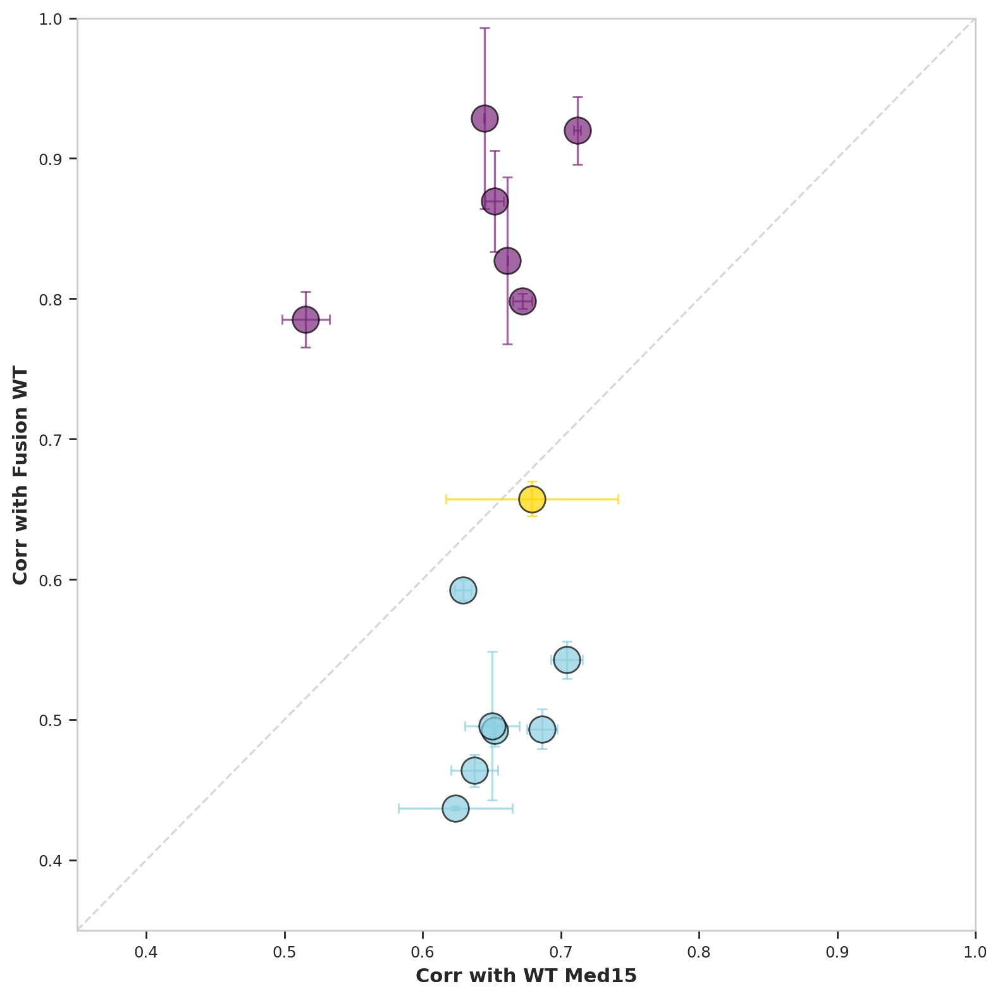

In [30]:
d12_file = 'data/sumprom_files/d12_fusion_system/sumprom_neg600_to_neg150.pkl.gz'
WT_d12 = pd.read_pickle(d12_file)


WT_d12.columns = [
    str(c).replace("__2000bp_signals.gz", "").replace("_2000bp_signals.gz", "")
    for c in WT_d12.columns
]
WT_d12 = WT_d12.loc[~WT_d12.index.duplicated(keep='first')]

WT_sys = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]
d12_sys = WT_d12.loc[~WT_d12.index.duplicated(keep='first')]
common_idx = WT_sys.index.intersection(d12_sys.index)

fold_change_threshold = 1.5
signal_threshold = 4000

targets_lost_rescued = list(common_idx[
    (WT_sys.loc[common_idx, 'Med15_WT_Mnase'] > signal_threshold) &
    (WT_sys.loc[common_idx, 'Med15_WT_Mnase'] > fold_change_threshold * d12_sys.loc[common_idx, 'Med15_Mnase_d12']) &
    (d12_sys.loc[common_idx, 'med15_msn2dbd_mnase'] > signal_threshold) &
    (d12_sys.loc[common_idx, 'med15_msn2dbd_mnase'] > fold_change_threshold * d12_sys.loc[common_idx, 'Med15_Mnase_d12'])
])
valid_targs = d12_sys.index.intersection(targets_lost_rescued)

n_term_abd_map = [
    ('dABD2', 'dABD2', 'Med15_dABD2'),
    ('dABD1', 'dABD1', 'Med15_dABD1'),
    ('d200_400', 'd200_400', 'Med15_200_400'),
    ('dABD3', 'dABD3', 'Med15_dABD3'),
    ('N300', 'N300', 'Med15_N300'),
    ('N400', 'N400', 'Med15_N400')
]

c_term_map = [
    ('C200', 'Med15_Msn2_DBD_C200', 'Med15_C200'),
    ('C300', 'Med15_Msn2_DBD_C300', 'Med15_C300'),
    ('C400', 'Med15_Msn2_DBD_C400', 'Med15_C400'),
    ('C600', 'Med15_Msn2_DBD_C600', 'Med15_C600'),
    ('dDBD', 'dDBD', 'Med15_dDBD'),
    ('d700_900', 'd700_900', 'Med15_700_900'),
    ('d800_1000', 'd800_1000', 'Med15_800_1000'),
    ('dMed2', 'Med15_Fusion_dMed2', 'Med15_WT_dMed2')
]

DOT_DIAMETER = 15

def get_exact_replicate_columns(df, candidate_basenames):
    """Matches ONLY columns where the base prefix exactly equals one of candidate_basenames."""
    matched = []
    for c in df.columns:
        base = re.sub(r'(_r\d+)?_\d+$', '', c)  # Strip trailing replicate indicators
        if base in candidate_basenames:
            matched.append(c)
    return sorted(list(set(matched)))

def get_stats(label, d12_col, wt_col):
    col_to_check = d12_col if (d12_col and d12_col in d12_sys.columns) else wt_col
    sys_df = d12_sys if (d12_col and d12_col in d12_sys.columns) else WT_sys
    if not col_to_check or col_to_check not in sys_df.columns:
        return None
    s_mut = sys_df.loc[valid_targs, col_to_check]
    s_fusion_ref = d12_sys.loc[valid_targs, 'med15_msn2dbd_mnase']
    s_wt_ref = WT_sys.loc[valid_targs, 'Med15_WT_Mnase']
    return s_mut.corr(s_fusion_ref), s_mut.corr(s_wt_ref), s_mut.mean()


fig, ax1 = plt.subplots(figsize=(8, 8))

for mapping, color, group_label in [(n_term_abd_map, '#7d287d', 'N-Term/ABD'), (c_term_map, '#8BCFE0', 'C-Terminal')]:
    for label, d12_col, wt_col in mapping:
        st = get_stats(label, d12_col, wt_col)
        if not st:
            continue
            
 
        wt_bases = [wt_col, wt_col.replace('Med15_WT_', 'Med15_'), wt_col.replace('Med15_', 'Med15_Mnase_')]
        if wt_col == 'Med15_WT_dMed2': 
            wt_bases += ['Med15_dMed2', 'Med15_WT_dMed2']
            
        wt_reps = get_exact_replicate_columns(wt_system_repeats, wt_bases)
        
        wt_corrs = []
        for r in wt_reps:
            c = wt_system_repeats.loc[valid_targs, r].corr(WT_sys.loc[valid_targs, 'Med15_WT_Mnase'])
            if pd.notna(c): wt_corrs.append(c)
            
        x_err = np.std(wt_corrs, ddof=1) if len(wt_corrs) > 1 else 0.0


        if label in ['d700_900', 'd800_1000', 'dDBD', 'dMed2']:
            target_df = Repeats
            msn2_bases = [d12_col]
            if d12_col == 'Med15_Fusion_dMed2': 
                msn2_bases += ['Fusion_dMed2']
        elif label.startswith('C') or 'C' in label:
            target_df = msn2_dbd_c_repeats
            msn2_bases = [d12_col, d12_col.replace('Med15_Msn2_DBD_', '')]
        else:
            target_df = msn2_dbd_repeats
            msn2_bases = [d12_col, f"Med15_{d12_col}", f"med15_msn2dbd_mnase_{d12_col}"]

        msn2_reps = get_exact_replicate_columns(target_df, msn2_bases)
        
        msn2_corrs = []
        for r in msn2_reps:
            c = target_df.loc[valid_targs, r].corr(d12_sys.loc[valid_targs, 'med15_msn2dbd_mnase'])
            if pd.notna(c): msn2_corrs.append(c)
            
        y_err = np.std(msn2_corrs, ddof=1) if len(msn2_corrs) > 1 else 0.0

        marker_color = 'gold' if label == 'dMed2' else color

        ax1.errorbar(
            st[1], st[0], xerr=x_err, yerr=y_err, fmt='o', color=marker_color,
            markersize=DOT_DIAMETER, markeredgecolor='black', alpha=0.7, capsize=3, zorder=5
        )

ax1.set_xlim(0.35, 1)
ax1.set_ylim(0.35, 1)
ax1.plot([0.35,  1], [0.35, 1], '--', color='gray', alpha=0.3)
ax1.set_xlabel("Corr with WT Med15", fontsize=11, fontweight='bold')
ax1.set_ylabel("Corr with Fusion WT", fontsize=11, fontweight='bold')
ax1.grid(False)
plt.tight_layout()
plt.show()

## Figure 4F

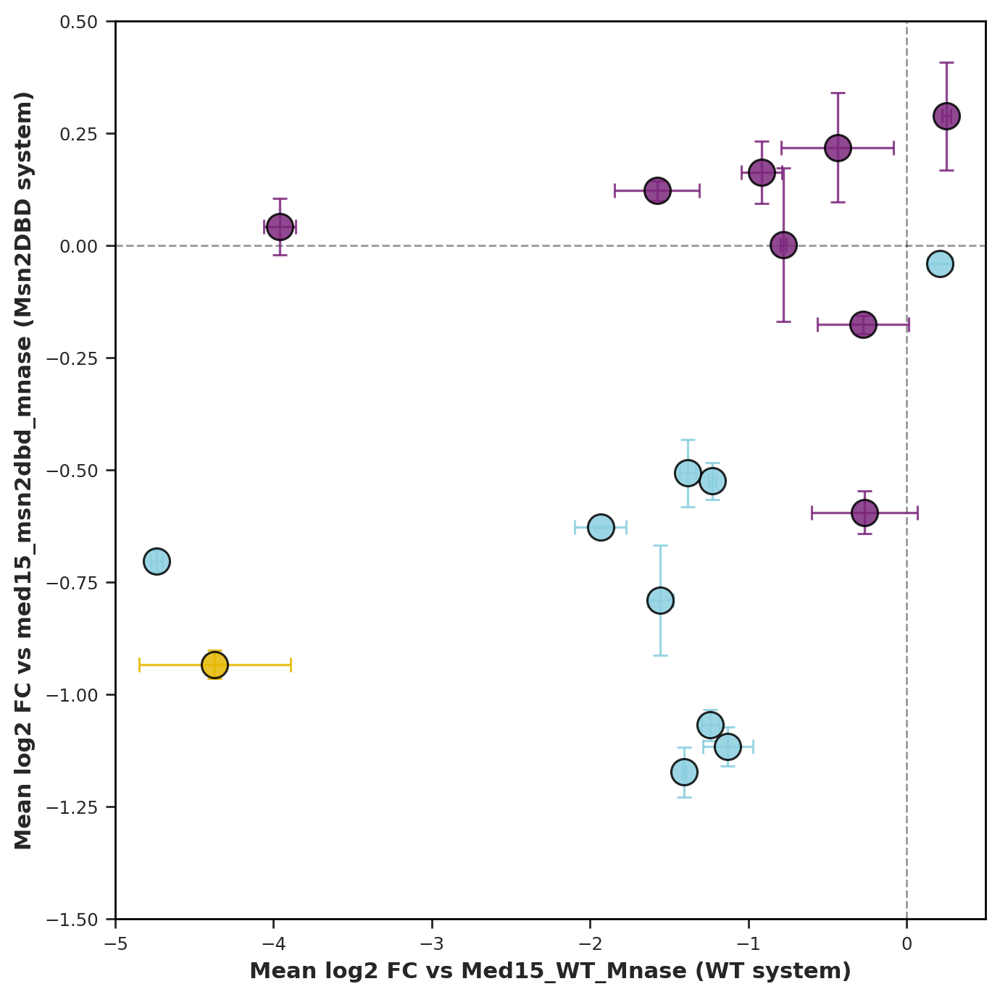

In [31]:
mutant_definitions = [
    # N-terminal / ABD mutants 
    ('200_400', 'Med15_200_400', 'd200_400', 'N'),
    ('N100', 'Med15_N100', 'N100', 'N'),
    ('N300', 'Med15_N300', 'N300', 'N'),
    ('N400', 'Med15_N400', 'N400', 'N'),
    ('N600', 'Med15_N600', 'N600', 'N'),
    ('dABD1', 'Med15_dABD1', 'dABD1', 'N'),
    ('dABD2', 'Med15_dABD2', 'dABD2', 'N'),
    ('dABD3', 'Med15_dABD3', 'dABD3', 'N'),
    
    # C-terminal deletions
    ('C100', 'Med15_C100', 'Med15_Msn2_DBD_C100', 'C'),
    ('C200', 'Med15_C200', 'Med15_Msn2_DBD_C200', 'C'),
    ('C300', 'Med15_C300', 'Med15_Msn2_DBD_C300', 'C'),
    ('C400', 'Med15_C400', 'Med15_Msn2_DBD_C400', 'C'),
    ('C600', 'Med15_C600', 'Med15_Msn2_DBD_C600', 'C'),
    ('C700', 'Med15_C700', 'Med15_Msn2_DBD_C700', 'C'),
    
    # Internal C-term & Tail mutants
    ('700_900', 'Med15_700_900', 'd700_900', 'EXP'),
    ('800_1000', 'Med15_800_1000', 'd800_1000', 'EXP'),
    ('dDBD', 'Med15_dDBD', 'dDBD', 'EXP'),
    ('dMed2', 'Med15_WT_dMed2', 'Med15_Fusion_dMed2', 'EXP')
]

# Ensure valid target index
common_targets = WT_system_data.index.intersection(targets_lost_rescued).intersection(WT_d12.index)

# 1. WT System repeats reference
wt_ref_candidates = [c for c in wt_system_repeats.columns if 'wt' in c.lower() and re.search(r'_\d+$', c)]
ref_sig_wt = wt_system_repeats[wt_ref_candidates].mean(axis=1)

# 2. Msn2 N-term repeats reference
msn2_n_ref_cand = [c for c in msn2_dbd_repeats.columns if ('med15_msn2dbd_mnase' in c.lower() or 'wt' in c.lower()) and re.search(r'_\d+$', c)]
ref_sig_msn2_n = msn2_dbd_repeats[msn2_n_ref_cand].mean(axis=1)

# 3. Msn2 C-term repeats reference
msn2_c_ref_cand = [c for c in msn2_dbd_c_repeats.columns if ('med15_msn2dbd_mnase' in c.lower() or 'wt' in c.lower()) and re.search(r'_\d+$', c)]
ref_sig_msn2_c = msn2_dbd_c_repeats[msn2_c_ref_cand].mean(axis=1)

# 4. Experimental Repeats Msn2 reference
exp_msn2_ref_cand = [c for c in Repeats.columns if ('med15_msn2dbd_mnase' in c.lower() or 'med15_msn2_dbd_wt' in c.lower()) and re.search(r'_\d+$', c)]
ref_sig_exp_msn2 = Repeats[exp_msn2_ref_cand].mean(axis=1) if exp_msn2_ref_cand else ref_sig_msn2_c

def get_exact_replicate_columns(df, candidate_basenames):
    """Matches ONLY columns where the base prefix exactly equals one of candidate_basenames."""
    matched = []
    for c in df.columns:
        base = re.sub(r'(_r\d+)?_\d+$', '', c)
        if base in candidate_basenames:
            matched.append(c)
    return sorted(list(set(matched)))

def calculate_replicate_log2_fcs(df, rep_cols, ref_sig, targets):
    """Computes mean log2 FC over target genes strictly filtering for finite, positive signals."""
    rep_means = []
    for c in rep_cols:
        s_mut = df.loc[targets, c]
        s_ref = ref_sig.loc[targets]
        
        # Guard strictly against zeros, NaNs, and negative values
        valid_mask = (s_mut > 0) & (s_ref > 0) & s_mut.notna() & s_ref.notna()
        if valid_mask.sum() == 0:
            continue
            
        fc = s_mut[valid_mask] / s_ref[valid_mask]
        finite_fc = fc[np.isfinite(fc) & (fc > 0)]
        
        if len(finite_fc) > 0:
            mean_log2 = np.log2(finite_fc).mean()
            if np.isfinite(mean_log2):
                rep_means.append(mean_log2)
                
    return rep_means


plot_records = []

for label, wt_col, msn2_col, category in mutant_definitions:
    # ---------------- WT SYSTEM REPLICATES ----------------
    wt_bases = [wt_col, wt_col.replace('Med15_WT_', 'Med15_'), wt_col.replace('Med15_', 'Med15_Mnase_')]
    if wt_col == 'Med15_WT_dMed2':
        wt_bases += ['Med15_dMed2', 'Med15_WT_dMed2']
        
    wt_reps = get_exact_replicate_columns(wt_system_repeats, wt_bases)
    wt_means = calculate_replicate_log2_fcs(wt_system_repeats, wt_reps, ref_sig_wt, common_targets)
    

    if category == 'N':
        msn2_bases = [msn2_col, f"Med15_{msn2_col}", f"med15_msn2dbd_mnase_{msn2_col}"]
        msn2_reps = get_exact_replicate_columns(msn2_dbd_repeats, msn2_bases)
        msn2_means = calculate_replicate_log2_fcs(msn2_dbd_repeats, msn2_reps, ref_sig_msn2_n, common_targets)
        
    elif category == 'C':
        msn2_bases = [msn2_col, msn2_col.replace('Med15_Msn2_DBD_', '')]
        msn2_reps = get_exact_replicate_columns(msn2_dbd_c_repeats, msn2_bases)
        msn2_means = calculate_replicate_log2_fcs(msn2_dbd_c_repeats, msn2_reps, ref_sig_msn2_c, common_targets)
        
    else:  
        msn2_bases = [msn2_col]
        if msn2_col == 'Med15_Fusion_dMed2':
            msn2_bases += ['Fusion_dMed2']
        msn2_reps = get_exact_replicate_columns(Repeats, msn2_bases)
        msn2_means = calculate_replicate_log2_fcs(Repeats, msn2_reps, ref_sig_exp_msn2, common_targets)
        
    # Calculate means and errors
    x_mean = np.mean(wt_means) if len(wt_means) > 0 else np.nan
    x_err = np.std(wt_means, ddof=1) if len(wt_means) > 1 else 0.0
    
    y_mean = np.mean(msn2_means) if len(msn2_means) > 0 else np.nan
    y_err = np.std(msn2_means, ddof=1) if len(msn2_means) > 1 else 0.0

    
    if np.isfinite(x_mean) and np.isfinite(y_mean):
        plot_records.append({
            'label': label,
            'x_mean': x_mean,
            'y_mean': y_mean,
            'x_err': x_err,
            'y_err': y_err,
            'category': category
        })

df_plot = pd.DataFrame(plot_records)

fig, ax = plt.subplots(figsize=(7,7))
texts = []

for _, row in df_plot.iterrows():
    # Color logic
    if row['label'] == 'dMed2':
        color = '#E5B800' 
    elif row['category'] == 'N':
        color = '#7d287d'
    else:
        color = '#8BCFE0'  

    ax.errorbar(
        row['x_mean'], row['y_mean'], 
        xerr=row['x_err'], yerr=row['y_err'],
        color=color, alpha=0.85, fmt='o',
        markersize=13, markeredgecolor='black', markeredgewidth=1.1,
        capsize=3.5, elinewidth=1.2, capthick=1.2, zorder=4
    )
    



ax.axhline(0, color='black', linestyle='--', alpha=0.4, linewidth=1.0, zorder=1)
ax.axvline(0, color='black', linestyle='--', alpha=0.4, linewidth=1.0, zorder=1)


ax.set_xlim(-5, 0.5)
ax.set_ylim(-1.5, 0.5)

ax.set_xlabel('Mean log2 FC vs Med15_WT_Mnase (WT system)', fontsize=11, fontweight='bold')
ax.set_ylabel('Mean log2 FC vs med15_msn2dbd_mnase (Msn2DBD system)', fontsize=11, fontweight='bold')

for spine in ax.spines.values():
    spine.set_linewidth(1.0)
    spine.set_color('black')

ax.grid(False)
plt.tight_layout()


plt.show()

## Figure 4G

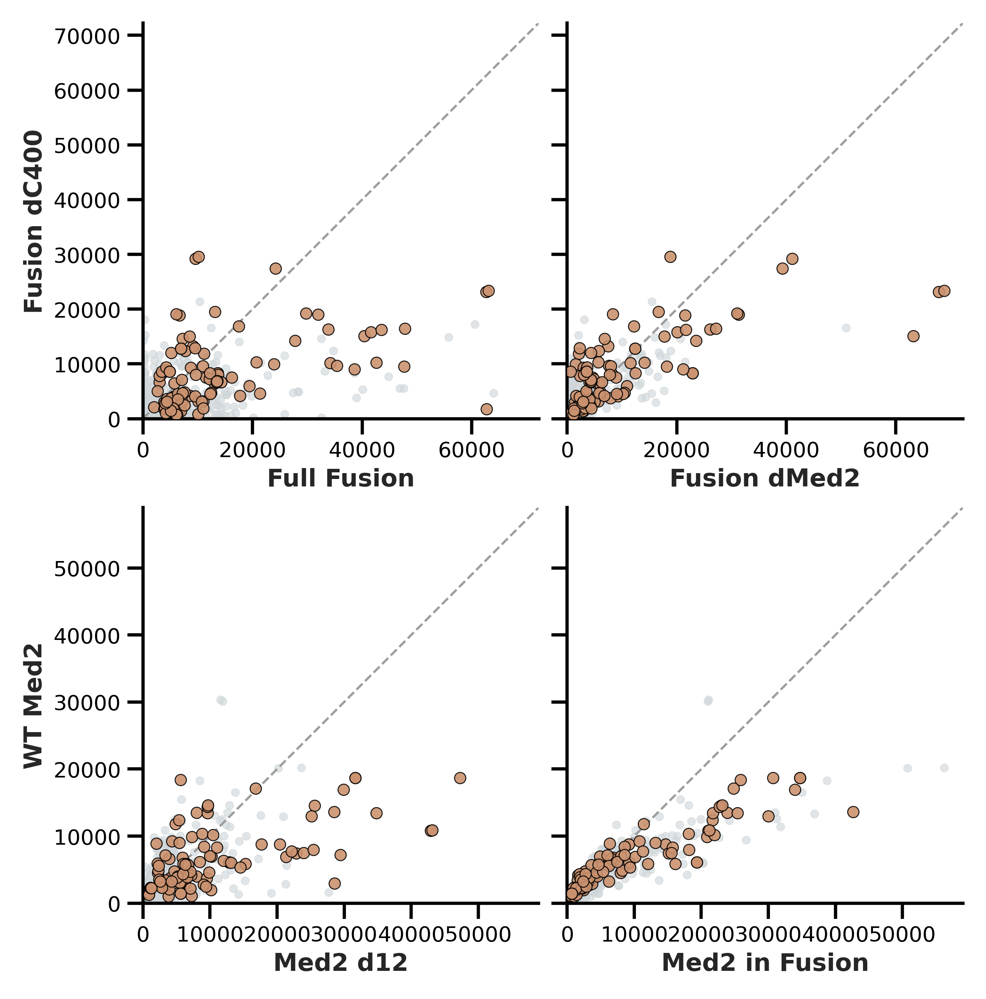

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

unique_strains_config = {
    'WT Med2': ('Med2_Mnase', WT_sys),
    'Med2 d12': ('d12_Med2_Mnase', d12_sys),
    'Med2 in Fusion': ('Med15_Msn2DBD_Med2_Mnase', d12_sys),
    'Full Fusion': ('med15_msn2dbd_mnase', d12_sys),
    'Fusion dC400': ('Med15_Msn2_DBD_C400', d12_sys),
    'Fusion dMed2': ('Med15_Fusion_dMed2', d12_sys)
}

all_data = pd.DataFrame(index=common_idx)
for label, (col_name, df) in unique_strains_config.items():
    if col_name in df.columns:
        all_data[label] = df.loc[common_idx, col_name]

row_configs = [
    [
        {'x': 'Full Fusion',    'y': 'Fusion dC400'},
        {'x': 'Fusion dMed2',   'y': 'Fusion dC400'}
    ],
    [
        {'x': 'Med2 d12',       'y': 'WT Med2'},
        {'x': 'Med2 in Fusion', 'y': 'WT Med2'}
    ]
]

fig, axes = plt.subplots(2, 2, figsize=(4.2, 4.2), dpi=300)

for r in range(2):
    # Calculate a unified min/max for the entire row to ensure 1:1 square scaling
    cols_in_row = [row_configs[r][0]['x'], row_configs[r][1]['x'], row_configs[r][0]['y']]
    row_df = all_data[cols_in_row].dropna()
    min_val = row_df.min().min()
    max_val = row_df.max().max()
    padding = (max_val - min_val) * 0.05
    lims = [max(0, min_val - padding), max_val + padding]

    for c in range(2):
        ax = axes[r, c]
        cfg = row_configs[r][c]
        x_col, y_col = cfg['x'], cfg['y']

        pair_df = all_data[[x_col, y_col]].dropna()
        pair_targets = pair_df.index.isin(valid_targs)

        x_bg, y_bg = pair_df.loc[~pair_targets, x_col], pair_df.loc[~pair_targets, y_col]
        x_tg, y_tg = pair_df.loc[pair_targets, x_col], pair_df.loc[pair_targets, y_col]

        # 1. Background genes
        ax.scatter(x_bg, y_bg, c='#cfd8dc', alpha=0.65, s=6, edgecolors='lightgrey', linewidths=0.2, rasterized=True)

        # 2. Rescued targets
        ax.scatter(x_tg, y_tg, c='#CB926F', alpha=0.9, s=12, edgecolors='black', linewidths=0.3, zorder=3)

        # Diagonal identity line (y = x)
        ax.plot(lims, lims, color='#9e9e9e', linestyle='--', linewidth=0.7, zorder=1)
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_box_aspect(1)

        # Labels
        ax.set_xlabel(x_col, fontsize=7.5, fontweight='bold', labelpad=2)
        if c == 0:
            ax.set_ylabel(y_col, fontsize=7.5, fontweight='bold', labelpad=2)
        else:
            ax.tick_params(axis='y', labelleft=False)

        # Explicitly disable grids and enforce solid black axes/ticks
        ax.grid(False)
        ax.tick_params(axis='both', which='major', labelsize=6.5, pad=2, color='black', labelcolor='black')
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['bottom'].set_color('black')
        ax.spines['left'].set_color('black')
        ax.spines['bottom'].set_linewidth(1.0)
        ax.spines['left'].set_linewidth(1.0)

plt.subplots_adjust(wspace=0.15, hspace=0.35)
plt.tight_layout(pad=0.5)
plt.show()

# SupFigure 1

/tmp/ipykernel_1317918/2224172204.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



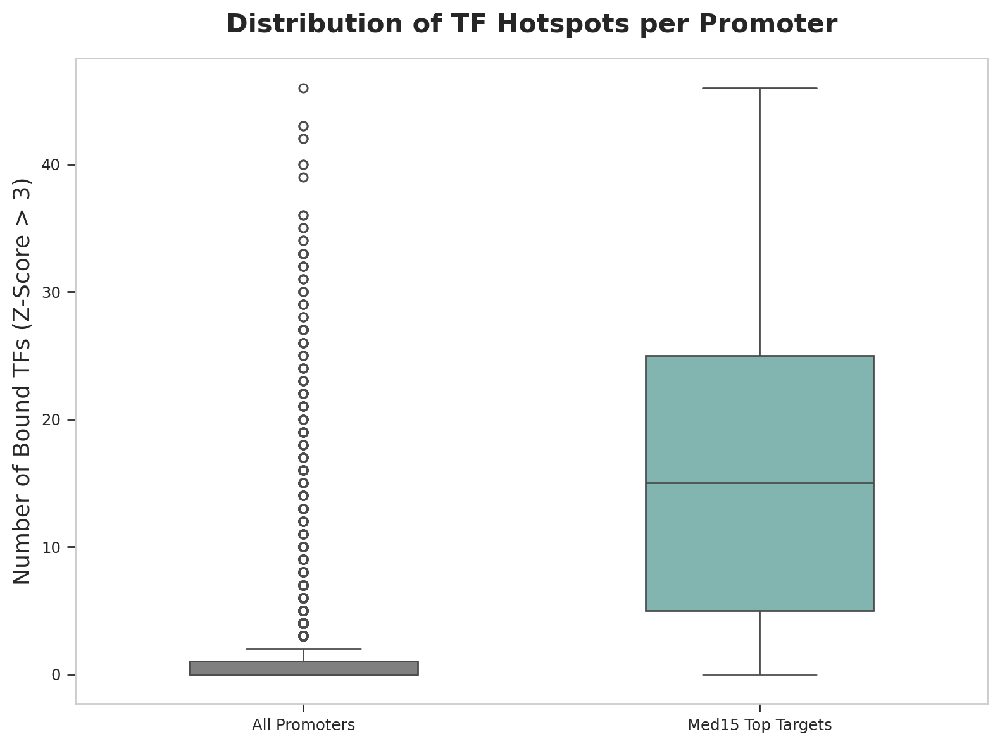

In [33]:
z_scores = (all_TFs - all_TFs.mean()) / all_TFs.std()

valid_targets = z_scores.index.intersection(top_200_med15_targets)
z_threshold = 3


tf_counts_all = (z_scores > z_threshold).sum(axis=1)

df_all = pd.DataFrame({
    'Bound TF Count': tf_counts_all,
    'Group': 'All Promoters'
})

df_top = pd.DataFrame({
    'Bound TF Count': tf_counts_all.loc[valid_targets],
    'Group': 'Med15 Top Targets'
})

df_plot = pd.concat([df_all, df_top]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 6))

# Box plot
sns.boxplot(
    data=df_plot,
    x='Group',
    y='Bound TF Count',
    palette={'All Promoters': 'gray', 'Med15 Top Targets': '#7ABDB5'},
    width=0.5,
    ax=ax
)

ax.set_title('Distribution of TF Hotspots per Promoter', fontsize=15, fontweight='bold', pad=15)
ax.set_xlabel('') 
ax.set_ylabel(f'Number of Bound TFs (Z-Score > {z_threshold})', fontsize=13)
ax.grid(False)
plt.tight_layout()
plt.show()

Text(0.5, 0, 'Correlation')

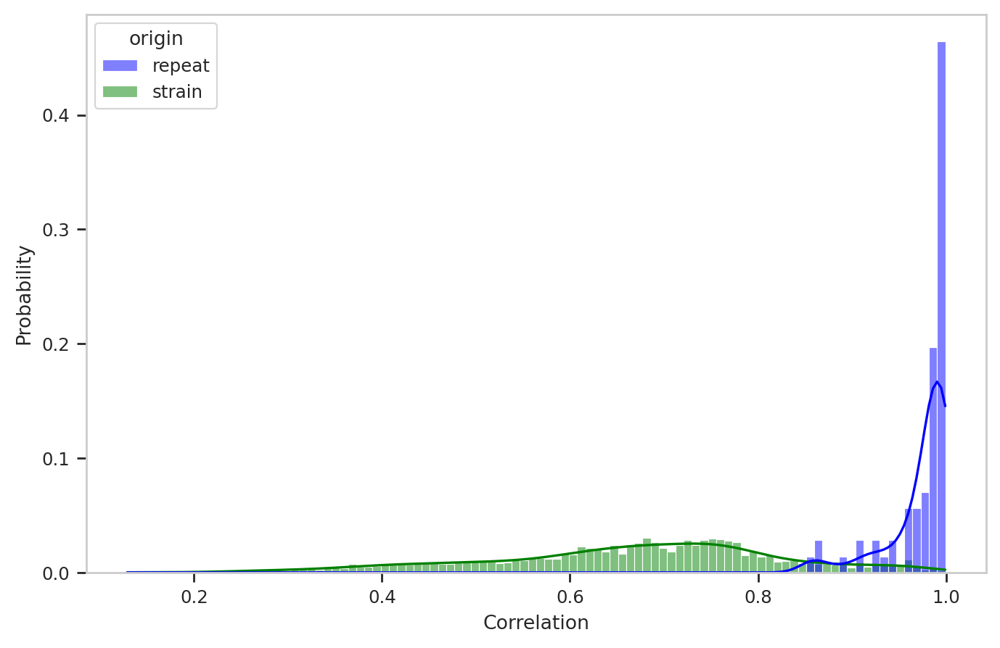

In [35]:
def get_strain_name(col):
    return re.sub(r'_\d+$', '', col)  


def get_repeat_pairs(df):
    pairs = {}
    for col in df.columns:
        strain = get_strain_name(col)
        if strain not in pairs:
            pairs[strain] = []
        pairs[strain].append(col)
    return {k: v for k, v in pairs.items() if len(v) == 2}  

def filter_repeats(df, threshold=0.85):
    repeat_pairs = get_repeat_pairs(df)
    passed = []
    filtered_corrs = []
    
    for strain, (rep1, rep2) in repeat_pairs.items():
        corr = df[[rep1, rep2]].corr().iloc[0, 1]
        if corr >= threshold:
            passed.extend([rep1, rep2])
            filtered_corrs.append(corr)  

    return df[passed], filtered_corrs  




df_filtered, repeat_corrs = filter_repeats(Repeats)


repeat_pairs = get_repeat_pairs(df_filtered)
df_avg = pd.DataFrame()
for strain, (rep1, rep2) in repeat_pairs.items():
    df_avg[strain] = df_filtered[[rep1, rep2]].mean(axis=1)

strain_corr_matrix = df_avg.corr()
strain_corr_values = strain_corr_matrix.values[np.triu_indices_from(strain_corr_matrix, k=1)]

comp_df = pd.concat([pd.DataFrame(dict(zip(repeat_corrs, repeat('repeat'))), index=['origin']).T,
pd.DataFrame(dict(zip(strain_corr_values, repeat('strain'))), index=['origin']).T,], axis=0)

a = comp_df.reset_index()

fig,ax = plt.subplots(figsize=(8, 5)) 
sns.histplot(data=a, x='index', hue='origin', common_norm=False, bins=100, kde=True, stat='probability', palette={'repeat': 'blue', 'strain': 'green'})
ax.grid(False)
ax.set_xlabel('Correlation')

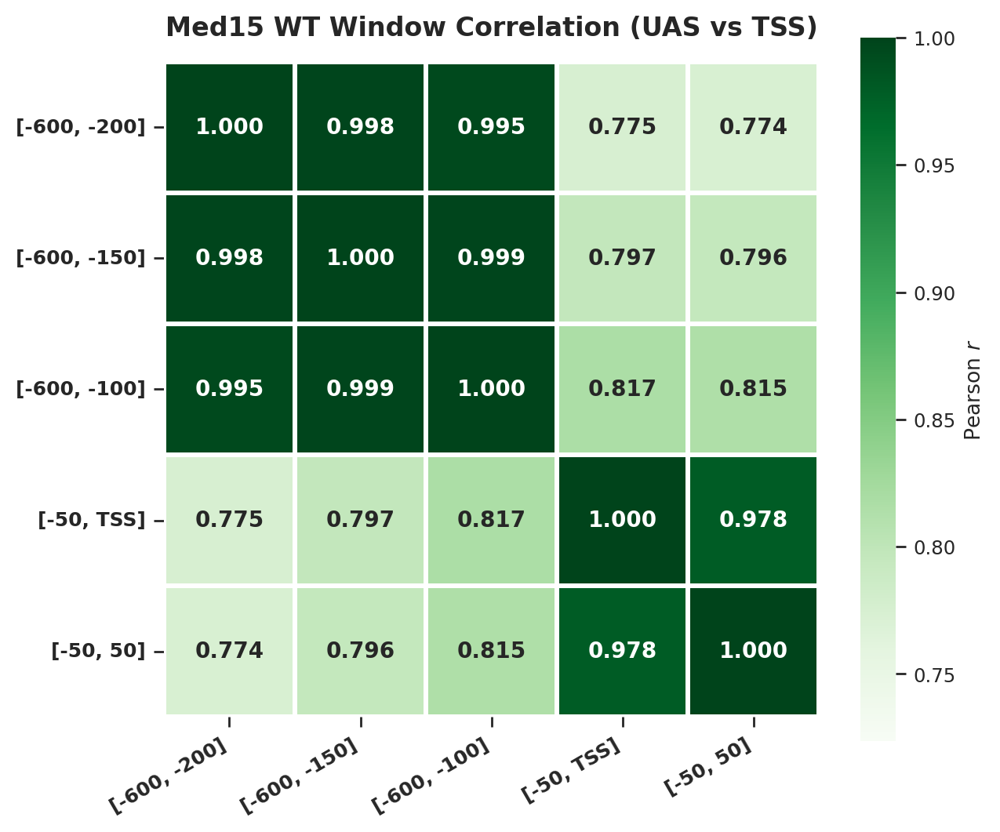

In [37]:
sumprom_dir = 'data/sumprom_files/WT_system/'


window_patterns = {
    '[-600, -200]': ['sumprom_neg600_to_neg200*'],
    '[-600, -150]': ['sumprom_neg600_to_neg150*'],
    '[-600, -100]': ['sumprom_neg600_to_neg100*'],
    '[-50, TSS]':   ['sumprom_neg50_to_0*', 'sumprom_neg50_to_tss*', 'sumprom_neg50_to_TSS*'],
    '[-50, 50]':    ['sumprom_neg50_to_50*', 'sumprom_neg50_to_pos50*']
}

combined_wt = {}

for label, patterns in window_patterns.items():
    matched_files = []
    for pat in patterns:
        matched_files.extend(glob.glob(os.path.join(sumprom_dir, pat)))
    
    if not matched_files:
        raise FileNotFoundError(f"No file found matching {patterns} in {sumprom_dir}")
    
    path = matched_files[0]

    if path.endswith('.csv') or path.endswith('.csv.gz'):
        df = pd.read_csv(path, index_col=0)
    else:
        df = pd.read_pickle(path)

    df.columns = [str(c).replace("_2000bp_signals.gz", "") for c in df.columns]
    df = df.loc[~df.index.duplicated(keep='first')]

    # Find the Med15 WT column
    wt_cols = [c for c in df.columns if 'med15' in str(c).lower() and 'wt' in str(c).lower()]
    if not wt_cols:
        raise KeyError(f"Could not find Med15 WT column in {label} ({path})")

    combined_wt[label] = df[wt_cols[0]]

data_df = pd.DataFrame(combined_wt).dropna()
corr_matrix = data_df.corr(method='pearson')

# =====================================================================
# 3. PLOT HEATMAP (GREENS)
# =====================================================================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# Dynamic lower bound so off-diagonal UAS vs TSS correlations don't clip
min_corr = max(0.0, float(corr_matrix.min().min()) - 0.05)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap='Greens',
    vmin=min_corr,
    vmax=1.0,
    cbar=True,
    cbar_kws={'label': 'Pearson $r$'},
    square=True,
    linewidths=1.5,
    linecolor='white',
    ax=ax,
    annot_kws={"size": 10, "weight": "bold"}
)

ax.set_title("Med15 WT Window Correlation (UAS vs TSS)", fontsize=12, fontweight='bold', pad=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9, fontweight='bold')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

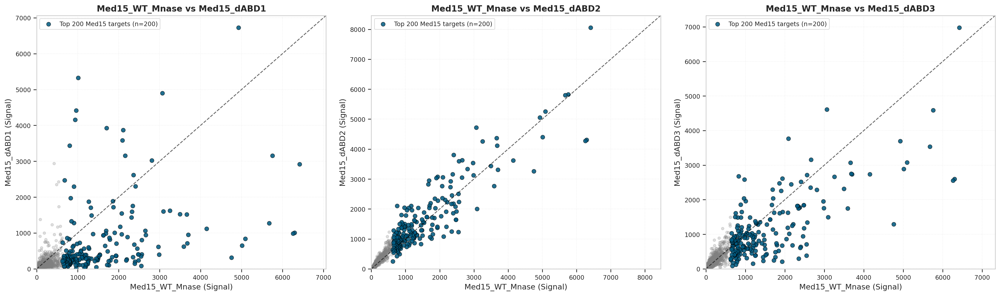

In [39]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg50_to_50.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    sumprom_df = pd.read_csv(sumprom_path, index_col=0)
else:
    sumprom_df = pd.read_pickle(sumprom_path)


sumprom_df.columns = [str(c).replace("_2000bp_signals.gz", "") for c in sumprom_df.columns]
sumprom_df = sumprom_df.loc[~sumprom_df.index.duplicated(keep='first')]

wt_col = 'Med15_WT_Mnase'
if wt_col not in sumprom_df.columns:
    candidates = [c for c in sumprom_df.columns if 'med15' in c.lower() and 'wt' in c.lower()]
    if candidates:
        wt_col = candidates[0]
    else:
        raise KeyError(f"Could not find Med15 WT column in {sumprom_df.columns.tolist()}")

wt_series = sumprom_df[wt_col].dropna()

zscore_series = pd.Series(
    stats.zscore(wt_series, ddof=1, nan_policy='omit'),
    index=wt_series.index,
    name=f'{wt_col}_zscore'
)

top_200_med15_targets = zscore_series.sort_values(ascending=False).head(200).index.tolist()
mutant_queries = ['dABD1', 'dABD2', 'dABD3']
mutant_cols = []

for q in mutant_queries:
    match = [c for c in sumprom_df.columns if q.lower() in c.lower() and 'fusion' not in c.lower() and 'dabd1_dabd2' not in c.lower()]
    if match:
        mutant_cols.append(match[0])
    else:
        raise KeyError(f"Could not find column for {q} in sumprom_df columns: {sumprom_df.columns.tolist()}")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, mut_col in enumerate(mutant_cols):
    ax = axes[i]
    

    ax.scatter(
        sumprom_df[wt_col], 
        sumprom_df[mut_col], 
        alpha=0.25, 
        color='grey', 
        s=15, 
        rasterized=True
    )
    

    valid_targets = [g for g in top_200_med15_targets if g in sumprom_df.index]
    ax.scatter(
        sumprom_df.loc[valid_targets, wt_col], 
        sumprom_df.loc[valid_targets, mut_col],
        alpha=0.85, 
        color='#005b82', 
        edgecolor='black', 
        linewidth=0.5, 
        s=35, 
        rasterized=True,
        label=f'Top 200 Med15 targets (n={len(valid_targets)})'
    )

   
    max_val = max(sumprom_df[wt_col].max(), sumprom_df[mut_col].max()) * 1.05
    ax.plot([0, max_val], [0, max_val], '--', color='black', alpha=0.6, linewidth=1.2)
    
    ax.set_xlim(0, max_val)
    ax.set_ylim(0, max_val)
    ax.set_xlabel(f'{wt_col} (Signal)', fontsize=11)
    ax.set_ylabel(f'{mut_col} (Signal)', fontsize=11)
    ax.set_title(f"{wt_col} vs {mut_col}", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', frameon=True)
    ax.grid(True, linestyle=':', alpha=0.35)

plt.tight_layout()

plt.show()

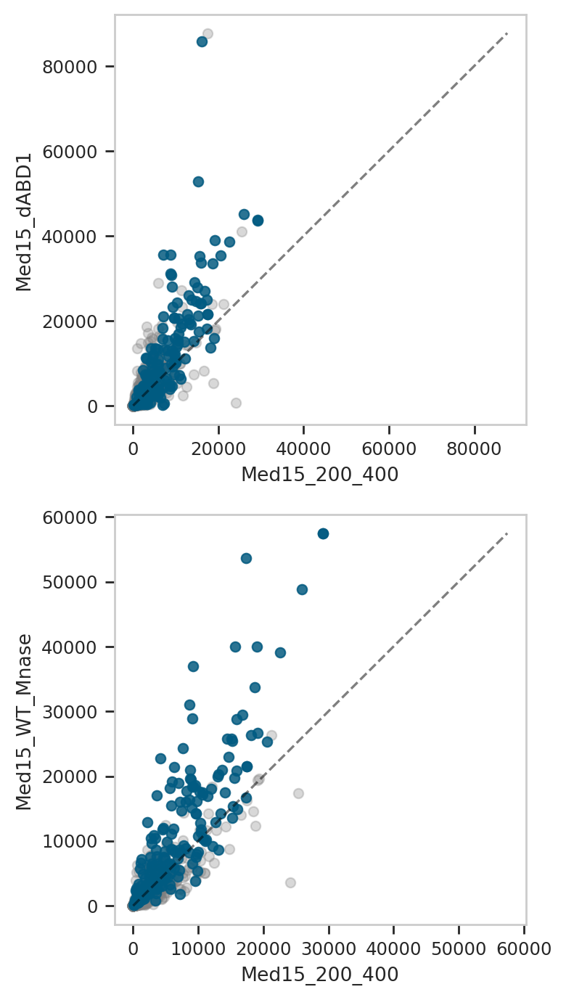

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(4, 7))

ax1 = axes[0]
ax1.scatter(
    WT_system_data['Med15_200_400'], WT_system_data['Med15_dABD1'], 
    alpha=0.3, color='grey', rasterized=True, label='All genes'
)
ax1.scatter(
    WT_system_data['Med15_200_400'].loc[top_200_med15_targets], WT_system_data['Med15_dABD1'].loc[top_200_med15_targets],
    alpha=0.8, color='#005b82', edgecolor='#005b82',
    label='Top Med15 targets', rasterized=True
)

max_val1 = max(WT_system_data['Med15_200_400'].max(), WT_system_data['Med15_dABD1'].max())
ax1.plot([0, max_val1], [0, max_val1], '--', color='black', alpha=0.5)

 

ax1.set_xlabel('Med15_200_400')
ax1.set_ylabel('Med15_dABD1')
ax1.grid(False)
ax2 = axes[1]
ax2.scatter(
    WT_system_data['Med15_200_400'], WT_system_data['Med15_WT_Mnase'], 
    alpha=0.3, color='grey', rasterized=True, label='All genes'
)
ax2.scatter(
    WT_system_data['Med15_200_400'].loc[top_200_med15_targets], WT_system_data['Med15_WT_Mnase'].loc[top_200_med15_targets],
    alpha=0.8, color='#005b82', edgecolor='#005b82',
    label='Top Med15 targets', rasterized=True
)

max_val2 = max(WT_system_data['Med15_200_400'].max(), WT_system_data['Med15_WT_Mnase'].max())
ax2.plot([0, max_val2], [0, max_val2], '--', color='black', alpha=0.5)


ax2.set_xlabel('Med15_200_400')
ax2.set_ylabel('Med15_WT_Mnase')
plt.grid(False)
plt.tight_layout()
plt.show()

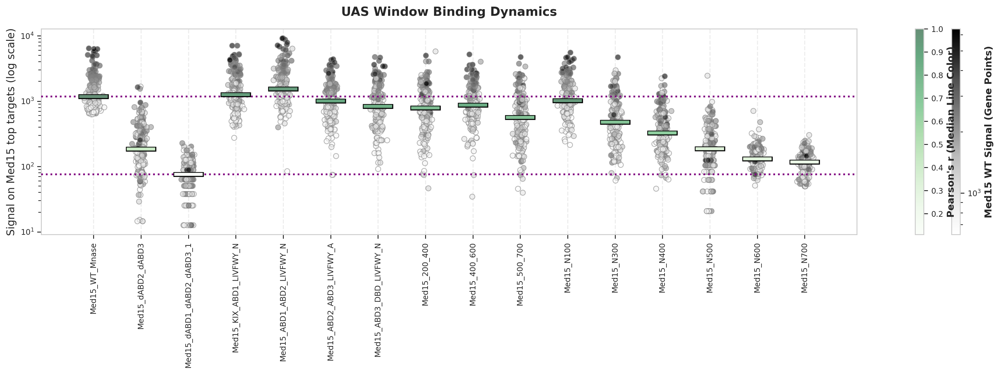

In [48]:

WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

# =====================================================================
# 2. ISOLATE REQUESTED COLUMNS AND TARGETS
# =====================================================================
cols_to_plot = [
    'Med15_WT_Mnase', 'Med15_dABD2_dABD3', 'Med15_dABD1_dABD2_dABD3_1', 
    'Med15_KIX_ABD1_LIVFWY_N', 'Med15_ABD1_ABD2_LIVFWY_N', 'Med15_ABD2_ABD3_LIVFWY_A', 
    'Med15_ABD3_DBD_LIVFWY_N', 'Med15_200_400', 'Med15_400_600', 'Med15_500_700',
    'Med15_N100', 'Med15_N300', 'Med15_N400', 'Med15_N500', 'Med15_N600', 'Med15_N700'
]

dABDs = WT_system_data[cols_to_plot]
valid_targets = dABDs.index.intersection(top_200_med15_targets)
df_top = dABDs.loc[valid_targets].copy()

# =====================================================================
# 3. CALCULATE CORRELATIONS AND MEDIANS
# =====================================================================
WT_col = 'Med15_WT_Mnase'
corr_with_WT = dABDs.corr()[WT_col]

median_signal = df_top.median()
median_df = pd.DataFrame({
    'strain': median_signal.index,
    'median_signal': median_signal.values,
    'corr_to_WT': median_signal.index.map(corr_with_WT)
})

# Preserve exact column ordering
median_df['strain'] = pd.Categorical(median_df['strain'], categories=cols_to_plot, ordered=True)
median_df = median_df.sort_values('strain')

# Normalization for the median correlation colormap
norm_corr = Normalize(vmin=median_df['corr_to_WT'].min(), vmax=median_df['corr_to_WT'].max())

# Normalization for background points mapped to WT signal
# Tip: Using LogNorm matches your log-scale y-axis better than linear Normalize
min_wt = max(1, df_top[WT_col].min())
norm_wt_signal = LogNorm(vmin=min_wt, vmax=df_top[WT_col].max())

# =====================================================================
# 4. PLOTTING SETUP
# =====================================================================
plt.figure(figsize=(16, 6))

# --- FOREGROUND SCATTER (Individual Genes - Jittered & Rasterized) ---
for i, col in enumerate(cols_to_plot):
    y_vals = df_top[col]
    x_vals = np.random.normal(i, 0.06, size=len(y_vals)) 

    plt.scatter(
        x_vals, 
        y_vals, 
        c=df_top[WT_col],           
        cmap='Greys',               
        norm=norm_wt_signal,
        edgecolors='gray',          
        linewidths=0.8,
        alpha=0.6,                  
        s=35,                       
        zorder=2,
        rasterized=True             
    )

# --- Vertical dividing lines ---
for i in range(len(cols_to_plot)):
    plt.axvline(x=i, color='lightgrey', linestyle='--', alpha=0.4, zorder=1)

# --- OVERLAY MEDIANS (Short Horizontal Lines) ---
for i, col in enumerate(cols_to_plot):
    row = median_df[median_df['strain'] == col].iloc[0]
    
    if pd.isna(row['median_signal']):
        continue  

    line_color = pastel_cmap(norm_corr(row['corr_to_WT'])) if 'pastel_cmap' in globals() else cm.viridis(norm_corr(row['corr_to_WT']))

    # Crisper outline effect
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=5.5,
        zorder=9
    )
    
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=line_color,
        linewidth=3.5,
        zorder=10
    )

# --- Horizontal Reference Lines ---
ref_strains = ['Med15_dABD1_dABD2_dABD3_1', 'Med15_WT_Mnase']
for target_strain in ref_strains:
    if target_strain in df_top.columns:
        avg_val = median_df.loc[median_df['strain'] == target_strain, 'median_signal'].values
        if len(avg_val) > 0 and not pd.isna(avg_val[0]):
            plt.axhline(avg_val[0], color='purple', linestyle=':', linewidth=2, zorder=3)

# --- SIDE-BY-SIDE COLORBARS ---
# 1. Inner colorbar: Med15 WT Signal (Gene Points)
sm_signal = cm.ScalarMappable(norm=norm_wt_signal, cmap='Greys')
cbar_signal = plt.colorbar(sm_signal, ax=plt.gca(), pad=0.015, fraction=0.025, aspect=24)
cbar_signal.set_label("Med15 WT Signal (Gene Points)", fontsize=11, fontweight='bold')

# 2. Outer colorbar: Pearson's r (Median Lines)
sm_corr = cm.ScalarMappable(norm=norm_corr, cmap=pastel_cmap if 'pastel_cmap' in globals() else 'viridis')
cbar_corr = plt.colorbar(sm_corr, ax=plt.gca(), pad=0.065, fraction=0.025, aspect=24)
cbar_corr.set_label("Pearson's r (Median Line Color)", fontsize=11, fontweight='bold')

# --- Formatting ---
plt.xticks(ticks=range(len(cols_to_plot)), labels=cols_to_plot, rotation=90)
plt.yscale('log')
plt.ylabel('Signal on Med15 top targets (log scale)', fontsize=12)
plt.title("UAS Window Binding Dynamics", fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.grid(False)
plt.show()

/home/labs/barkailab/aileenc/miniconda3/envs/bio_viz_studio/lib/python3.11/site-packages/cytoflow/operations/base_op_views.py:373: CytoflowViewWarning: Setting 'huefacet' to 'GM'


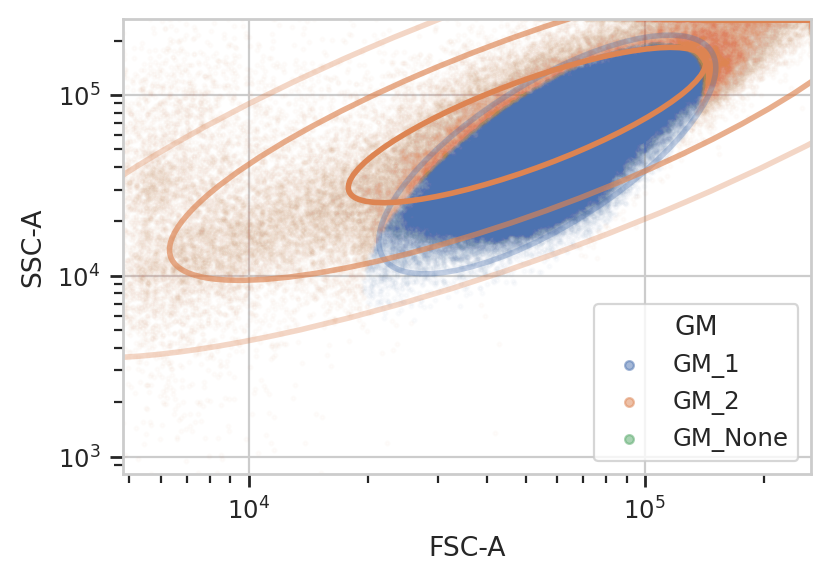

In [21]:
# Function to process each group
def process_groups(file_pairs, transformed_qdot_525_data_list, amplification_type):
    for files in file_pairs:
        # List to store transformed data for each group
        transformed_data_group = []

        for file in files:
            # Reading the FACS data for each file
            data = FlowCal.io.FCSData(file)

            # Extracting the 'Qdot 525-A' fluorescence data by column index
            qdot_525_data = data[:, 'Qdot 525-A']

            # Pad the data to ensure it can be reshaped into two repeats
            if len(qdot_525_data) < num_repeats * 5000:
                padded_size = num_repeats * 5000 - len(qdot_525_data)
                qdot_525_data = np.pad(qdot_525_data, (0, padded_size), 'constant')

            # Reshape 'Qdot 525-A' data to prepare for transformation
            qdot_525_data_reshaped = qdot_525_data.reshape(num_repeats, -1)

            # Calculate the mean between repeats for each data point
            mean_between_repeats = np.mean(qdot_525_data_reshaped, axis=0)

            # Transforming 'Qdot 525-A' data to RFI using FlowCal for each data point
            transformed_data = FlowCal.transform.to_rfi(
                mean_between_repeats.reshape(-1, 1), amplification_type=[amplification_type]
            )

            # Append the transformed data to the group list
            transformed_data_group.extend(transformed_data)

        # Append the transformed data for each group to the main list
        transformed_qdot_525_data_list.append(transformed_data_group)

# Function to process each group
def process_group_means(file_pairs, transformed_qdot_525_data_list, amplification_type):
    for files in file_pairs:
        # List to store transformed data for each group
        transformed_data_group = []

        for file in files:
            # Reading the FACS data for each file
            data = FlowCal.io.FCSData(file)

            # Extracting the 'Qdot 525-A' fluorescence data by column index
            qdot_525_data = data[:, 'Qdot 525-A']

            # Pad the data to ensure it can be reshaped into two repeats
            if len(data) < num_repeats * 5000:
                padded_size = num_repeats * 5000 - len(data)
                data = np.pad(data, (0, padded_size), 'constant')

            # Reshape 'Qdot 525-A' data to prepare for transformation
            data_reshaped = data.reshape(num_repeats, -1)

            # Calculate the mean between repeats for each data point
            mean_between_repeats = np.mean(data_reshaped, axis=0)

            # Transforming 'Qdot 525-A' data to RFI using FlowCal for each data point
            transformed_data = FlowCal.transform.to_rfi(
                mean_between_repeats.reshape(-1, 1), amplification_type=[amplification_type]
            )

            # Append the transformed data to the group list
            transformed_data_group.extend(transformed_data)

        # Append the transformed data for each group to the main list
        transformed_qdot_525_data_list.append(transformed_data_group)

        
def process_groups_mean_all_channels(file_pairs, transformed_data_list):
    for files in file_pairs:
        # Dictionary to store mean data for each channel in each group
        mean_data_group = {channel: [] for channel in files[0].channels}

        for file in files:
            # Reading the FACS data for each file
            data = FlowCal.io.FCSData(file)

            # Iterate through each channel
            for channel in data.channels:
                # Extract data for the current channel
                channel_data = data[:, channel]

                # Pad the data to ensure it can be reshaped into two repeats
                if len(channel_data) < num_repeats * 5000:
                    padded_size = num_repeats * 5000 - len(channel_data)
                    channel_data = np.pad(channel_data, (0, padded_size), 'constant')

                # Reshape data to prepare for calculating the mean between pairs
                channel_data_reshaped = channel_data.reshape(num_repeats, -1)

                # Calculate the mean between repeats for each data point
                mean_between_repeats = np.mean(channel_data_reshaped, axis=0)

                # Append the mean data to the corresponding channel list in the dictionary
                mean_data_group[channel].append(mean_between_repeats)

        # Append the mean data for each group to the main list
        transformed_data_list.append(mean_data_group)
        
wells = []

path='data/FACS_results/Experiment_1/'
for f in sorted(os.listdir(path)):
    if 'Specimen' in f:
        r = re.search("Specimen_001_(.*?)_(.*?)_(.*?)\.fcs", f)
        well = r.group(2)
        well_parsed = flow.Tube(file = os.path.join(path, f), conditions = {"ID" : str(well)})
        wells.append(well_parsed)
ex = flow.ImportOp(tubes = wells, conditions = {"ID" : "str"}).apply()

gm = flow.GaussianMixtureOp(name = "GM",channels = ['FSC-A', 'SSC-A'],
                            scale = {'FSC-A' : 'log','SSC-A' : 'log'},
                            num_components = 1,sigma = 2)
gm.estimate(ex)
ex_gm1 = gm.apply(ex)
# gm.default_view().plot(ex_gm1, alpha = 0.02)
data_after_gating = ex_gm1.data

gm = flow.GaussianMixtureOp(name = "GM",channels = ['FSC-A', 'SSC-A'],
                            scale = {'FSC-A' : 'log','SSC-A' : 'log'},
                            num_components = 2,sigma = 2)
gm.estimate(ex)
ex_gm1 = gm.apply(ex)
gm.default_view().plot(ex_gm1, alpha = 0.02)

filtered = ex_gm1.data.query("GM_2==True")
filtered = filtered.sort_values(by=['ID'])



/home/labs/barkailab/aileenc/miniconda3/envs/bio_viz_studio/lib/python3.11/site-packages/cytoflow/operations/base_op_views.py:373: CytoflowViewWarning: Setting 'huefacet' to 'GM'


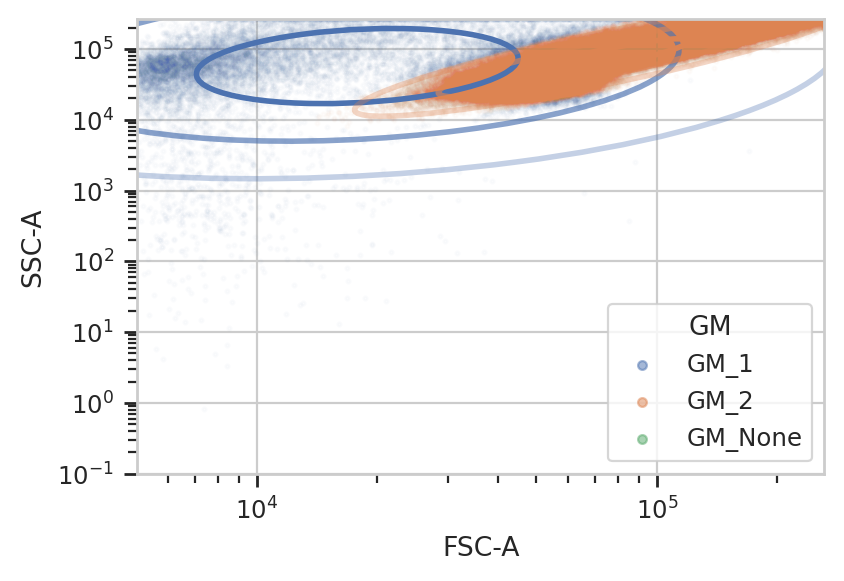

In [22]:
wells = []

path='data/FACS_results/Experiment_2/'
for f in sorted(os.listdir(path)):
    if 'Specimen' in f:
        r = re.search("Specimen_001_(.*?)_(.*?)_(.*?)\.fcs", f)
        well = r.group(2)
        well_parsed = flow.Tube(file = os.path.join(path, f), conditions = {"ID" : str(well)})
        wells.append(well_parsed)
ex = flow.ImportOp(tubes = wells, conditions = {"ID" : "str"}).apply()

gm = flow.GaussianMixtureOp(name = "GM",channels = ['FSC-A', 'SSC-A'],
                            scale = {'FSC-A' : 'log','SSC-A' : 'log'},
                            num_components = 1,sigma = 2)
gm.estimate(ex)
ex_gm1 = gm.apply(ex)
# gm.default_view().plot(ex_gm1, alpha = 0.02)
data_after_gating = ex_gm1.data
gm = flow.GaussianMixtureOp(name = "GM",channels = ['FSC-A', 'SSC-A'],
                            scale = {'FSC-A' : 'log','SSC-A' : 'log'},
                            num_components = 2,sigma = 2)
gm.estimate(ex)
ex_gm1 = gm.apply(ex)
gm.default_view().plot(ex_gm1, alpha = 0.02)

filtered2 = ex_gm1.data.query("GM_2==True")
filtered2 = filtered2.sort_values('ID')
filtered2['ID'].unique()

filtered2=filtered2.replace(['A11', 'A12', 'B01', 'B02', 'B03', 'B04', 'B07', 'B08', 'B09',
       'B10', 'B11', 'B12', 'C01', 'C02', 'C03', 'C04', 'C05', 'C06',
       'C11', 'C12', 'D05', 'D06', 'E07', 'E08', 'E09', 'E10', 'E11',
       'E12', 'F01', 'F02', 'F07', 'F08'],['D11', 'D12', 'E01', 'E02', 'E03', 'E04', 'E07', 'E08', 'E09',
       'E10', 'E11', 'E12', 'F01', 'F02', 'F03', 'F04', 'F05', 'F06',
       'F11', 'F12', 'G05', 'G06', 'G07', 'G08', 'G09', 'G10', 'G11',
       'G12', 'H01', 'H02', 'H07', 'H08'])

In [23]:
combined = pd.concat([filtered,filtered2],ignore_index=True)

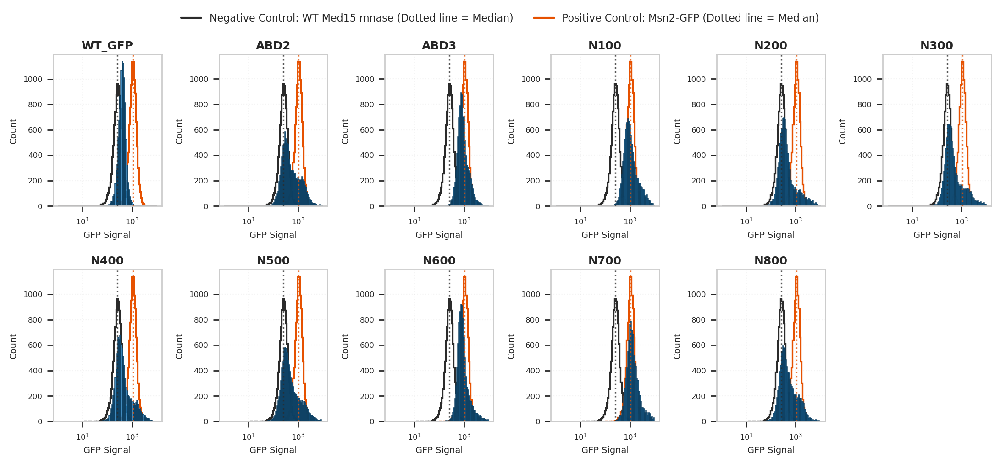

In [65]:
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# ==========================================
# 1. Strain List Definition (32 entries: 2 controls + 30 experimental)
# ==========================================
strains = [
    # --- Controls (Indices 0 & 1) ---
    "WT Med15 mnase",  # Negative Control
    "Msn2-GFP",  # Positive Control
    "WT_GFP",
    # --- Specific Functional Domains ---
    "ABD2",
    "ABD3",
    # --- N-terminal Truncations ---
    "N100",
    "N200",
    "N300",
    "N400",
    "N500",
    "N600",
    "N700",
    "N800"
]

# ==========================================
# 2. Extract Event Data by Well ID
# ==========================================
combined = combined.sort_values("ID")
unique_ids = combined["ID"].unique()

GFP_means = [
    combined.loc[combined["ID"] == well_id, "Qdot 525-A"].to_numpy()
    for well_id in unique_ids
]

# ==========================================
# 3. Average Duplicate Wells & Drop Extra Strains
# ==========================================
pair_means = []
for i in range(0, len(GFP_means) - 1, 2):
    w1, w2 = GFP_means[i], GFP_means[i + 1]
    min_len = min(len(w1), len(w2))
    pair_avg = (w1[:min_len] + w2[:min_len]) / 2.0
    pair_means.append(pair_avg)

# Truncate to match defined strain list (drops Strains 33 and 34)
valid_pair_means = pair_means[: len(strains)]

# ==========================================
# 4. Controls & Visual Setup
# ==========================================
neg_ctrl = valid_pair_means[0]
pos_ctrl = valid_pair_means[1]
median_neg = statistics.median(neg_ctrl)
median_pos = statistics.median(pos_ctrl)

bins = np.logspace(0, 4, 100)
n_experimental = len(valid_pair_means) - 2  # Exactly 30 experimental strains

# Unified visible color for experimental strains (placed in front of controls)
strain_color = "#1F77B4"  # Distinct professional blue
strain_edge = "#0B3C5D"

# ==========================================
# 5. Compact Grid Layout with Figure-Level Legend & PDF Export
# ==========================================
n_cols = 6  # 6 columns x 5 rows = 30 compact subplots
n_rows = math.ceil(n_experimental / n_cols)

# Extra height padding at the top for the figure-level control legend
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 2.2 * n_rows + 0.6))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for plot_idx, pair_idx in enumerate(range(2, len(valid_pair_means))):
    ax = axes_flat[plot_idx]

    # 1. Plot background controls first (behind experimental data)
    ax.hist(
        neg_ctrl,
        bins=bins,
        histtype="step",
        color="#2B2B2B",
        linewidth=1.2,
        zorder=1,
    )
    ax.hist(
        pos_ctrl,
        bins=bins,
        histtype="step",
        color="#E65100",
        linewidth=1.2,
        zorder=1,
    )

    # 2. Plot experimental strain in front (higher zorder) with solid fill
    strain_label = strains[pair_idx]
    ax.hist(
        valid_pair_means[pair_idx],
        bins=bins,
        alpha=0.85,
        color=strain_color,
        edgecolor=strain_edge,
        linewidth=0.6,
        zorder=2,
    )

    # Median reference guides
    ax.axvline(
        x=median_neg, linestyle=":", color="#2B2B2B", alpha=0.8, linewidth=1.2, zorder=3
    )
    ax.axvline(
        x=median_pos, linestyle=":", color="#E65100", alpha=0.8, linewidth=1.2, zorder=3
    )

    # Axis formatting tuned for smaller panels
    ax.set_title(strain_label, fontsize=9, fontweight="bold", pad=4)
    ax.set_xlabel("GFP Signal", fontsize=7)
    ax.set_ylabel("Count", fontsize=7)
    ax.tick_params(axis='both', which='major', labelsize=6)
    ax.set_xscale("log")
    ax.grid(True, which="both", ls=":", alpha=0.2)

# Remove unused slots if grid is not perfectly filled
for unused_idx in range(n_experimental, len(axes_flat)):
    fig.delaxes(axes_flat[unused_idx])

# ==========================================
# 6. Figure-Level Legend Above Matrix
# ==========================================
legend_elements = [
    Line2D([0], [0], color="#2B2B2B", lw=1.5, linestyle="-", label=f"Negative Control: {strains[0]} (Dotted line = Median)"),
    Line2D([0], [0], color="#E65100", lw=1.5, linestyle="-", label=f"Positive Control: {strains[1]} (Dotted line = Median)"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    fontsize=8,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

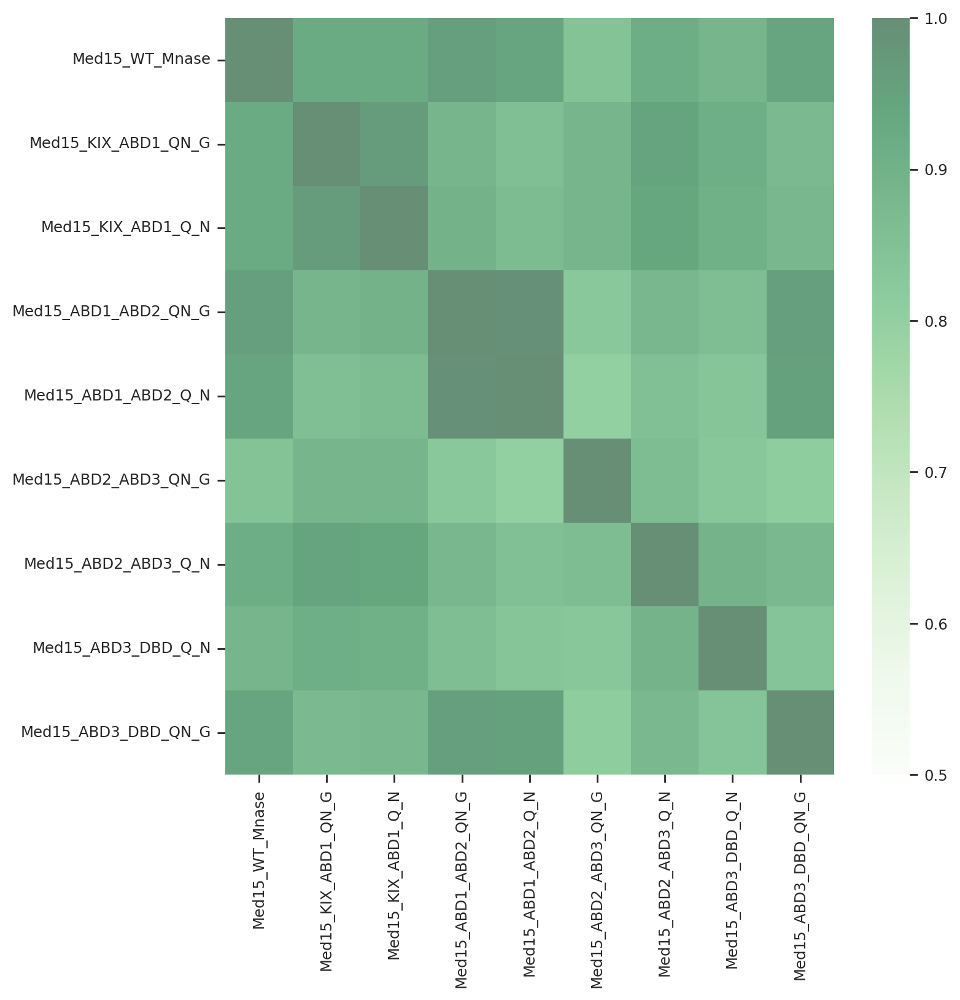

In [74]:
corr_matrix = WT_system_data[['Med15_WT_Mnase','Med15_KIX_ABD1_QN_G', 'Med15_KIX_ABD1_Q_N','Med15_ABD1_ABD2_QN_G', 'Med15_ABD1_ABD2_Q_N','Med15_ABD2_ABD3_QN_G',
       'Med15_ABD2_ABD3_Q_N','Med15_ABD3_DBD_Q_N',
       'Med15_ABD3_DBD_QN_G']].corr()

filtered_corr_matrix = corr_matrix

plt.subplots(figsize=(8, 8))
heatmap = sns.heatmap(
    filtered_corr_matrix, 
    annot=False, 
    fmt=".2g", 
    cmap=pastel_cmap, 
    vmax=1, 
    vmin=0.5, 
)


plt.show()

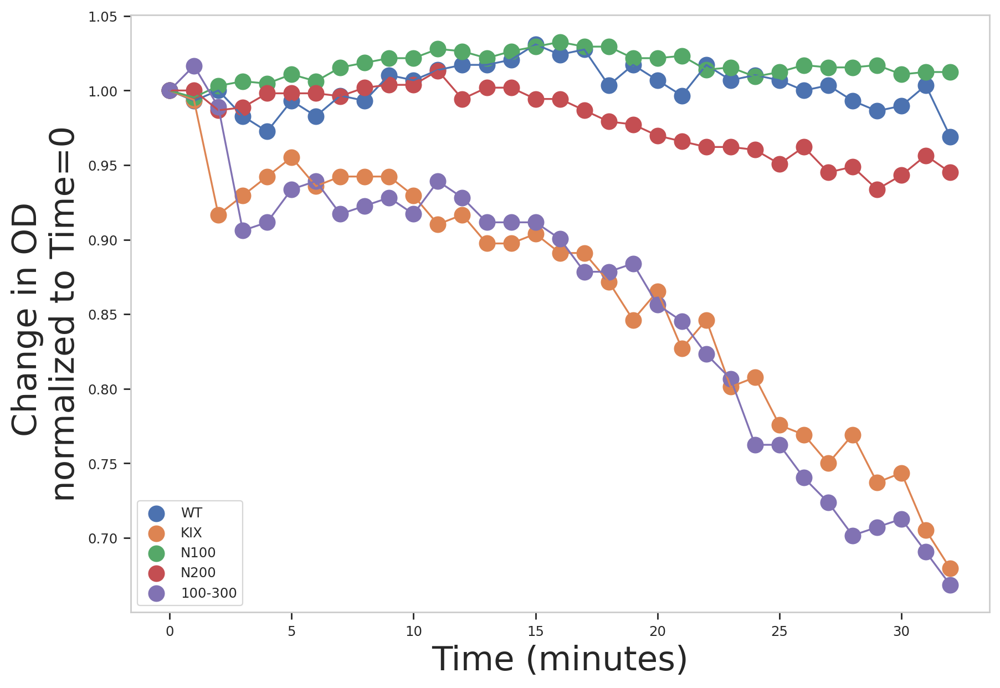

In [53]:
SFig_1A_Floc = Flocculation.T.filter(regex='WT|N100|N200|100-300|KIX')
plt.subplots(figsize=(10,7))
for idx, column in enumerate(SFig_1A_Floc):
    x_values = range(0,33)
    y_values = SFig_1A_Floc[column]

    plt.scatter(x_values, y_values,s=100, label = column)
    plt.plot(x_values, y_values)

plt.xlabel('Time (minutes)',fontsize=22)
plt.ylabel('Change in OD \nnormalized to Time=0',fontsize=22)
plt.legend()
plt.grid(False)
plt.show()

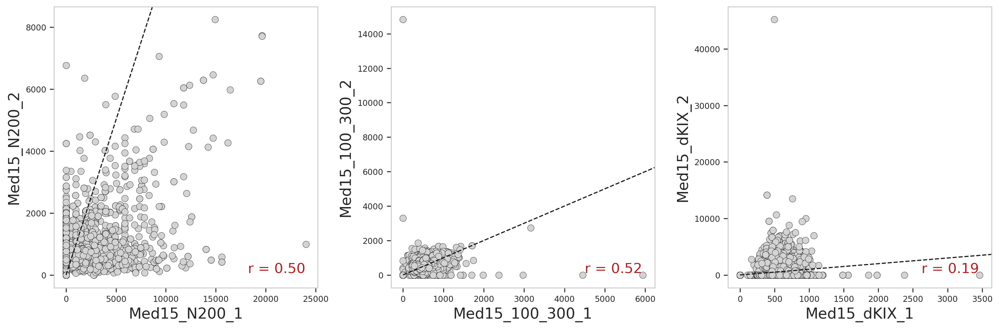

In [57]:
SFig_2A = Repeats[['Med15_N200_1', 'Med15_N200_2','Med15_100_300_1', 'Med15_100_300_2','Med15_dKIX_1', 'Med15_dKIX_2']]
fig, axes = plt.subplots(1, 3, figsize=(15, 5), tight_layout=True)

scatter_pairs = [
    ('Med15_N200_1', 'Med15_N200_2'),
    ( 'Med15_100_300_1', 'Med15_100_300_2'),
    ('Med15_dKIX_1','Med15_dKIX_2')
]


for i, (x_col, y_col) in enumerate(scatter_pairs):
    ax = axes[i]  
    x_data = SFig_2A[x_col]
    y_data = SFig_2A[y_col]
    correlation = np.corrcoef(x_data, y_data)[0, 1]
    ax.scatter(x_data, y_data, c='lightgrey', s=50, ec='k',lw=0.3)


    x_lim = ax.get_xlim()
    y_lim = ax.get_ylim()
    xy_min, xy_max = min(x_data.min(), y_data.min()), max(x_data.max(), y_data.max())
    ax.plot([xy_min, xy_max], [xy_min, xy_max], linestyle="--", color="k")


    ax.set_xlim(x_lim)
    ax.set_ylim(y_lim)

    # Labels
    ax.set_xlabel(x_col, fontsize=16)
    ax.set_ylabel(y_col, fontsize=16)
    
    ax.text(
        x_lim[1] * 0.95,
        y_lim[0] * 0.09,   
        f"r = {correlation:.2f}",
        fontsize=15,
        color="firebrick",
        ha="right",
        va="bottom",
    )
    ax.grid(False)
plt.show()

# SupFigure 2

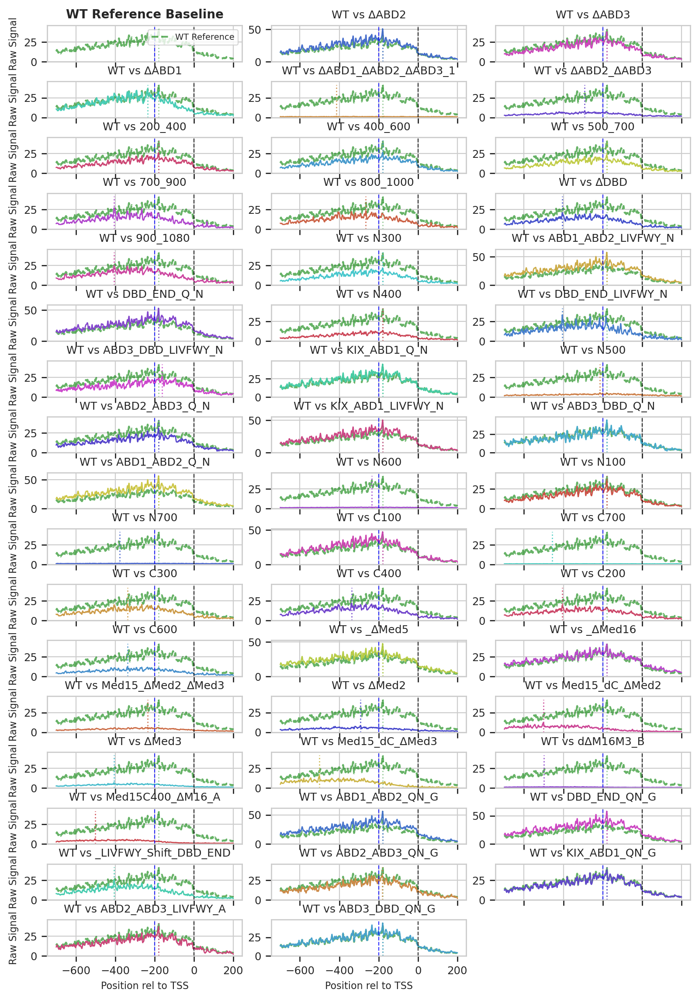

In [66]:
def plot_A4_master_grid():
    """
    Generates an A4-sized PDF containing a grid of all metaprofiles.
    Uses subplots_adjust optimized to provide extra vertical space 
    for clear titles and axis labels.
    """
    window_start = -700
    window_end = 200
    x_axis = np.arange(window_start, window_end + 1)
    
    smoothing_sigma = 1.5
    
    filtered_cols = promoter_binding_signals.filter(regex='Med15M|Med15_|Med15C').columns.tolist()
    
    # Exclude any column containing '_N200'
    filtered_cols = [c for c in filtered_cols if '_N200' not in str(c)]
    
    wt_col = next((c for c in filtered_cols if 'WT_Mnase' in str(c)), None)
    if wt_col in filtered_cols:
        filtered_cols.remove(wt_col)
    
    if not wt_col:
        print("❌ Error: Could not find the WT column in the dataframe!")
        return

    rem = filtered_cols.copy()
    mutants_sorted = []
    
    order_keywords = [
        'dABD', '200_400', '400_600', '500_700', '700_900', '800_1000', 'dDBD', 
        '900_1080', '_N', '_C', 'dMed5', 'dMed16', 'dMed2_dMed3', 
        'dMed2', 'dMed3', 'Med15Mnase_dC', 'dM16'
    ]
    
    for kw in order_keywords:
        matches = [m for m in rem if kw in str(m)]
        mutants_sorted.extend(matches)
        rem = [m for m in rem if m not in matches]
        
    mutants = mutants_sorted + rem

    wt_path = promoter_binding_signals[wt_col].loc["path"]
    wt_df = pd.read_pickle(wt_path).fillna(0)

    if isinstance(wt_df.index, pd.RangeIndex) or wt_df.index.dtype == 'int64':
        if len(wt_df) == len(reference_index):
            wt_df.index = reference_index
    if wt_df.columns.min() == 0 and wt_df.columns.max() == wt_df.shape[1] - 1:
        start_col = -(wt_df.shape[1] // 2)
        wt_df.columns = range(start_col, start_col + wt_df.shape[1])

    valid_targets = wt_df.index.intersection(top_200_med15_targets)
    raw_wt_vals = wt_df.loc[valid_targets, window_start:window_end].mean(axis=0).values
    wt_vals = gaussian_filter1d(raw_wt_vals, sigma=smoothing_sigma)

    n_plots = len(mutants) + 1  
    cols = 3  
    rows = math.ceil(n_plots / cols)
    
    # Strictly enforce A4 sizing
    fig, axes = plt.subplots(rows, cols, figsize=(8.27, 11.69), sharex=True)
    axes = axes.flatten()
    
    distinct_colors = []
    golden_ratio_conjugate = 0.618033988749895
    h = 0.0

    while len(distinct_colors) < len(mutants) + 5:
        h = (h + golden_ratio_conjugate) % 1.0
        if 0.20 < h < 0.45:
            continue
        rgb = colorsys.hsv_to_rgb(h, 0.65, 0.80)
        distinct_colors.append(rgb)

    ax_wt = axes[0]
    ax_wt.plot(x_axis, wt_vals, color='green', linestyle='--', linewidth=1.5, alpha=0.6, label='WT Reference', rasterized=True)
    
    peak_x_wt = x_axis[np.argmax(wt_vals)]
    ymax_wt = max(wt_vals)
    
    ax_wt.vlines(x=peak_x_wt, ymin=0, ymax=ymax_wt, color='green', linestyle=':', linewidth=1.0, alpha=0.4, rasterized=True)
    ax_wt.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.8)
    ax_wt.axvline(-200, color='blue', linestyle='--', linewidth=0.8, alpha=0.8)
    
    ax_wt.set_title("WT Reference Baseline", fontsize=10, fontweight='bold', pad=6)
    ax_wt.legend(loc='upper right', fontsize=7)
    ax_wt.set_ylim(0, ymax_wt * 1.1)

    for i, mut_col in enumerate(mutants):
        ax = axes[i + 1]
        mut_color = distinct_colors[i]
        path = promoter_binding_signals[mut_col].loc["path"]
        mut_df = pd.read_pickle(path).fillna(0)

        if isinstance(mut_df.index, pd.RangeIndex) or mut_df.index.dtype == 'int64':
            if len(mut_df) == len(wt_df):
                mut_df.index = wt_df.index
            else:
                print(f"Warning: Cannot fix index for {mut_col}. Length mismatch.")
        
        if mut_df.columns.min() == 0 and mut_df.columns.max() == mut_df.shape[1] - 1:
            start_col = -(mut_df.shape[1] // 2)
            mut_df.columns = range(start_col, start_col + mut_df.shape[1])

        valid_mut_targets = mut_df.index.intersection(top_200_med15_targets)
        if len(valid_mut_targets) == 0:
            ax.text(0.5, 0.5, f"No genes found\n{mut_col}", ha='center', va='center', transform=ax.transAxes)
            continue
            
        raw_mut_vals = mut_df.loc[valid_mut_targets, window_start:window_end].mean(axis=0).values
        mut_vals = gaussian_filter1d(raw_mut_vals, sigma=smoothing_sigma)

        ax.plot(x_axis, wt_vals, color='green', linestyle='--', linewidth=1.5, alpha=0.6, rasterized=True)
        ax.plot(x_axis, mut_vals, color=mut_color, linewidth=1.0, label=f"{mut_col}", rasterized=True)
        
        peak_x_curr = x_axis[np.argmax(mut_vals)]
        local_ymax = max(ymax_wt, max(mut_vals))
        
        ax.vlines(x=peak_x_wt, ymin=0, ymax=local_ymax, color='green', linestyle=':', linewidth=1.0, alpha=0.4, rasterized=True)
        ax.vlines(x=peak_x_curr, ymin=0, ymax=local_ymax, color=mut_color, linestyle=':', linewidth=1.0, alpha=0.9, rasterized=True)

        ax.axvline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.8)
        ax.axvline(-200, color='blue', linestyle='--', linewidth=0.8, alpha=0.8)
        
        ax.set_ylim(0, local_ymax * 1.1)
        
        clean_title = str(mut_col).replace('WT_', '').replace('Med15_', '').replace('Mnase','')
        
        if str(mut_col) == 'Med15_N':
            clean_title = 'ΔN'
            
        delta_map = {
            'dABD': 'ΔABD',
            'dDBD': 'ΔDBD',
            'dMed': 'ΔMed',
            'dM16': 'ΔM16',
            '_C': 'ΔC',
            'dd': 'ΔΔ'
        }
        for old, new in delta_map.items():
            clean_title = clean_title.replace(old, new)
        
        # Increased pad slightly to lift title away from the data
        ax.set_title(f"WT vs {clean_title}", fontsize=9, pad=6)

    for j in range(n_plots, len(axes)):
        fig.delaxes(axes[j])
        
    for i in range(rows):
        if i * cols < len(axes):
            axes[i * cols].set_ylabel("Raw Signal", fontsize=8, labelpad=4)
            
    for j in range(cols):
        bottom_idx = (rows - 1) * cols + j
        if bottom_idx < len(axes):
            axes[bottom_idx].set_xlabel("Position rel to TSS", fontsize=8, labelpad=4)
        elif bottom_idx - cols < len(axes): 
            axes[bottom_idx - cols].set_xlabel("Position rel to TSS", fontsize=8, labelpad=4)

    plt.subplots_adjust(left=0.08, right=0.97, top=0.96, bottom=0.05, hspace=0.55, wspace=0.15)
    plt.grid(False)
    plt.show()
# Run the function
plot_A4_master_grid()

# SupFigure3

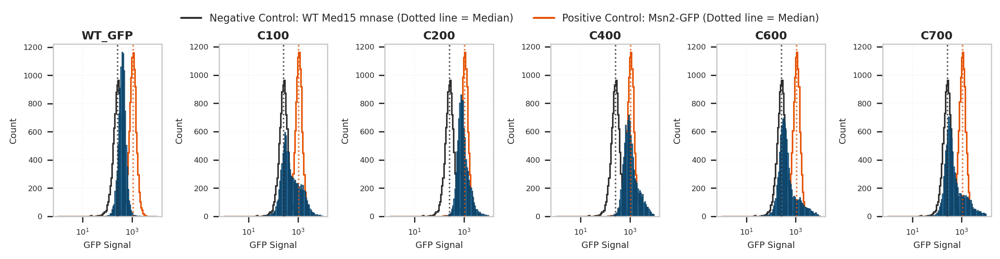

In [61]:
import math
import statistics
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

# ==========================================
# 1. Strain List Definition (32 entries: 2 controls + 30 experimental)
# ==========================================
strains = [
    # --- Controls (Indices 0 & 1) ---
    "WT Med15 mnase",  # Negative Control
    "Msn2-GFP",  # Positive Control
    "WT_GFP",
    "C100",
    "C200",
    "C400",
    "C600",
    "C700"
]

# ==========================================
# 2. Extract Event Data by Well ID
# ==========================================
combined = combined.sort_values("ID")
unique_ids = combined["ID"].unique()

GFP_means = [
    combined.loc[combined["ID"] == well_id, "Qdot 525-A"].to_numpy()
    for well_id in unique_ids
]

# ==========================================
# 3. Average Duplicate Wells & Drop Extra Strains
# ==========================================
pair_means = []
for i in range(0, len(GFP_means) - 1, 2):
    w1, w2 = GFP_means[i], GFP_means[i + 1]
    min_len = min(len(w1), len(w2))
    pair_avg = (w1[:min_len] + w2[:min_len]) / 2.0
    pair_means.append(pair_avg)

# Truncate to match defined strain list (drops Strains 33 and 34)
valid_pair_means = pair_means[: len(strains)]

# ==========================================
# 4. Controls & Visual Setup
# ==========================================
neg_ctrl = valid_pair_means[0]
pos_ctrl = valid_pair_means[1]
median_neg = statistics.median(neg_ctrl)
median_pos = statistics.median(pos_ctrl)

bins = np.logspace(0, 4, 100)
n_experimental = len(valid_pair_means) - 2  # Exactly 30 experimental strains

# Unified visible color for experimental strains (placed in front of controls)
strain_color = "#1F77B4"  # Distinct professional blue
strain_edge = "#0B3C5D"

# ==========================================
# 5. Compact Grid Layout with Figure-Level Legend & PDF Export
# ==========================================
n_cols = 6  # 6 columns x 5 rows = 30 compact subplots
n_rows = math.ceil(n_experimental / n_cols)

# Extra height padding at the top for the figure-level control legend
fig, axes = plt.subplots(n_rows, n_cols, figsize=(11, 2.2 * n_rows + 0.6))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]

for plot_idx, pair_idx in enumerate(range(2, len(valid_pair_means))):
    ax = axes_flat[plot_idx]

    # 1. Plot background controls first (behind experimental data)
    ax.hist(
        neg_ctrl,
        bins=bins,
        histtype="step",
        color="#2B2B2B",
        linewidth=1.2,
        zorder=1,
    )
    ax.hist(
        pos_ctrl,
        bins=bins,
        histtype="step",
        color="#E65100",
        linewidth=1.2,
        zorder=1,
    )

    # 2. Plot experimental strain in front (higher zorder) with solid fill
    strain_label = strains[pair_idx]
    ax.hist(
        valid_pair_means[pair_idx],
        bins=bins,
        alpha=0.85,
        color=strain_color,
        edgecolor=strain_edge,
        linewidth=0.6,
        zorder=2,
    )

    # Median reference guides
    ax.axvline(
        x=median_neg, linestyle=":", color="#2B2B2B", alpha=0.8, linewidth=1.2, zorder=3
    )
    ax.axvline(
        x=median_pos, linestyle=":", color="#E65100", alpha=0.8, linewidth=1.2, zorder=3
    )

    # Axis formatting tuned for smaller panels
    ax.set_title(strain_label, fontsize=9, fontweight="bold", pad=4)
    ax.set_xlabel("GFP Signal", fontsize=7)
    ax.set_ylabel("Count", fontsize=7)
    ax.tick_params(axis='both', which='major', labelsize=6)
    ax.set_xscale("log")
    ax.grid(True, which="both", ls=":", alpha=0.2)

# Remove unused slots if grid is not perfectly filled
for unused_idx in range(n_experimental, len(axes_flat)):
    fig.delaxes(axes_flat[unused_idx])

# ==========================================
# 6. Figure-Level Legend Above Matrix
# ==========================================
legend_elements = [
    Line2D([0], [0], color="#2B2B2B", lw=1.5, linestyle="-", label=f"Negative Control: {strains[0]} (Dotted line = Median)"),
    Line2D([0], [0], color="#E65100", lw=1.5, linestyle="-", label=f"Positive Control: {strains[1]} (Dotted line = Median)"),
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    fontsize=8,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

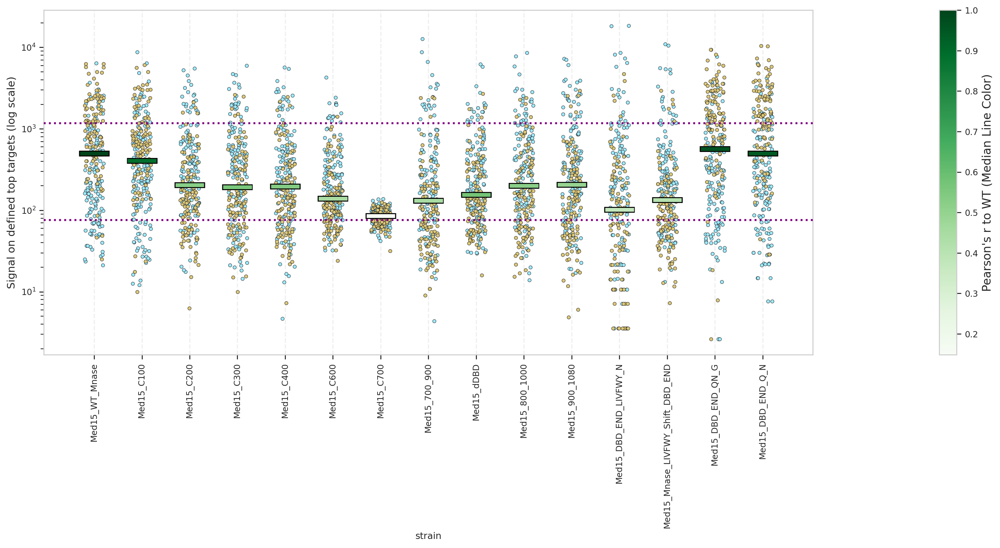

In [93]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg50_to_50.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]

requested_strains = [
    'Med15_WT_Mnase', 'Med15_C100', 'Med15_C200', 'Med15_C300',
    'Med15_C400', 'Med15_C600', 'Med15_C700', 'Med15_700_900', 'Med15_dDBD',
    'Med15_800_1000', 'Med15_900_1080', 'Med15_DBD_END_LIVFWY_N',
    'Med15_Mnase_LIVFWY_Shift_DBD_END', 'Med15_DBD_END_QN_G', 'Med15_DBD_END_Q_N'
]

# Ensure strains exist in dataframe
available_strains = [s for s in requested_strains if s in WT_system_data.columns]
missing_strains = set(requested_strains) - set(available_strains)
if missing_strains:
    print(f"Warning: The following strains were not found in WT_system_data: {missing_strains}")

Figure_2C = WT_system_data[available_strains]

# Filter down to the combined targets
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_2C.index]
df_top = Figure_2C.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to WT
median_s = df_long.groupby('strain')['signal'].median()
corr_with_WT = Figure_2C.corr()[wt_col]

median_df = pd.DataFrame({
    'strain': Figure_2C.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_2C.columns],
    'corr_to_WT': [corr_with_WT.get(col, np.nan) for col in Figure_2C.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_WT'].dropna().min(),
    vmax=median_df['corr_to_WT'].dropna().max()
)

# =====================================================================
# 4. PLOTTING
# =====================================================================
fig, ax1 = plt.subplots(figsize=(16, 8))

cmap_choice = cm.Greens

# Gained in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_2C.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.2,
    size=3.5,
    zorder=2,
    ax=ax1,
    rasterized=True
)


# Lost in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_2C.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.2,
    size=3.5,
    zorder=2,
    ax=ax1,
    rasterized=True
)


# [UPDATED] Median overlays (short horizontal lines instead of hexagons)
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
        
    # Draw a slightly thicker black line behind it for a crisp border/outline effect
    ax1.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    # Draw the colored median line on top
    ax1.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_WT'])),
        linewidth=4,
        zorder=10
    )




# Vertical guides
for strain in Figure_2C.columns:
    ax1.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines (evaluated on Med15 WT top targets baseline)
if 'med15_top_targets' in globals():
    valid_targets = WT_system_data.index.intersection(med15_top_targets)
else:
    valid_targets = z_wt.sort_values(ascending=False).head(200).index

ref_strains = [
    ('Med15_WT_Mnase', 'purple', ':'),
    ('Med15_dABD1_dABD2_dABD3_1', 'purple', ':')
]

for ref_s, c, ls in ref_strains:
    if ref_s in WT_system_data.columns:
        val_ref = WT_system_data.loc[valid_targets, ref_s].median()
        if not pd.isna(val_ref):
            ax1.axhline(val_ref, color=c, linestyle=ls, linewidth=2.0, zorder=3)

# Colorbar (attached to the main axis, with extra padding for ax2)
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=ax1, pad=0.12)
cbar.set_label("Pearson's r to WT (Median Line Color)", fontsize=12)

# Axis formatting
ax1.set_xticks(range(len(Figure_2C.columns)))
ax1.set_xticklabels(Figure_2C.columns, rotation=90)
ax1.set_yscale('log')

ax1.set_ylabel('Signal on defined top targets (log scale)', fontsize=11)
plt.tight_layout()
ax1.grid(False)



plt.show()

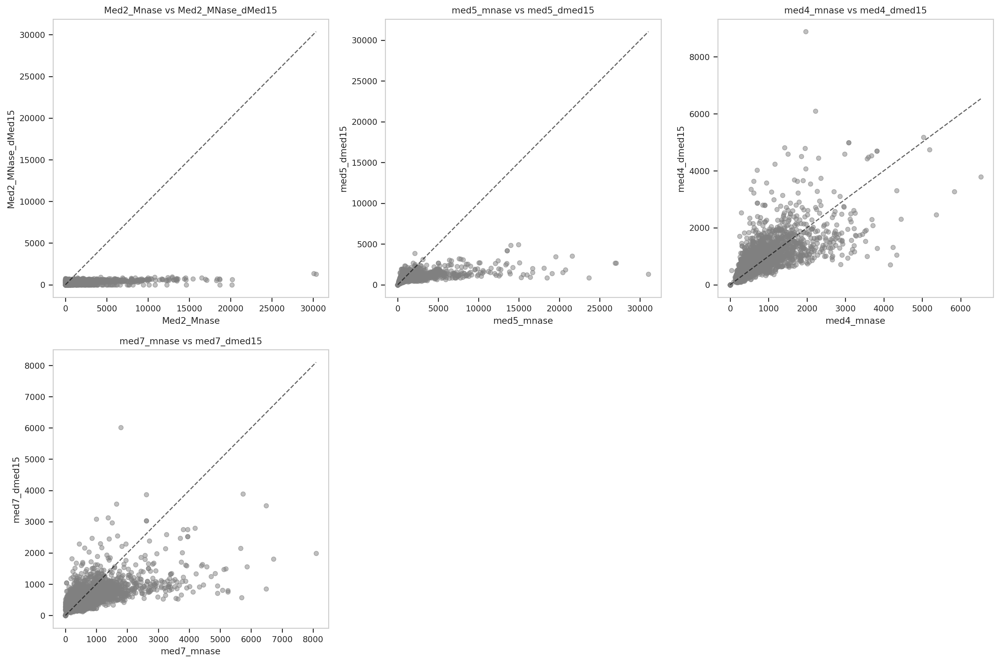

In [78]:
sumprom_path = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and index
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]
df = WT_system_data[['Med2_Mnase','Med2_MNase_dMed15','med5_mnase','med5_dmed15','med4_mnase','med4_dmed15','med7_mnase','med7_dmed15']]

pairs = []

for col in df.columns:
    if col.endswith('_Mnase') or col.endswith('_mnase') or '_WT' in col:
        base = col.lower().split('_')[0]
     
        matches = [c for c in df.columns if c.lower().startswith(base) and 'dmed15' in c.lower()]
        if matches:
            pairs.append( (col, matches[0]) )


num_plots = len(pairs)
ncols = 3
nrows = (num_plots + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), squeeze=False)

for ax, (wt_col, dmed15_col) in zip(axes.flatten(), pairs):
    ax.scatter(df[wt_col], df[dmed15_col], alpha=0.5, color='grey', edgecolor='grey', rasterized=True)
    ax.set_xlabel(wt_col)
    ax.set_ylabel(dmed15_col)
    ax.set_title(f'{wt_col} vs {dmed15_col}')
    ax.plot([df[wt_col].min(), df[wt_col].max()], [df[wt_col].min(), df[wt_col].max()], '--', color='black', alpha=0.6)
    ax.grid(False)

# Hide any empty subplots
for ax in axes.flatten()[len(pairs):]:
    ax.set_visible(False)


plt.tight_layout()
plt.show()


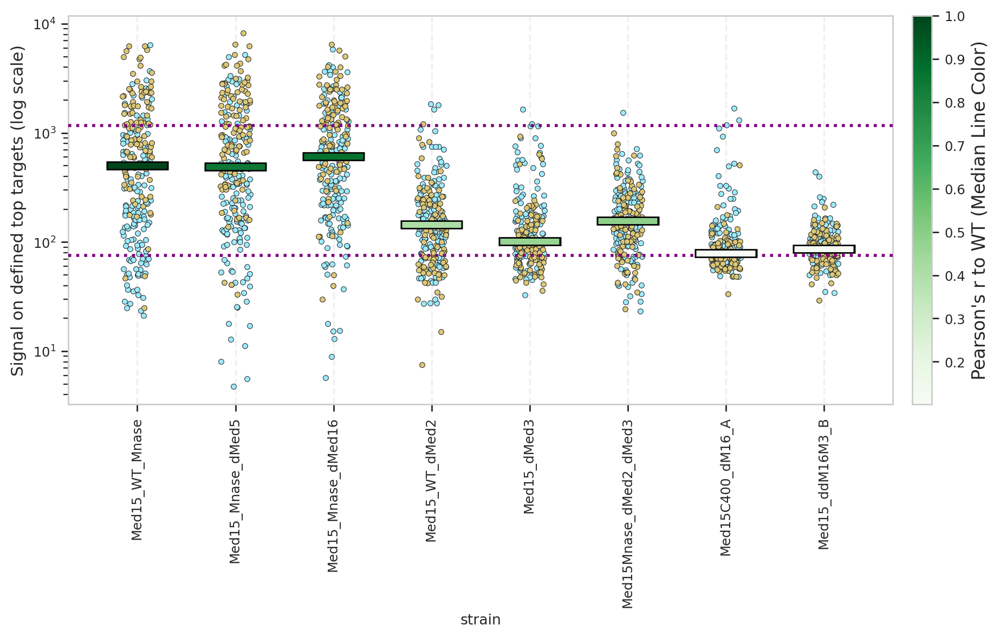

In [85]:
import os
import glob
import re
import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import seaborn as sns

# =====================================================================
# 1. LOAD & CLEAN DATA
# =====================================================================
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg50_to_50.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]

requested_strains = [
    'Med15_WT_Mnase', 
    'Med15_Mnase_dMed5', 
    'Med15_Mnase_dMed16',
    'Med15_WT_dMed2', 
    'Med15_dMed3', 
    'Med15Mnase_dMed2_dMed3', 
    'Med15C400_dM16_A', 
    'Med15_ddM16M3_B'
]

# Robust column matching to account for minor naming variances
resolved_strains = []
for strain in requested_strains:
    if strain in WT_system_data.columns:
        resolved_strains.append(strain)
    else:
        # Fallback match by stripping underscores or case-insensitivity
        clean_target = strain.lower().replace("_", "")
        matches = [c for c in WT_system_data.columns if c.lower().replace("_", "") == clean_target]
        if matches:
            resolved_strains.append(matches[0])
        else:
            print(f"⚠️ Warning: '{strain}' not found in dataset columns!")

Figure_3C = WT_system_data[resolved_strains].copy()

# =====================================================================
# 2. FILTER TARGETS (FIXED TYPOS)
# =====================================================================
# Replaced dC with dc to match the stripplot variables perfectly
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_3C.index]
df_top = Figure_3C.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to WT
median_s = df_long.groupby('strain')['signal'].median()
corr_with_WT = Figure_3C.corr()[wt_col]

median_df = pd.DataFrame({
    'strain': Figure_3C.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_3C.columns],
    'corr_to_WT': [corr_with_WT.get(col, np.nan) for col in Figure_3C.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_WT'].dropna().min(),
    vmax=median_df['corr_to_WT'].dropna().max()
)

# =====================================================================
# 3. PLOTTING
# =====================================================================
plt.figure(figsize=(10, 6))
cmap_choice = cm.Greens

# Gained in dc points
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3C.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)

# Lost in dc points
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3C.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)

# Median overlays
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
    
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_WT'])),
        linewidth=4,
        zorder=10
    )

# Vertical guides
for strain in Figure_3C.columns:
    plt.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines
if 'top_200_med15_targets' in globals():
    valid_targets = WT_system_data.index.intersection(top_200_med15_targets)
elif 'med15_top_targets' in globals():
    valid_targets = WT_system_data.index.intersection(med15_top_targets)
else:
    # Fallback if neither top target list is explicitly loaded
    valid_targets = WT_system_data[wt_col].sort_values(ascending=False).head(200).index

ref_strains = [
    ('Med15_WT_Mnase', 'purple', ':'),
    ('Med15_dABD1_dABD2_dABD3_1', 'purple', ':')
]

for ref_s, c, ls in ref_strains:
    if ref_s in WT_system_data.columns:
        val_ref = WT_system_data.loc[valid_targets, ref_s].median()
        if not pd.isna(val_ref):
            plt.axhline(val_ref, color=c, linestyle=ls, linewidth=2.0, zorder=3)

# Colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label("Pearson's r to WT (Median Line Color)", fontsize=12)

# Axis formatting
plt.xticks(rotation=90)
plt.yscale('log')
plt.ylabel('Signal on defined top targets (log scale)', fontsize=11)
plt.tight_layout()
plt.grid(False)
plt.show()

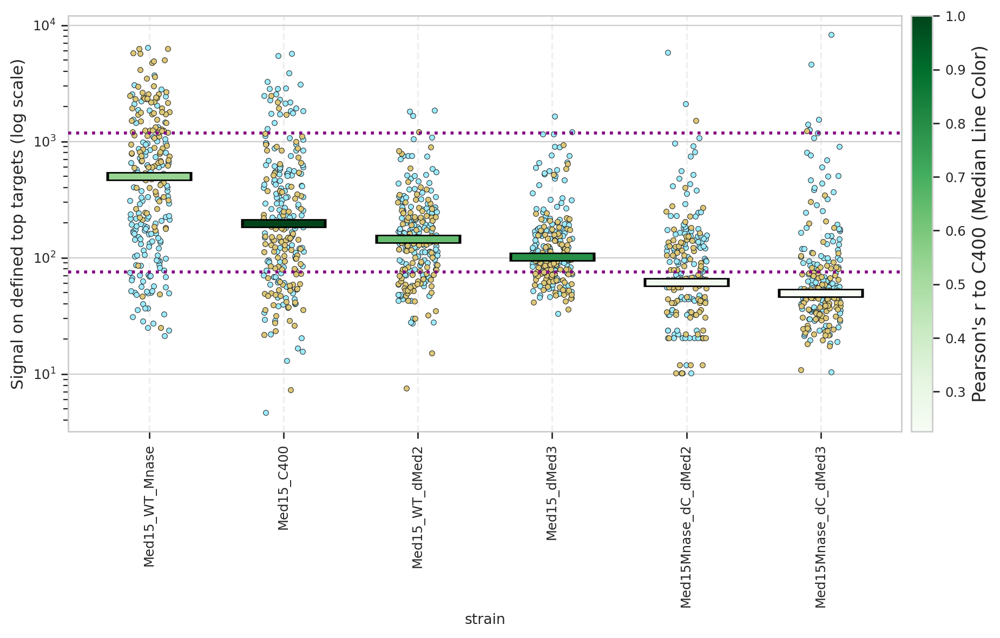

In [94]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg50_to_50.pkl.gz'

matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean columns and deduplicate
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

wt_col = [c for c in WT_system_data.columns if 'med15' in c.lower() and 'wt' in c.lower()][0]
c400_col = [c for c in WT_system_data.columns if 'c400' in c.lower()][0]


# =====================================================================
# 3. CONSTRUCT FIGURE_3D WITH REQUESTED STRAINS
# =====================================================================
requested_strains = [
    'Med15_WT_Mnase', 
    'Med15_C400', 
    'Med15_WT_dMed2', 
    'Med15_dMed3', 
    'Med15Mnase_dC_dMed2', 
    'Med15Mnase_dC_dMed3'
]

# Robust column matching to handle potential naming variances
resolved_strains = []
for strain in requested_strains:
    if strain in WT_system_data.columns:
        resolved_strains.append(strain)
    else:
        clean_target = strain.lower().replace("_", "")
        matches = [c for c in WT_system_data.columns if c.lower().replace("_", "") == clean_target]
        if matches:
            resolved_strains.append(matches[0])
        else:
            print(f"⚠️ Warning: '{strain}' not found in dataset columns!")

Figure_3D = WT_system_data[resolved_strains].copy()

# Filter down to the combined targets
combined_targets = [g for g in (lost_in_dc + gained_in_dc) if g in Figure_3D.index]
df_top = Figure_3D.loc[combined_targets].copy()
df_top['gene'] = df_top.index

df_long = df_top.melt(
    id_vars='gene',
    var_name='strain',
    value_name='signal'
).dropna()

# Calculate Medians and Correlations to Med15_C400
median_s = df_long.groupby('strain')['signal'].median()
ref_corr_col = c400_col if c400_col in Figure_3D.columns else 'Med15_C400'
corr_with_c400 = Figure_3D.corr()[ref_corr_col]

median_df = pd.DataFrame({
    'strain': Figure_3D.columns,
    'median_signal': [median_s.get(col, np.nan) for col in Figure_3D.columns],
    'corr_to_C400': [corr_with_c400.get(col, np.nan) for col in Figure_3D.columns]
})

norm = Normalize(
    vmin=median_df['corr_to_C400'].dropna().min(),
    vmax=median_df['corr_to_C400'].dropna().max()
)

# =====================================================================
# 4. PLOTTING
# =====================================================================
plt.figure(figsize=(10, 6))
cmap_choice = cm.Greens
# Gained in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(gained_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3D.columns,
    color='#9CEBFF',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)

# Lost in dC points (subtle jitter, edgecolors, backgrounded)
sns.stripplot(
    data=df_long[df_long['gene'].isin(lost_in_dc)],
    x='strain',
    y='signal',
    order=Figure_3D.columns,
    color='#DDC878',
    edgecolor='k',
    linewidth=0.35,
    alpha=1,
    jitter=0.15,
    size=3.5,
    zorder=2,
    rasterized=True
)


# Median overlays (short horizontal lines instead of scatter points)
for i, row in median_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
    
    # Draw a slightly thicker black line behind it for a crisp border/outline effect
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.32,
        xmax=i + 0.32,
        color='black',
        linewidth=6,
        zorder=9
    )
    
    # Draw the colored median line on top
    plt.hlines(
        y=row['median_signal'],
        xmin=i - 0.3,
        xmax=i + 0.3,
        color=cmap_choice(norm(row['corr_to_C400'])),
        linewidth=4,
        zorder=10
    )

# Vertical guides
for strain in Figure_3D.columns:
    plt.axvline(x=strain, color='lightgrey', linestyle='--', alpha=0.35, zorder=1)

# Horizontal reference lines (evaluated on Med15 WT top targets baseline)
if 'med15_top_targets' in globals():
    valid_targets = WT_system_data.index.intersection(med15_top_targets)
else:
    valid_targets = z_wt.sort_values(ascending=False).head(200).index

baseline_strains = {
    'Med15_WT_Mnase': ':',
    'Med15_dABD1_dABD2_dABD3_1': ':'
}

for target_strain, line_style in baseline_strains.items():
    if target_strain in WT_system_data.columns:
        avg_signal = WT_system_data.loc[valid_targets, target_strain].median()
        if pd.notna(avg_signal):
            plt.axhline(
                avg_signal, 
                color='purple', 
                linestyle=line_style, 
                linewidth=2.0, 
                zorder=3
            )

# Colorbar
sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.01)
cbar.set_label("Pearson's r to C400 (Median Line Color)", fontsize=12)

# Axis formatting
plt.xticks(rotation=90)
plt.yscale('log')
# plt.ylim(80, 10000)
plt.ylabel('Signal on defined top targets (log scale)', fontsize=11)

plt.tight_layout()


plt.show()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


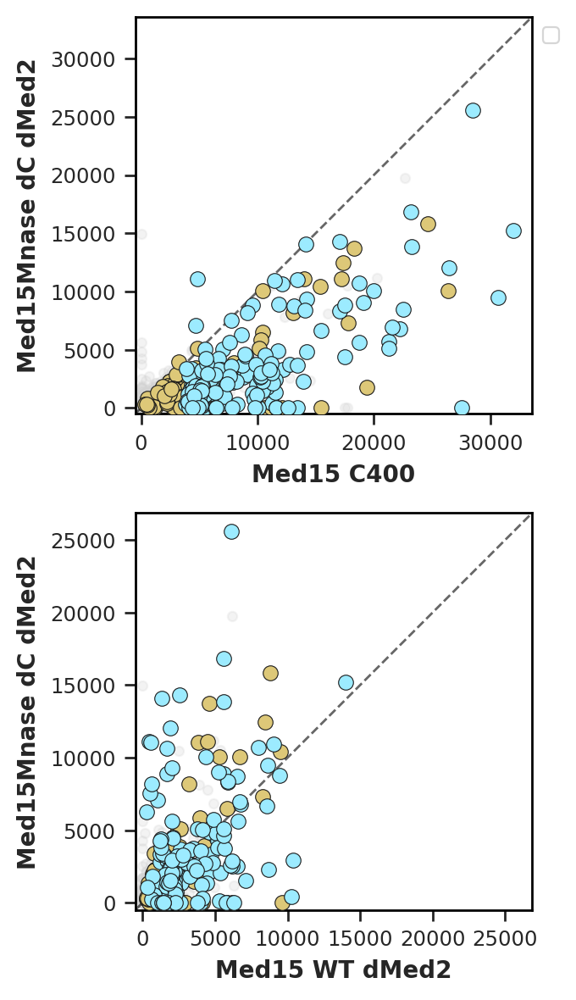

In [101]:
sumprom_base = 'data/sumprom_files/WT_system/sumprom_neg600_to_neg150.pkl.gz'
matching_files = glob.glob(f"{sumprom_base}*")
if not matching_files:
    raise FileNotFoundError(f"No file found matching {sumprom_base}*")

sumprom_path = matching_files[0]
if sumprom_path.endswith('.csv') or sumprom_path.endswith('.csv.gz'):
    WT_system_data = pd.read_csv(sumprom_path, index_col=0)
else:
    WT_system_data = pd.read_pickle(sumprom_path)

# Clean column names and deduplicate index
WT_system_data.columns = [str(c).replace("_2000bp_signals.gz", "") for c in WT_system_data.columns]
WT_system_data = WT_system_data.loc[~WT_system_data.index.duplicated(keep='first')]

fig2, axes2 = plt.subplots(2, 1, figsize=(6, 6))

plot_med_comparison(axes2[0], WT_system_data, 'Med15_C400', 'Med15Mnase_dC_dMed2', lost_in_dc, gained_in_dc)

plot_med_comparison(axes2[1], WT_system_data, 'Med15_WT_dMed2', 'Med15Mnase_dC_dMed2', lost_in_dc, gained_in_dc)

axes2[0].legend(loc='upper left', bbox_to_anchor=(1, 1))


plt.tight_layout()
plt.show()

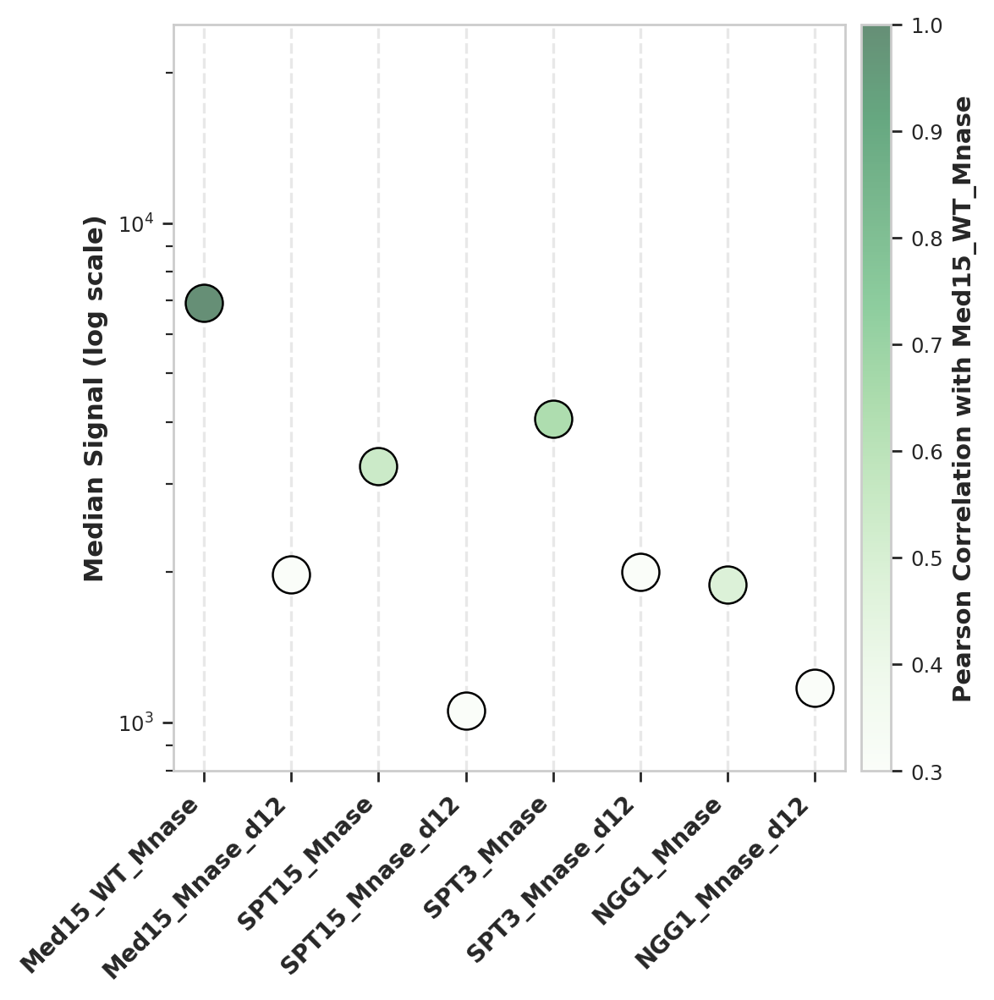

In [98]:

d12_file = 'data/sumprom_files/d12_fusion_system/sumprom_neg600_to_neg150.pkl.gz'
WT_d12 = pd.read_pickle(d12_file)

# Strip single and double underscore variations of the signal suffix
WT_d12.columns = [
    str(c).replace("__2000bp_signals.gz", "").replace("_2000bp_signals.gz", "")
    for c in WT_d12.columns
]
WT_d12 = WT_d12.loc[~WT_d12.index.duplicated(keep='first')]

paired_order_raw = [
    'Med15_WT_Mnase_2000bp_signals.gz', 'Med15_Mnase_d12_2000bp_signals.gz',
    'SPT15_Mnase_2000bp_signals.gz', 'SPT15_Mnase_d12_2000bp_signals.gz',
    'SPT3_Mnase_2000bp_signals.gz', 'SPT3_Mnase_d12_2000bp_signals.gz',
    'NGG1_Mnase_2000bp_signals.gz', 'NGG1_Mnase_d12_2000bp_signals.gz'
]

# Cleaned column names
paired_order = [
    name.replace('__2000bp_signals.gz', '').replace('_2000bp_signals.gz', '')
    for name in paired_order_raw
]
valid_cols = [c for c in paired_order if c in WT_d12.columns]

# =====================================================================
# 2. TARGET SELECTION, MEDIANS & CORRELATIONS
# =====================================================================
if 'top_200_med15_targets' in globals():
    target_genes = top_200_med15_targets
elif 'med15_top_targets' in globals():
    target_genes = med15_top_targets
else:
    # Fallback to top 200 by WT signal if variable is not in namespace
    target_genes = WT_d12['Med15_WT_Mnase'].sort_values(ascending=False).head(200).index

df_sub = WT_d12[valid_cols].loc[WT_d12.index.intersection(target_genes)].dropna()

median_series = df_sub.median()
WT_ref_col = 'Med15_WT_Mnase'
corr_series = df_sub.corr()[WT_ref_col]

plot_df = pd.DataFrame({
    'strain': valid_cols,
    'median_signal': [median_series[c] for c in valid_cols],
    'corr_to_WT': [corr_series[c] for c in valid_cols]
})

# =====================================================================
# 3. PLOTTING
# =====================================================================
norm = Normalize(vmin=0.3, vmax=1.0)
cmap_choice = pastel_cmap if 'pastel_cmap' in globals() else cm.viridis

fig, ax = plt.subplots(figsize=(6, 6))

for i in range(len(valid_cols)):
    ax.axvline(x=i, color='lightgrey', linestyle='--', alpha=0.5, zorder=1)

for i, row in plot_df.iterrows():
    if pd.isna(row['median_signal']):
        continue
    ax.scatter(
        x=i,
        y=row['median_signal'],
        color=cmap_choice(norm(row['corr_to_WT'])),
        edgecolor='black',
        s=250,
        linewidth=0.9,
        zorder=10,
        rasterized=True
    )

ax.set_yscale('log')
ax.set_ylim(800, 25000)

ax.set_xticks(range(len(valid_cols)))
ax.set_xticklabels(valid_cols, rotation=45, ha='right', fontsize=10, fontweight='bold')
ax.set_ylabel('Median Signal (log scale)', fontsize=11, fontweight='bold')

for spine in ax.spines.values():
    spine.set_linewidth(1.0)

sm = cm.ScalarMappable(norm=norm, cmap=cmap_choice)
cbar = fig.colorbar(sm, ax=ax, pad=0.02, aspect=25)
cbar.set_label(f"Pearson Correlation with {WT_ref_col}", fontsize=10.5, fontweight='bold')

plt.tight_layout()
plt.grid(False)
plt.show()

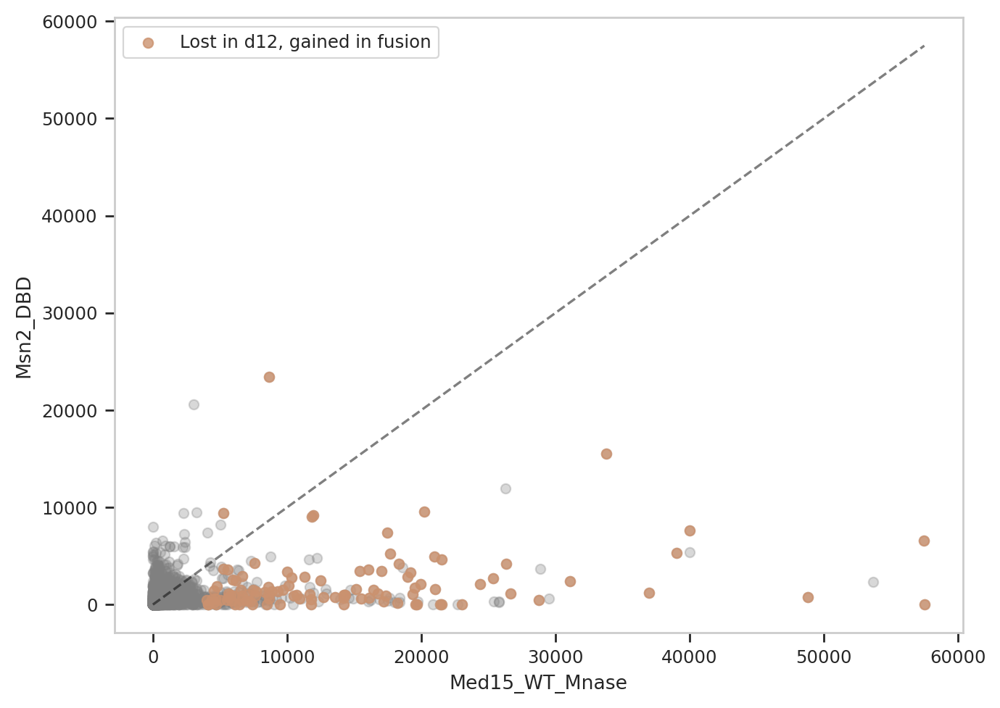

In [105]:
Sup_2C = WT_d12[['Msn2_DBD', 'Med15_WT_Mnase']]
fig, ax = plt.subplots(1, 1, figsize=(7, 5))


max_val = max(Sup_2C['Msn2_DBD'].max(), Sup_2C['Med15_WT_Mnase'].max())

ax.scatter(Sup_2C['Med15_WT_Mnase'], Sup_2C['Msn2_DBD'], 
        alpha=0.3, 
        color='grey'
    )
ax.scatter(
        Sup_2C['Med15_WT_Mnase'].loc[targets_lost_rescued], 
        Sup_2C['Msn2_DBD'].loc[targets_lost_rescued],
        alpha=0.8, 
        color='#CB926F', edgecolor='#CB926F',
        label='Lost in d12, gained in fusion'
    )

ax.plot([0, max_val], [0, max_val], '--', color='black', alpha=0.5)
    
ax.set_ylabel('Msn2_DBD')
ax.set_xlabel('Med15_WT_Mnase')
ax.legend()

plt.tight_layout()
plt.grid(False)
plt.show()